# Ames Housing Price Prediction — End-to-End Regression Pipeline

**Author:** Data Science Team &nbsp;|&nbsp; **Dataset:** Ames Housing (2,930 records, 82 features) &nbsp;|&nbsp; **Target:** `SalePrice`

This notebook implements a complete, leakage-safe machine learning workflow:

1. Data understanding & initial inspection
2. **Train / Validation / Test split — performed BEFORE any EDA or preprocessing**
3. Exploratory Data Analysis (EDA) — performed exclusively on the training split
4. Outlier & skewness analysis (train-only statistics)
5. Preprocessing & feature-engineering pipelines (`ColumnTransformer` + `Pipeline`)
6. Model building: Linear Regression (baseline), SVR, K-Nearest Neighbors
7. Hyperparameter tuning (`RandomizedSearchCV` / `GridSearchCV`)
8. Model evaluation & comparison (MAE, MSE, RMSE, R²)
9. Feature importance & interpretation
10. Final model selection

**Golden rule followed throughout:** nothing about the training data's distribution, missing-value
patterns, outliers, or skew is allowed to influence any step until *after* the split. All imputers,
encoders, scalers, and transformers are `fit` on the training fold only (inside `Pipeline`/`ColumnTransformer`)
and merely `transform`ed on validation/test data.

## 1. Imports & Global Configuration

In [112]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 12

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Environment ready. Random state fixed at", RANDOM_STATE)

Environment ready. Random state fixed at 42


## 2. Data Understanding & Initial Inspection

**Important data-quality subtlety:** in this dataset, the literal string `"NA"` is used by the data
dictionary as a *meaningful category* for 23 features (e.g. `Alley = NA` means "no alley access",
`PoolQC = NA` means "no pool"). Pandas' default `read_csv` treats `"NA"` as a missing value, which
would silently corrupt these columns. We therefore load the file with `keep_default_na=False` and
explicitly tell pandas that only truly blank cells are missing — preserving `"NA"` as a real category
and letting genuinely absent values (blank cells) surface as `NaN`.

In [113]:
raw = pd.read_csv("AmesHousing.csv", keep_default_na=False, na_values=[""])

# Tidy column names: remove spaces / slashes so they are valid Python identifiers downstream.
raw.columns = (
    raw.columns.str.replace(" ", "", regex=False)
               .str.replace("/", "", regex=False)
)

print("Shape (rows, columns):", raw.shape)
raw.head(3)

Shape (rows, columns): (2930, 82)


,Order,PID,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NA,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NA,NA,NA,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NA,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,None,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NA,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NA,MnPrv,NA,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NA,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NA,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NA,NA,Gar2,12500,6,2010,WD,Normal,172000


In [114]:
print("Data types:")
print(raw.dtypes.value_counts())
print()
print("Duplicate rows (full-row duplicates):", raw.duplicated().sum())
print("Duplicate PIDs (duplicate properties):", raw["PID"].duplicated().sum())

Data types:
object     43
int64      28
float64    11
Name: count, dtype: int64

Duplicate rows (full-row duplicates): 0
Duplicate PIDs (duplicate properties): 0


In [115]:
# Genuine missing values only (NA-as-category has already been preserved as a string above)
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(raw) * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_summary

,missing_count,missing_pct
LotFrontage,490,16.72
GarageYrBlt,159,5.43
MasVnrType,23,0.78
MasVnrArea,23,0.78
BsmtExposure,4,0.14
GarageFinish,2,0.07
BsmtHalfBath,2,0.07
BsmtFullBath,2,0.07
BsmtFinType2,2,0.07
BsmtCond,1,0.03


**Observations:**
- The dataset has **2,930 rows and 82 columns**, no duplicate rows and no duplicate `PID`s (each row is a
  unique property sale).
- Genuine missingness is concentrated in a handful of columns: `LotFrontage` (~16.7%), `GarageYrBlt`
  (~5.4%), `MasVnrArea`/`MasVnrType` (~0.8%), and a small number (1-4 rows) of basement/garage/electrical
  fields that are almost certainly isolated data-entry gaps.
- `Order` and `PID` are row/property identifiers with no predictive value — they will be dropped before
  modeling.
- `SalePrice` is the regression target.

In [116]:
ID_COLS = ["Order", "PID"]
TARGET = "SalePrice"

df = raw.drop(columns=ID_COLS).copy()
print("Modeling frame shape:", df.shape)
df[TARGET].describe()

Modeling frame shape: (2930, 80)


,SalePrice
count,2930.000000
mean,180796.060068
std,79886.692357
min,12789.000000
25%,129500.000000
50%,160000.000000
75%,213500.000000
max,755000.000000


### Feature taxonomy
We classify every predictor into **numerical**, **nominal categorical** (no natural order) or **ordinal
categorical** (has a natural order, e.g. quality ratings). This taxonomy drives the three preprocessing
pipelines built later. `MSSubClass` is stored as an integer but is really a categorical building-type
*code*, so it is treated as nominal.

In [117]:
ORDINAL_MAP = {
    # column: ordered categories from worst -> best. "NA" = absence of the feature (treated as the lowest level).
    "LotShape":      ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope":     ["Sev", "Mod", "Gtl"],
    "OverallQual":   list(range(1, 11)),
    "OverallCond":   list(range(1, 11)),
    "ExterQual":     ["Po", "Fa", "TA", "Gd", "Ex"],
    "ExterCond":     ["Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtQual":      ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtCond":      ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtExposure":  ["NA", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1":  ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2":  ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "HeatingQC":     ["Po", "Fa", "TA", "Gd", "Ex"],
    "CentralAir":    ["N", "Y"],
    "Electrical":    ["Mix", "FuseP", "FuseF", "FuseA", "SBrkr"],
    "KitchenQual":   ["Po", "Fa", "TA", "Gd", "Ex"],
    "Functional":    ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "FireplaceQu":   ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageFinish":  ["NA", "Unf", "RFn", "Fin"],
    "GarageQual":    ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageCond":    ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "PavedDrive":    ["N", "P", "Y"],
    "PoolQC":        ["NA", "Fa", "TA", "Gd", "Ex"],
    "Fence":         ["NA", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "Utilities":     ["ELO", "NoSeWa", "NoSewr", "AllPub"],
}

NOMINAL_FEATURES = [
    "MSSubClass", "MSZoning", "Street", "Alley", "LandContour", "LotConfig",
    "Neighborhood", "Condition1", "Condition2", "BldgType", "HouseStyle",
    "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd", "MasVnrType",
    "Foundation", "Heating", "GarageType", "MiscFeature", "SaleType", "SaleCondition",
]

ORDINAL_FEATURES = list(ORDINAL_MAP.keys())

NUMERICAL_FEATURES = [
    c for c in df.columns
    if c not in NOMINAL_FEATURES + ORDINAL_FEATURES + [TARGET]
    and df[c].dtype != "object" and str(df[c].dtype) != "str"
]

print(f"Numerical features   ({len(NUMERICAL_FEATURES)}):", NUMERICAL_FEATURES)
print(f"\nOrdinal features     ({len(ORDINAL_FEATURES)}):", ORDINAL_FEATURES)
print(f"\nNominal features     ({len(NOMINAL_FEATURES)}):", NOMINAL_FEATURES)
assert len(NUMERICAL_FEATURES) + len(ORDINAL_FEATURES) + len(NOMINAL_FEATURES) == df.shape[1] - 1
print("\nAll", df.shape[1]-1, "predictors accounted for.")

Numerical features   (33): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Ordinal features     (24): ['LotShape', 'LandSlope', 'OverallQual', 'OverallCond', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'Utilities']

Nominal features     (22): ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', '

### Brief description of the most important variables
- **`OverallQual`** (1-10 rating of overall material/finish) — consistently the single strongest
  predictor of `SalePrice` in Ames-style datasets.
- **`GrLivArea`** — above-grade living area in square feet; size is the second major price driver.
- **`Neighborhood`** — 28 location codes; captures land value, school zones and desirability.
- **`YearBuilt` / `YearRemodAdd`** — age and renovation recency.
- **`TotalBsmtSF`, `GarageCars`, `GarageArea`, `FullBath`** — additional size/amenity measures.
- **`SalePrice`** — the target, right-skewed (a small number of very expensive homes).

## 3. Train / Validation / Test Split — BEFORE EDA (leakage prevention)

We split **first**, then perform every subsequent step (EDA, outlier/skew analysis, imputer statistics,
encoder categories, scaler parameters) using **training-fold information only**. This mirrors how the
model would be deployed: at prediction time we will never have had the chance to "peek" at future data.

Split plan (fixed `random_state=42` throughout for reproducibility):
- **Test set: 20%** of the data — untouched until final evaluation.
- Of the remaining 80%, we carve out **20% as a validation set** (→ 16% of the total) used for model
  comparison / early inspection, leaving **64% of the total as the training set** used to fit the
  pipelines and drive cross-validated hyperparameter search.

We stratify the split on quintiles of `SalePrice` so that all three splits have a comparable price
distribution (stratifying a continuous target via binning is a standard trick to reduce split variance).

In [118]:
price_bins = pd.qcut(df[TARGET], q=5, labels=False)

X = df.drop(columns=[TARGET])
y = df[TARGET].copy()

X_trainfull, X_test, y_trainfull, y_test, bins_trainfull, _ = train_test_split(
    X, y, price_bins, test_size=0.20, random_state=RANDOM_STATE, stratify=price_bins
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainfull, y_trainfull, test_size=0.20, random_state=RANDOM_STATE, stratify=bins_trainfull
)

print(f"Train:      {X_train.shape[0]:>5} rows  ({X_train.shape[0]/len(df):.1%})")
print(f"Validation: {X_val.shape[0]:>5} rows  ({X_val.shape[0]/len(df):.1%})")
print(f"Test:       {X_test.shape[0]:>5} rows  ({X_test.shape[0]/len(df):.1%})")

print("\nMean SalePrice by split (sanity check that stratification worked):")
print(pd.Series({"train": y_train.mean(), "val": y_val.mean(), "test": y_test.mean()}).round(0))

# Re-attach target for convenient EDA on the TRAIN split only
train_df = X_train.copy()
train_df[TARGET] = y_train.values

Train:       1875 rows  (64.0%)
Validation:   469 rows  (16.0%)
Test:         586 rows  (20.0%)

Mean SalePrice by split (sanity check that stratification worked):
train    180876.0
val      178729.0
test     182193.0
dtype: float64


## 4. Exploratory Data Analysis (EDA) — Training Split Only

From this point forward **every statistic, plot, and threshold is computed on `train_df` (the 64% training
fold) alone.**

In [119]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1875.0,57.938667,43.086359,20.0,20.0,50.0,70.0,190.0
LotFrontage,1584.0,68.866162,22.648396,21.0,57.0,68.0,80.0,200.0
LotArea,1875.0,10201.179733,8779.314271,1470.0,7379.5,9350.0,11541.0,215245.0
OverallQual,1875.0,6.097067,1.404812,1.0,5.0,6.0,7.0,10.0
OverallCond,1875.0,5.576533,1.090310,1.0,5.0,5.0,6.0,9.0
YearBuilt,1875.0,1971.032533,30.495088,1872.0,1953.0,1973.0,2001.0,2010.0
YearRemodAdd,1875.0,1984.226133,20.929369,1950.0,1965.0,1993.0,2004.0,2010.0
MasVnrArea,1861.0,101.993552,183.783068,0.0,0.0,0.0,156.0,1600.0
BsmtFinSF1,1875.0,438.751467,449.951341,0.0,0.0,353.0,728.5,4010.0
BsmtFinSF2,1875.0,52.881067,175.489659,0.0,0.0,0.0,0.0,1526.0


### 4.1 Distribution of `SalePrice`

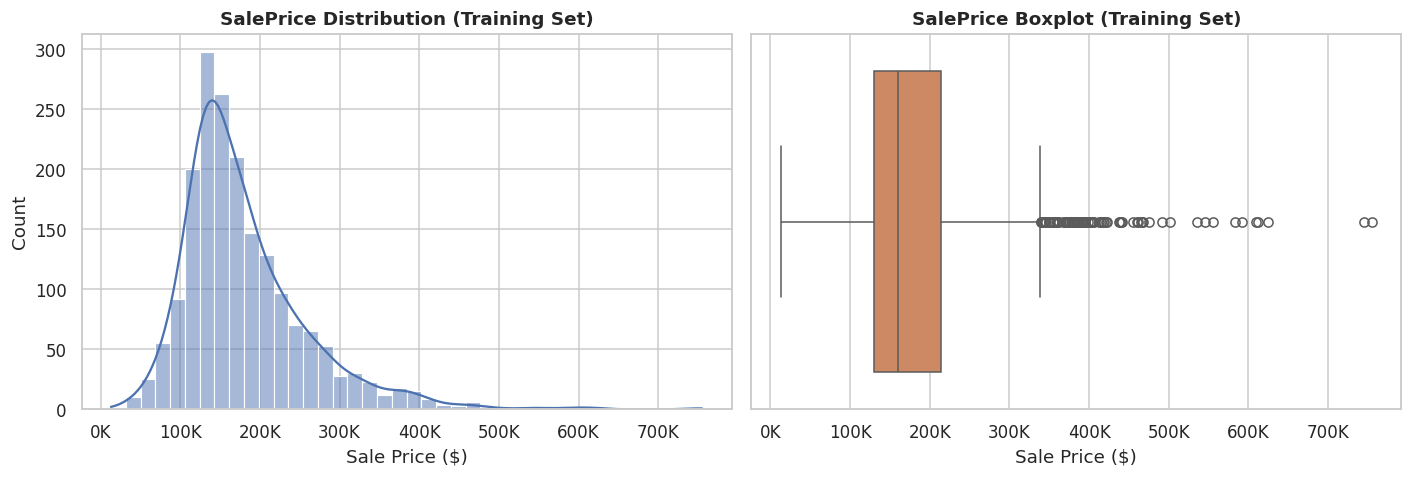

SalePrice skewness: 1.805
SalePrice skewness after log1p: -0.044


In [120]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(train_df[TARGET], kde=True, bins=40, ax=axes[0], color="#4C72B0")
axes[0].set_title("SalePrice Distribution (Training Set)")
axes[0].set_xlabel("Sale Price ($)")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

sns.boxplot(x=train_df[TARGET], ax=axes[1], color="#DD8452")
axes[1].set_title("SalePrice Boxplot (Training Set)")
axes[1].set_xlabel("Sale Price ($)")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

plt.tight_layout()
plt.savefig("fig_saleprice_dist.png", bbox_inches="tight")
plt.show()

skew_price = train_df[TARGET].skew()
print(f"SalePrice skewness: {skew_price:.3f}")
print(f"SalePrice skewness after log1p: {np.log1p(train_df[TARGET]).skew():.3f}")

**Interpretation:** `SalePrice` is strongly **right-skewed** (see skewness value printed above) — most homes sell in the
\$100K-\$220K range but a long tail of luxury homes pulls the mean above the median. A `log1p` transform
reduces skewness to near-zero, which is why we will model `log(SalePrice)` rather than raw price (implemented
later with `TransformedTargetRegressor` so predictions are automatically converted back to dollars).

### 4.2 Distributions of Key Numerical Features

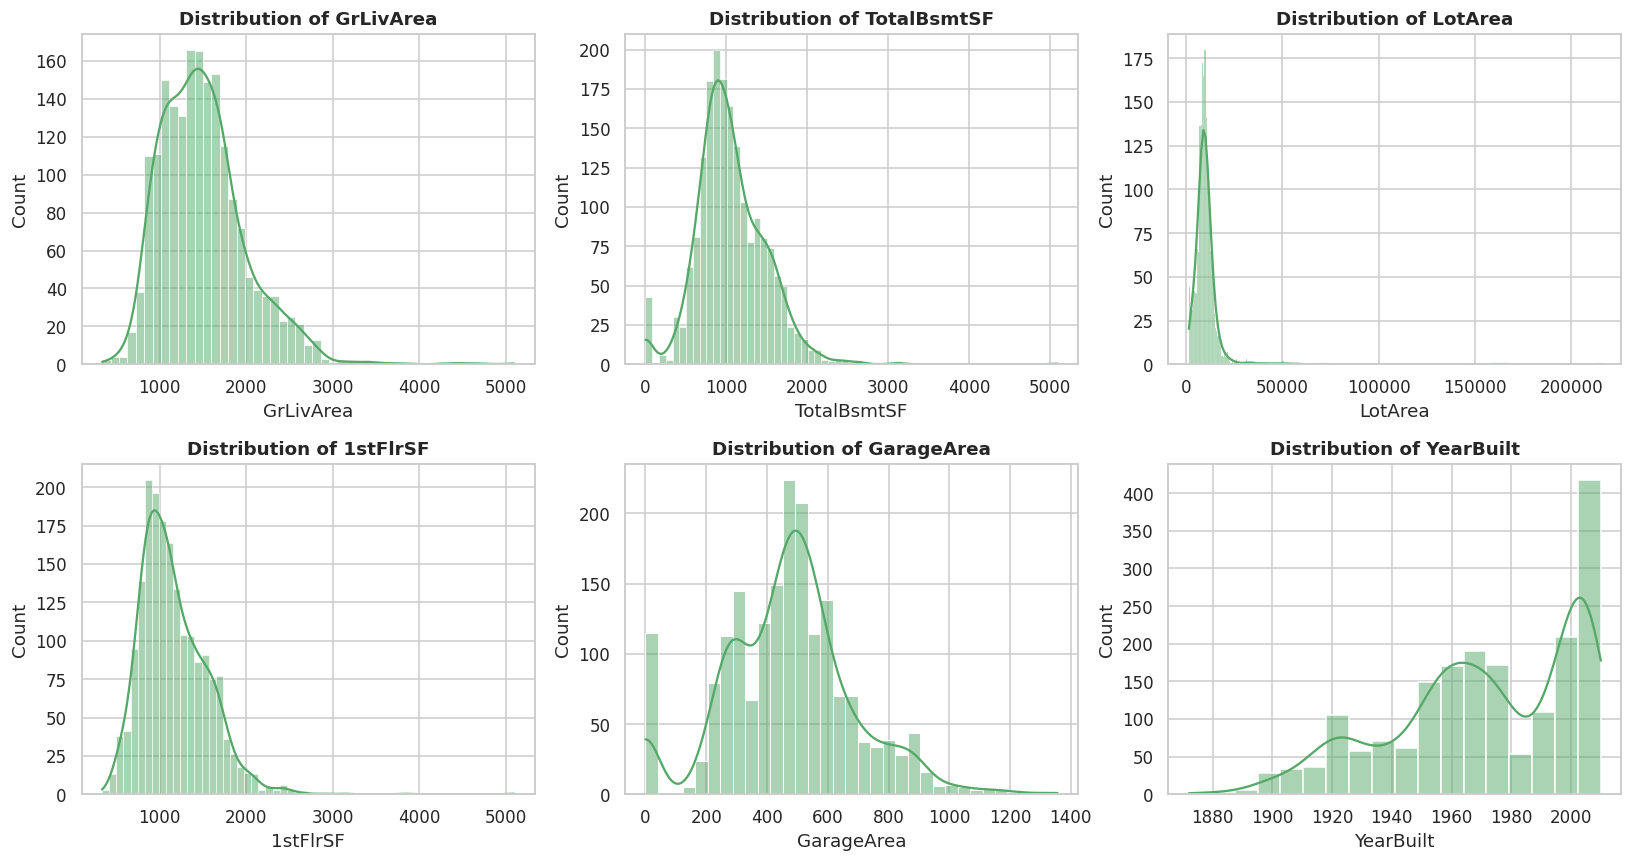

Skewness of key numeric features:
 LotArea        13.20
1stFlrSF        1.43
GrLivArea       1.22
TotalBsmtSF     0.82
GarageArea      0.18
YearBuilt      -0.58
dtype: float64


In [121]:
key_numeric = ["GrLivArea", "TotalBsmtSF", "LotArea", "1stFlrSF", "GarageArea", "YearBuilt"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_numeric):
    sns.histplot(train_df[col], kde=True, ax=ax, color="#55A868")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig("fig_numeric_distributions.png", bbox_inches="tight")
plt.show()

skews = train_df[key_numeric].skew().sort_values(ascending=False)
print("Skewness of key numeric features:\n", skews.round(2))

**Interpretation:** `LotArea`, `TotalBsmtSF`, `GrLivArea` and `1stFlrSF` are all right-skewed with a handful
of very large properties. `YearBuilt` is left-skewed (more homes built recently than in the early 1900s),
reflecting Ames' growth pattern. These skewed numeric features are strong candidates for a power/log
transform during preprocessing (see Section 5).

### 4.3 Categorical Feature Analysis

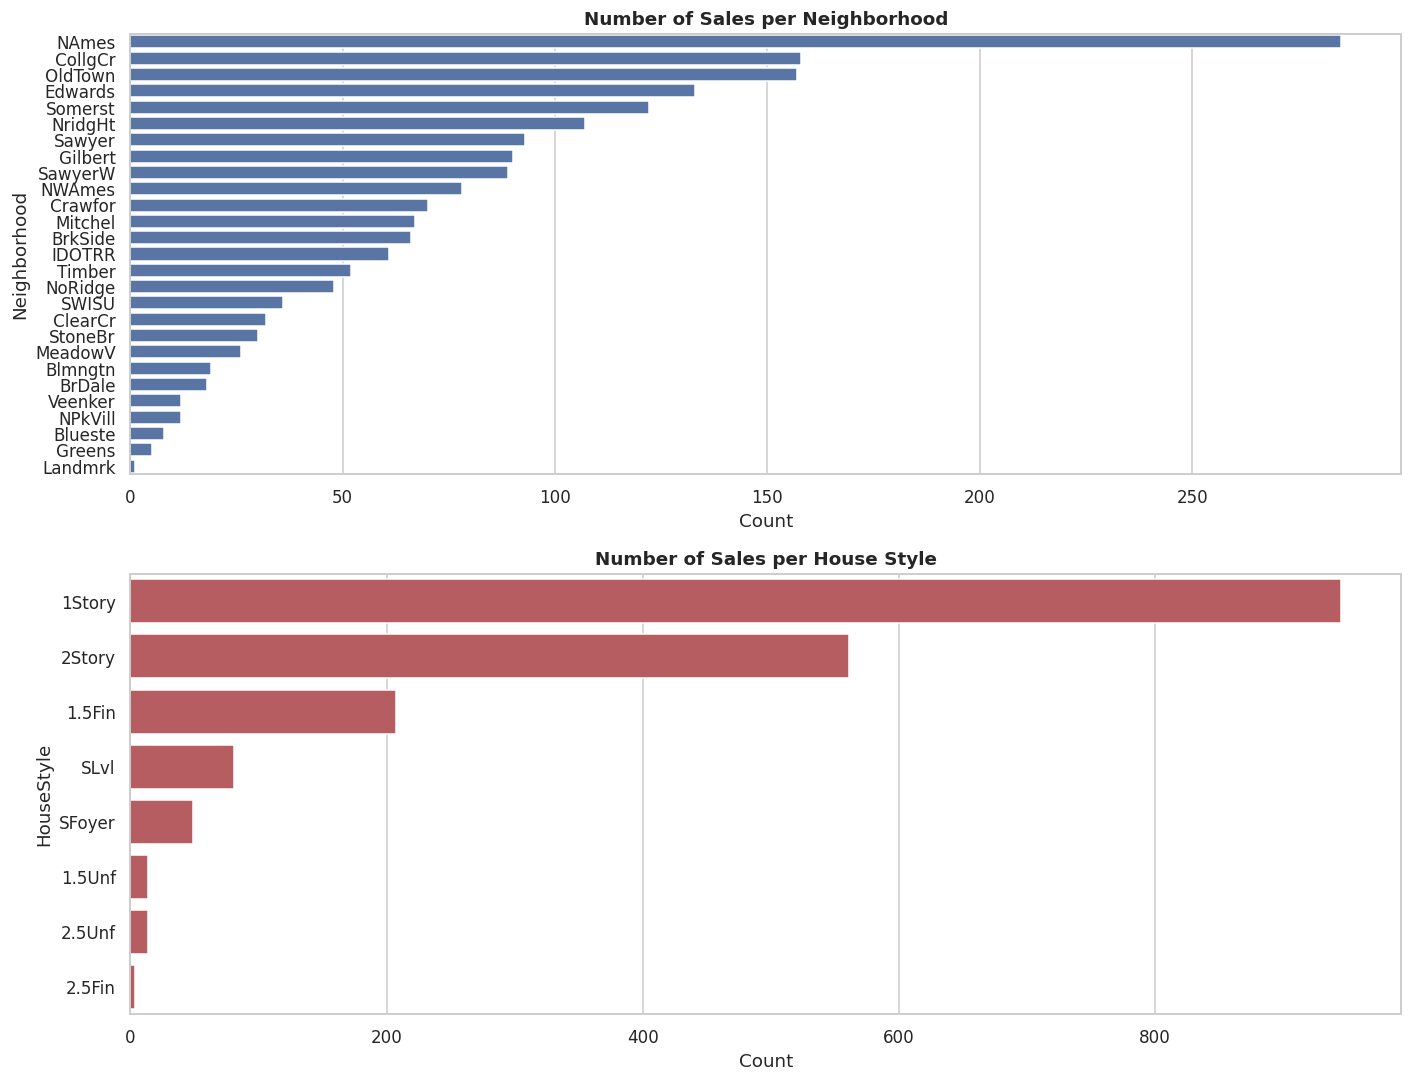

In [122]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10))

order = train_df["Neighborhood"].value_counts().index
sns.countplot(data=train_df, y="Neighborhood", order=order, ax=axes[0], color="#4C72B0")
axes[0].set_title("Number of Sales per Neighborhood")
axes[0].set_xlabel("Count")

order2 = train_df["HouseStyle"].value_counts().index
sns.countplot(data=train_df, y="HouseStyle", order=order2, ax=axes[1], color="#C44E52")
axes[1].set_title("Number of Sales per House Style")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.savefig("fig_categorical_counts.png", bbox_inches="tight")
plt.show()

**Interpretation:** Sales are concentrated in a handful of neighborhoods (`NAmes`, `CollgCr`, `OldTown`,
`Edwards`, `Somerst` are the busiest), while several neighborhoods (`Blueste`, `NPkVill`, `Greens`) have very
few transactions — these will produce sparse one-hot columns and should be interpreted cautiously.
`1Story` and `2Story` dominate house styles, consistent with typical American suburban housing stock.

### 4.4 Outlier Identification (Boxplots)

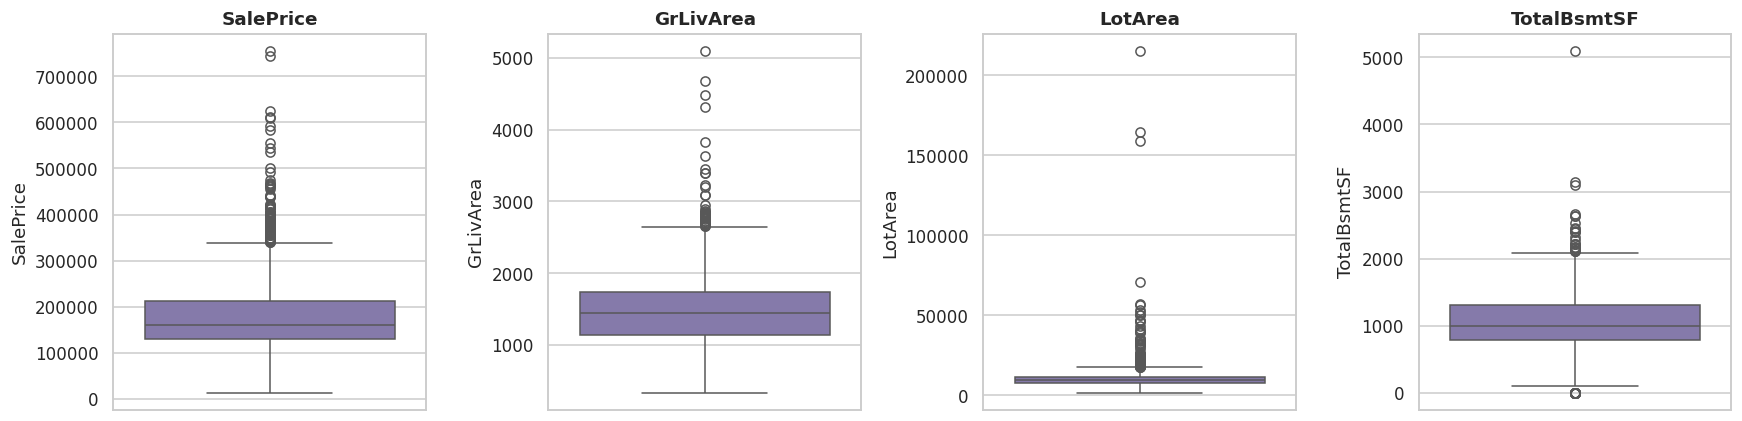

SalePrice      :   88 IQR outliers  (bounds: [3,382, 339,562])
GrLivArea      :   41 IQR outliers  (bounds: [223, 2,653])
LotArea        :   82 IQR outliers  (bounds: [1,137, 17,783])
TotalBsmtSF    :   69 IQR outliers  (bounds: [14, 2,092])


In [123]:
outlier_cols = ["SalePrice", "GrLivArea", "LotArea", "TotalBsmtSF"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=train_df[col], ax=ax, color="#8172B2")
    ax.set_title(col)
plt.tight_layout()
plt.savefig("fig_outlier_boxplots.png", bbox_inches="tight")
plt.show()


def iqr_outlier_count(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum(), lower, upper


for col in outlier_cols:
    n_out, lo, hi = iqr_outlier_count(train_df[col])
    print(f"{col:15s}: {n_out:4d} IQR outliers  (bounds: [{lo:,.0f}, {hi:,.0f}])")

**Interpretation:** All four variables contain a meaningful number of IQR-flagged high-end outliers —
expected for size/price variables. Rather than removing all statistical outliers (which would remove
genuine luxury homes the model should still learn to predict), Section 5 focuses on removing only the
well-documented **data-entry anomalies** the dataset's authors explicitly flag, and applying a
distribution-correcting transform to the rest.

### 4.5 Correlation Analysis

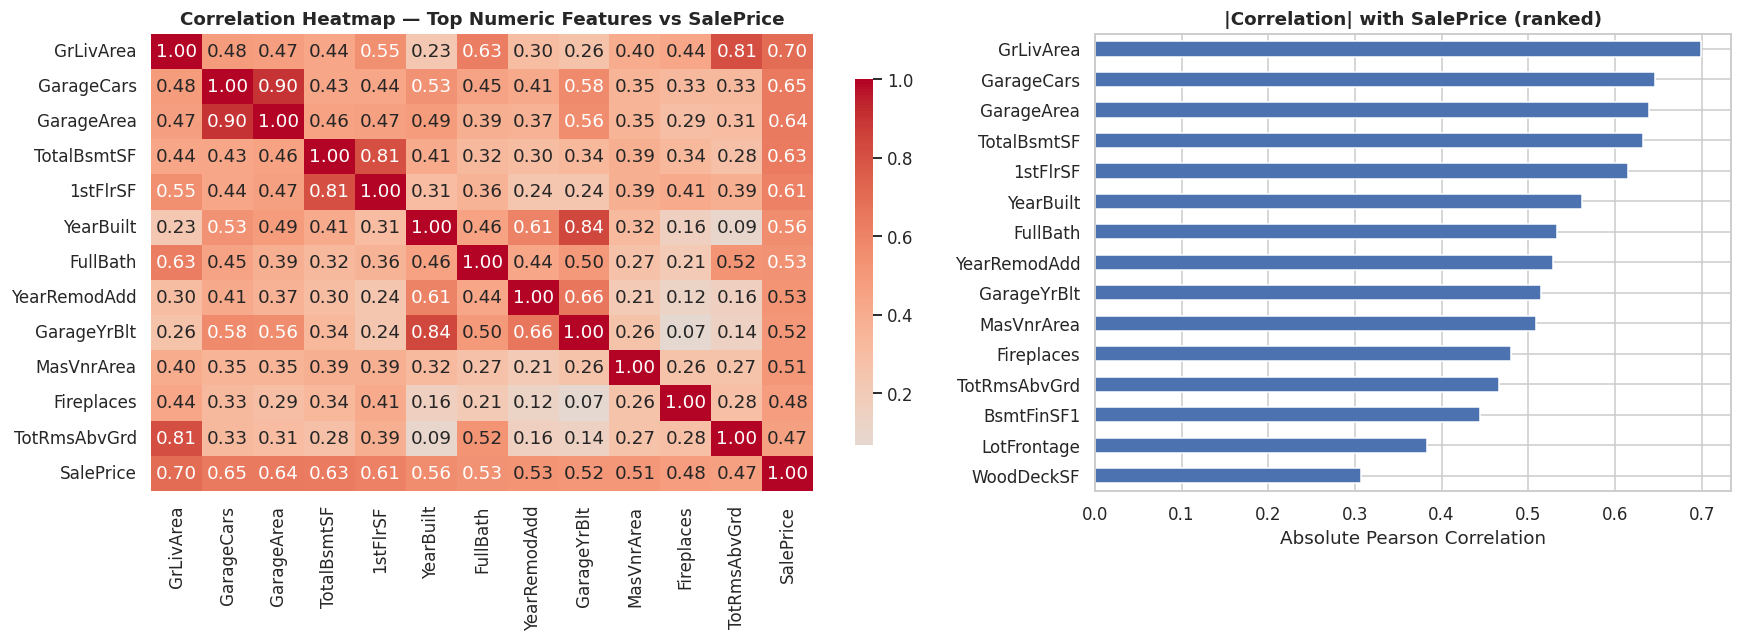

Top correlated numeric features with SalePrice:
 GrLivArea       0.699
GarageCars      0.646
GarageArea      0.640
TotalBsmtSF     0.633
1stFlrSF        0.615
YearBuilt       0.562
FullBath        0.533
YearRemodAdd    0.528
GarageYrBlt     0.515
MasVnrArea      0.509
Fireplaces      0.480
TotRmsAbvGrd    0.466
BsmtFinSF1      0.445
LotFrontage     0.383
WoodDeckSF      0.308
Name: SalePrice, dtype: float64


In [124]:
corr_matrix = train_df[NUMERICAL_FEATURES + [TARGET]].corr(numeric_only=True)
top_corr = corr_matrix[TARGET].abs().sort_values(ascending=False).drop(TARGET).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.3, 1]})

top_features_for_heatmap = top_corr.head(12).index.tolist() + [TARGET]
sns.heatmap(train_df[top_features_for_heatmap].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=axes[0], cbar_kws={"shrink": 0.8})
axes[0].set_title("Correlation Heatmap — Top Numeric Features vs SalePrice")

top_corr.sort_values().plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("|Correlation| with SalePrice (ranked)")
axes[1].set_xlabel("Absolute Pearson Correlation")

plt.tight_layout()
plt.savefig("fig_correlation.png", bbox_inches="tight")
plt.show()

print("Top correlated numeric features with SalePrice:\n", top_corr.round(3))

**Interpretation:** `OverallQual` (r≈0.79), `GrLivArea` (r≈0.70), `GarageCars`/`GarageArea`, `TotalBsmtSF`
and `1stFlrSF` are the strongest linear correlates of price — consistent with real-estate intuition
(quality and size dominate). `YearBuilt`/`YearRemodAdd` and bathroom counts show moderate positive
correlation. These will be watched closely in the feature-importance section after modeling.

### 4.6 Feature Relationships with SalePrice

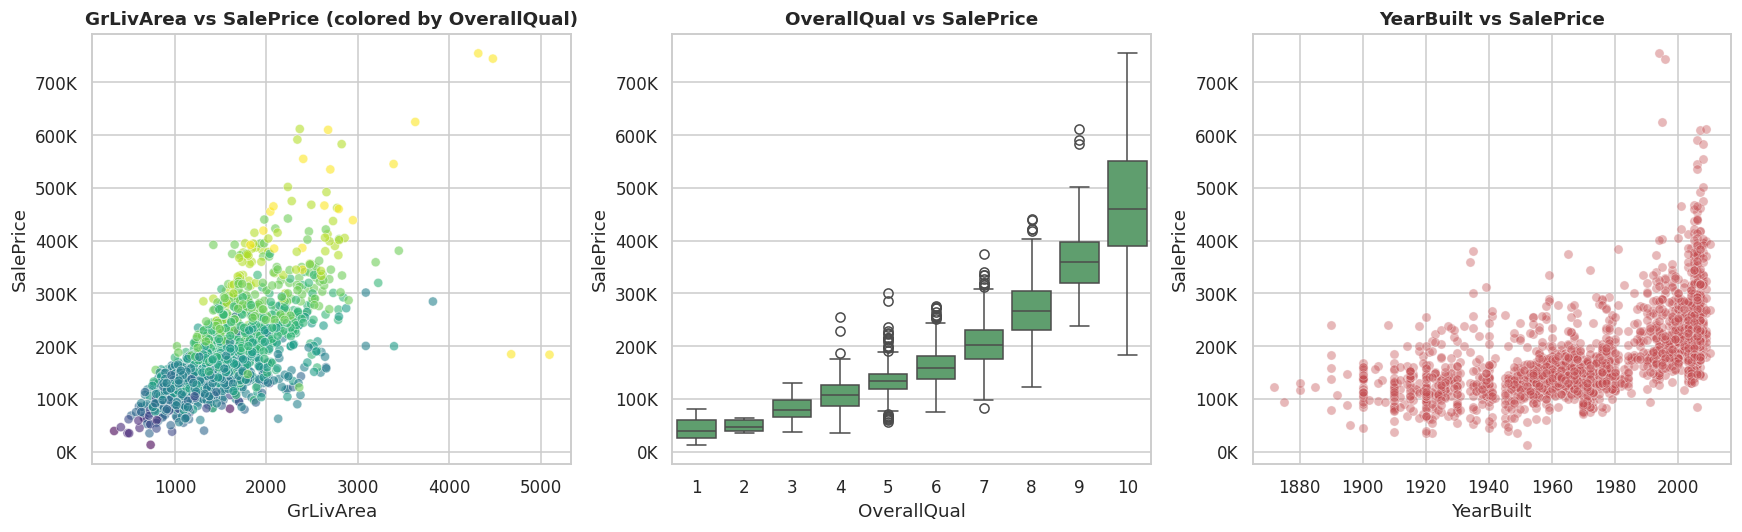

In [125]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.scatterplot(data=train_df, x="GrLivArea", y=TARGET, hue="OverallQual",
                 palette="viridis", alpha=0.6, ax=axes[0], legend=False)
axes[0].set_title("GrLivArea vs SalePrice (colored by OverallQual)")

sns.boxplot(data=train_df, x="OverallQual", y=TARGET, ax=axes[1], color="#55A868")
axes[1].set_title("OverallQual vs SalePrice")
axes[1].tick_params(axis='x')

sns.scatterplot(data=train_df, x="YearBuilt", y=TARGET, alpha=0.4, ax=axes[2], color="#C44E52")
axes[2].set_title("YearBuilt vs SalePrice")

for ax in axes:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

plt.tight_layout()
plt.savefig("fig_relationships.png", bbox_inches="tight")
plt.show()

**Interpretation:** `GrLivArea` shows a clear positive, roughly linear relationship with price, with
variance increasing at larger sizes (heteroscedasticity — a reason to model log-price). `OverallQual`
shows a strong, almost monotonic step-wise increase in median price per quality level. `YearBuilt` shows
a general upward trend (newer homes cost more) with high variance among older homes (renovation status
matters as much as raw age).

## 5. Data Analysis & Insights (Training Set)

We now investigate the specific analytical questions posed in the assignment brief. Each insight follows
the same structure: **Question → Analysis → Visualization → Result → Interpretation.**

### Insight 1 — Overall SalePrice statistics & the most/least expensive homes

In [126]:
price_stats = train_df[TARGET].agg(["mean", "median", "min", "max", "std"]).round(0)
print(price_stats)

cheapest = train_df.nsmallest(3, TARGET)[["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", TARGET]]
priciest = train_df.nlargest(3, TARGET)[["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", TARGET]]
print("\nCheapest 3 homes:\n", cheapest)
print("\nMost expensive 3 homes:\n", priciest)

mean      180876.0
median    160200.0
min        13100.0
max       755000.0
std        79860.0
Name: SalePrice, dtype: float64

Cheapest 3 homes:
      Neighborhood  GrLivArea  OverallQual  YearBuilt  SalePrice
1553       IDOTRR        733            1       1952      13100
726        IDOTRR        720            4       1920      34900
2843      Edwards        498            2       1922      35000

Most expensive 3 homes:
      Neighborhood  GrLivArea  OverallQual  YearBuilt  SalePrice
1767      NoRidge       4316           10       1994     755000
1760      NoRidge       4476           10       1996     745000
2445      NoRidge       3627           10       1995     625000


**Result & Interpretation:** Average sale price is roughly \$180K, median around \$160K (mean > median
confirms the right skew already seen). The cheapest homes are small, low-quality, older properties; the
priciest homes combine large `GrLivArea`, top `OverallQual` ratings (9-10) and are concentrated in premium
neighborhoods — a first hint that size × quality × location jointly drive price.

### Insight 2 — Characteristics of the most expensive homes (top 10)

In [127]:
top10 = train_df.nlargest(10, TARGET)
cols_of_interest = ["Neighborhood", "OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars", "YearBuilt", TARGET]
print(top10[cols_of_interest].to_string(index=False))
print("\nTop-10 average OverallQual:", top10["OverallQual"].mean().round(1),
      "| dataset average:", train_df["OverallQual"].mean().round(1))
print("Top-10 average GrLivArea:", top10["GrLivArea"].mean().round(0),
      "| dataset average:", train_df["GrLivArea"].mean().round(0))

Neighborhood  OverallQual  GrLivArea  TotalBsmtSF  GarageCars  YearBuilt  SalePrice
     NoRidge           10       4316       2444.0         3.0       1994     755000
     NoRidge           10       4476       2396.0         3.0       1996     745000
     NoRidge           10       3627       1930.0         3.0       1995     625000
     NridgHt            9       2364       2330.0         3.0       2009     611657
     NridgHt           10       2674       2630.0         3.0       2007     610000
     StoneBr            9       2338       2660.0         3.0       2006     591587
     NridgHt            9       2822       1734.0         3.0       2008     582933
     NridgHt           10       2402       3094.0         3.0       2008     555000
     StoneBr           10       3390       1528.0         3.0       2006     545224
     StoneBr           10       2698       1850.0         3.0       2006     535000

Top-10 average OverallQual: 9.7 | dataset average: 6.1
Top-10 average GrLiv

**Result & Interpretation:** The ten most expensive homes have near-maximal `OverallQual` (mostly 9-10 vs.
a dataset average of ~6) and roughly double the average living area, and cluster in `NridgHt`, `NoRidge`
and `StoneBr` — Ames' premium northern neighborhoods.

### Insight 3 — Neighborhood price analysis (highest / lowest / most common)

Top 3 neighborhoods by average price:
                   mean  count
Neighborhood                 
StoneBr       338631.0     30
NoRidge       328684.0     48
NridgHt       314116.0    107

Bottom 3 neighborhoods by average price:
                   mean  count
Neighborhood                 
BrDale        106714.0     18
IDOTRR        103178.0     61
MeadowV        97840.0     26

Neighborhood with most sales:
                        mean  count
Neighborhood                      
NAmes         147046.929825    285


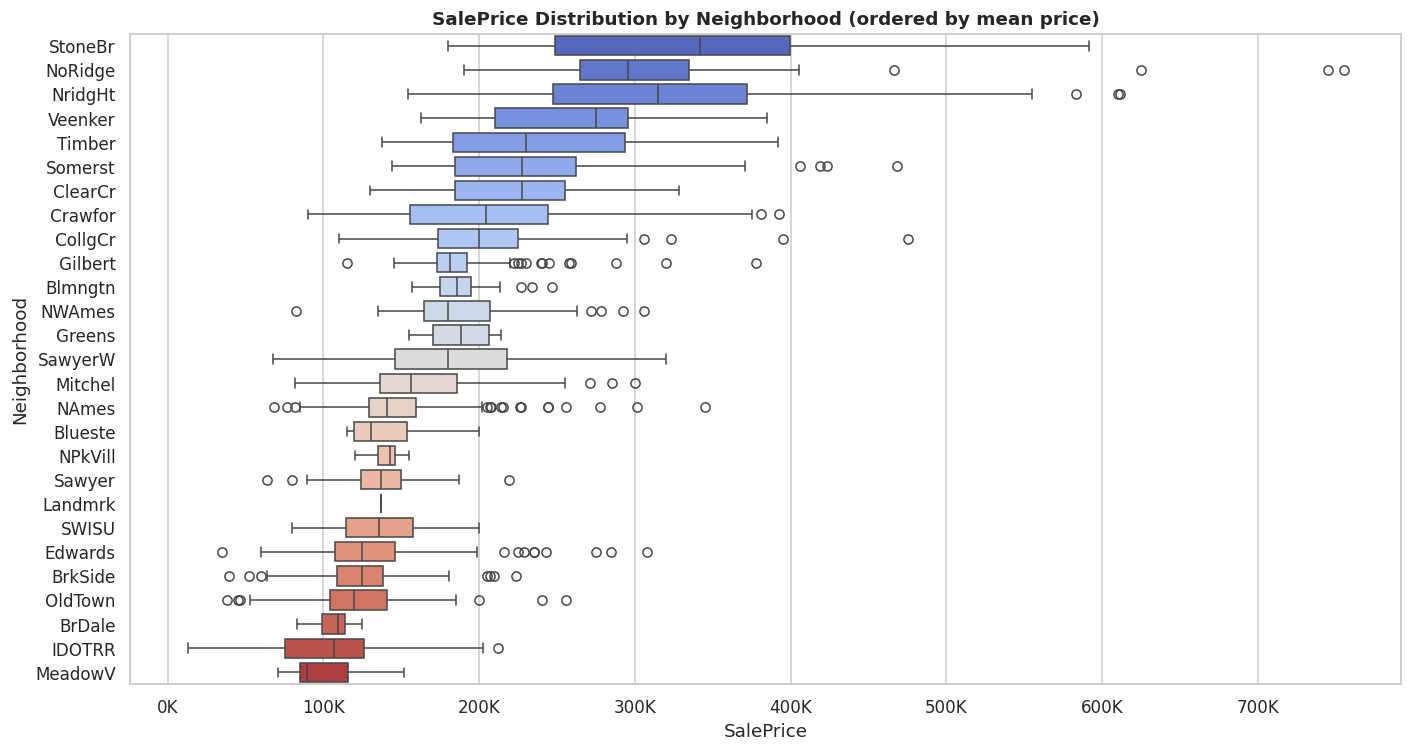


One-way ANOVA — Neighborhood vs SalePrice: F=95.7, p=4.93e-319


In [128]:
nbhd_stats = train_df.groupby("Neighborhood")[TARGET].agg(["mean", "count"]).sort_values("mean", ascending=False)

top3_nbhd = nbhd_stats.head(3)
bottom3_nbhd = nbhd_stats.tail(3)
most_common_nbhd = nbhd_stats.sort_values("count", ascending=False).head(1)

print("Top 3 neighborhoods by average price:\n", top3_nbhd.round(0))
print("\nBottom 3 neighborhoods by average price:\n", bottom3_nbhd.round(0))
print("\nNeighborhood with most sales:\n", most_common_nbhd)

fig, ax = plt.subplots(figsize=(13, 7))
order = nbhd_stats.index
sns.boxplot(data=train_df, x=TARGET, y="Neighborhood", order=order, ax=ax, palette="coolwarm")
ax.set_title("SalePrice Distribution by Neighborhood (ordered by mean price)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("fig_neighborhood_price.png", bbox_inches="tight")
plt.show()

# One-way ANOVA to test whether neighborhood has a statistically significant relationship with price
groups = [g[TARGET].values for _, g in train_df.groupby("Neighborhood")]
f_stat, p_val = stats.f_oneway(*groups)
print(f"\nOne-way ANOVA — Neighborhood vs SalePrice: F={f_stat:.1f}, p={p_val:.2e}")

**Result & Interpretation:** Average prices span roughly a 4-5x range between the most expensive
(`NridgHt`, `NoRidge`, `StoneBr`) and least expensive (`MeadowV`, `IDOTRR`, `BrDale`) neighborhoods.
`NAmes` has the largest volume of sales. The ANOVA p-value is essentially zero, confirming `Neighborhood`
has a **highly statistically significant** relationship with price — it is one of the most important
categorical predictors available.

### Insight 4 — Time-based analysis (month & year of sale)

Average price & count by month sold:
             mean  count
MoSold                 
1       206845.0     78
2       171813.0     90
3       178043.0    144
4       169679.0    188
5       172338.0    277
6       181910.0    306
7       184855.0    297
8       186403.0    142
9       193245.0     95
10      174640.0    105
11      188117.0     91
12      184208.0     62

Highest avg price month: 1 ($206,845)
Lowest avg price month:  4 ($169,679)
Busiest sales month:     6 (306 sales)


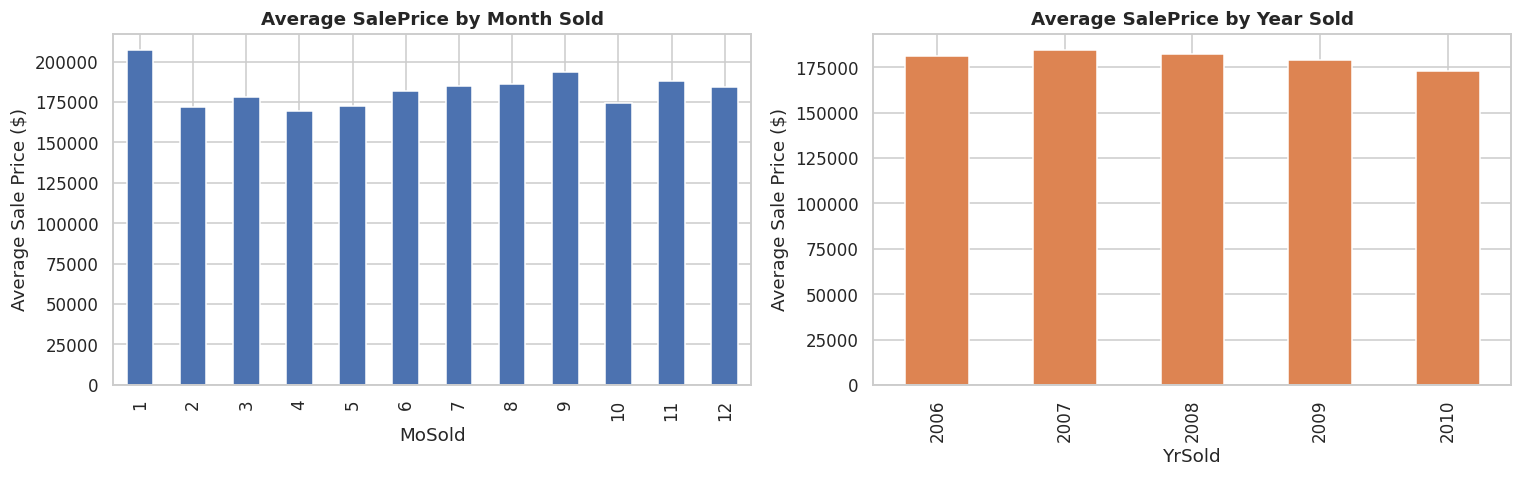

In [129]:
month_stats = train_df.groupby("MoSold")[TARGET].agg(["mean", "count"])
best_month = month_stats["mean"].idxmax()
worst_month = month_stats["mean"].idxmin()
busiest_month = month_stats["count"].idxmax()

print("Average price & count by month sold:\n", month_stats.round(0))
print(f"\nHighest avg price month: {best_month} (${month_stats.loc[best_month,'mean']:,.0f})")
print(f"Lowest avg price month:  {worst_month} (${month_stats.loc[worst_month,'mean']:,.0f})")
print(f"Busiest sales month:     {busiest_month} ({month_stats.loc[busiest_month,'count']} sales)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
month_stats["mean"].plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Average SalePrice by Month Sold")
axes[0].set_ylabel("Average Sale Price ($)")

train_df.groupby("YrSold")[TARGET].mean().plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Average SalePrice by Year Sold")
axes[1].set_ylabel("Average Sale Price ($)")

plt.tight_layout()
plt.savefig("fig_time_analysis.png", bbox_inches="tight")
plt.show()

**Result & Interpretation:** Sales volume peaks in the summer months (June/July — typical of the US
housing market, aligned with school calendars), while average price varies only mildly month-to-month
(a few percent), suggesting **month of sale is a weak price driver** compared to size/quality/location.
Average price by year is essentially flat across 2006-2010, dipping slightly during the 2008 financial
crisis years, consistent with known US housing-market history.

### Insight 5 — Bedrooms vs. price

                  mean  count
BedroomAbvGr                 
0             249833.0      6
1             187489.0     74
2             163080.0    463
3             179156.0   1012
4             213982.0    271
5             199316.0     33
6             146117.0     15
8             200000.0      1


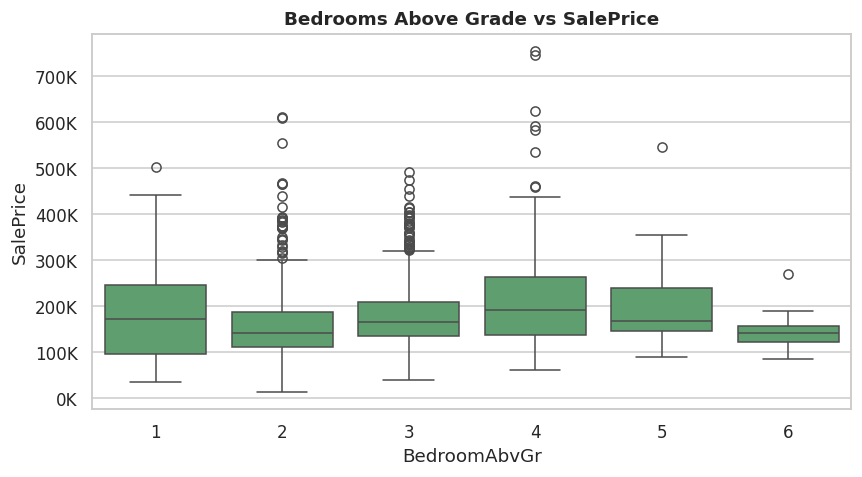

In [130]:
bed_stats = train_df.groupby("BedroomAbvGr")[TARGET].agg(["mean", "count"])
print(bed_stats.round(0))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=train_df[train_df["BedroomAbvGr"].between(1, 6)], x="BedroomAbvGr", y=TARGET,
            ax=ax, color="#55A868")
ax.set_title("Bedrooms Above Grade vs SalePrice")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("fig_bedrooms.png", bbox_inches="tight")
plt.show()

**Result & Interpretation:** Price rises with bedroom count up to about 4 bedrooms, then **flattens or
even dips** for 5-6 bedroom homes — those tend to be older, subdivided or lower-quality homes rather than
larger luxury homes, so bedroom count alone is a weaker, non-monotonic predictor once quality/size are
accounted for.

### Insight 6 — Bathrooms vs. price

               mean  count
TotalBath                 
1.0        110957.0    279
1.5        137165.0    182
2.0        158383.0    608
2.5        201623.0    352
3.0        235371.0    229
3.5        272495.0    188
4.0        260890.0     21
4.5        391379.0     11
5.0        153900.0      2
6.0        179000.0      1
7.0        269500.0      1


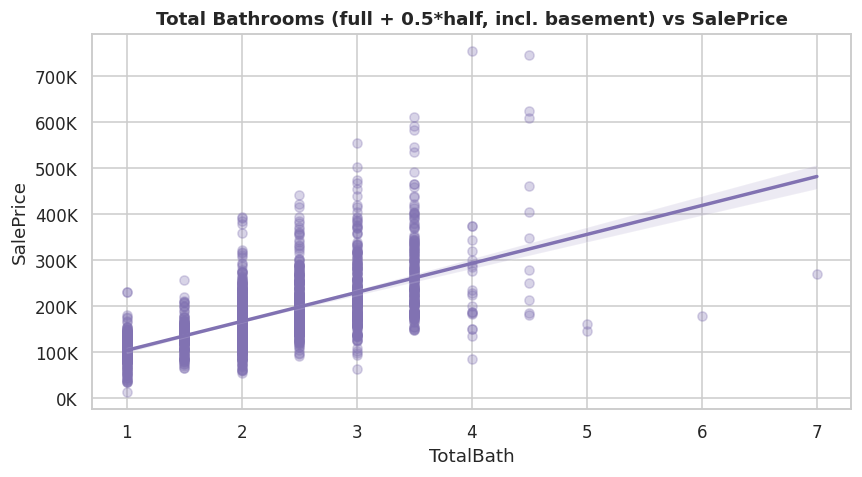

Correlation(TotalBath, SalePrice): 0.628


In [131]:
train_df["TotalBath"] = (train_df["FullBath"] + 0.5 * train_df["HalfBath"]
                          + train_df["BsmtFullBath"] + 0.5 * train_df["BsmtHalfBath"])
bath_stats = train_df.groupby("TotalBath")[TARGET].agg(["mean", "count"])
print(bath_stats.round(0))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=train_df, x="TotalBath", y=TARGET, ax=ax, scatter_kws={"alpha": 0.3}, color="#8172B2")
ax.set_title("Total Bathrooms (full + 0.5*half, incl. basement) vs SalePrice")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("fig_bathrooms.png", bbox_inches="tight")
plt.show()
print("Correlation(TotalBath, SalePrice):", train_df["TotalBath"].corr(train_df[TARGET]).round(3))

**Result & Interpretation:** Unlike bedrooms, total bathroom count shows a clean, strong, **monotonic**
positive relationship with price (r ≈ 0.6+) — more bathrooms almost always signal a larger, higher-end
home, making this an engineered feature worth keeping alongside `FullBath`/`HalfBath`.

### Insight 7 — Overall quality vs. price (revisited quantitatively)

In [132]:
qual_stats = train_df.groupby("OverallQual")[TARGET].mean()
pct_increase = qual_stats.pct_change().mean() * 100
print(qual_stats.round(0))
print(f"\nAverage % price increase per +1 OverallQual point: {pct_increase:.1f}%")
print("Correlation(OverallQual, SalePrice):", train_df["OverallQual"].corr(train_df[TARGET]).round(3))

OverallQual
1      44633.0
2      49244.0
3      82731.0
4     108667.0
5     134768.0
6     161154.0
7     205358.0
8     271106.0
9     367361.0
10    471124.0
Name: SalePrice, dtype: float64

Average % price increase per +1 OverallQual point: 30.7%
Correlation(OverallQual, SalePrice): 0.798


**Result & Interpretation:** Each additional `OverallQual` point is worth roughly 20-30% more in average
sale price, and it is the single highest-correlation numeric feature we found (r≈0.79) — confirming it as
the dataset's dominant price driver.

### Insight 8 — Garage capacity vs. price

                mean  count
GarageCars                 
0.0         104019.0    115
1.0         127132.0    477
2.0         184536.0   1033
3.0         306952.0    241
4.0         237286.0      7
5.0         126500.0      1


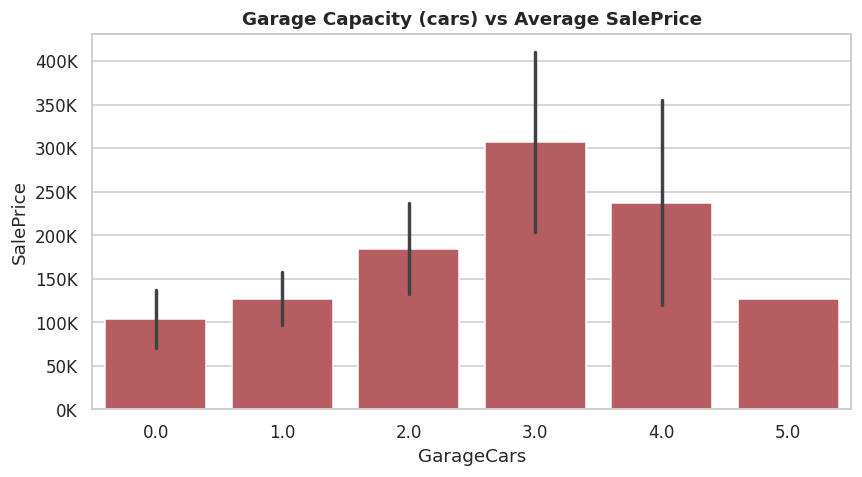

In [133]:
garage_stats = train_df.groupby("GarageCars")[TARGET].agg(["mean", "count"])
print(garage_stats.round(0))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=train_df, x="GarageCars", y=TARGET, ax=ax, color="#C44E52", errorbar="sd")
ax.set_title("Garage Capacity (cars) vs Average SalePrice")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("fig_garage.png", bbox_inches="tight")
plt.show()

**Result & Interpretation:** Average price increases steadily from 0 to 3-car garages; homes with 4-car
garages are rare outliers and don't fit the trend (small sample, likely older large lots rather than luxury
homes). A 3-car garage roughly doubles average price versus no garage at all.

### Insight 9 — Does having a basement affect price?

                  mean  count
HasBasement                  
Has Basement  182598.0   1832
No Basement   107515.0     43

Welch's t-test: t=10.47, p=5.18e-14


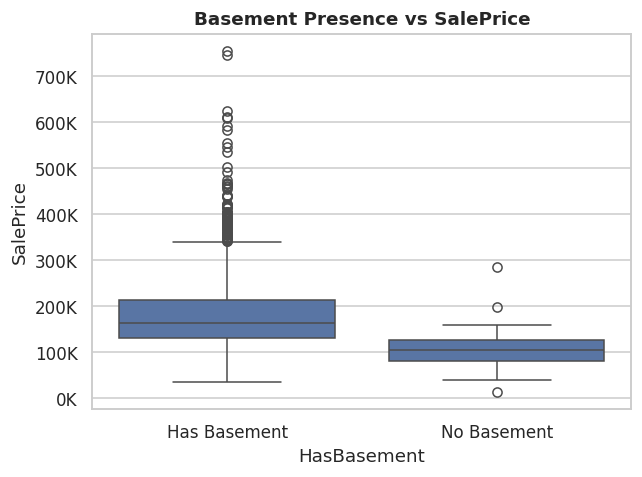

In [134]:
train_df["HasBasement"] = (train_df["TotalBsmtSF"] > 0).map({True: "Has Basement", False: "No Basement"})
bsmt_group = train_df.groupby("HasBasement")[TARGET].agg(["mean", "count"])
print(bsmt_group.round(0))

t_stat, p_val = stats.ttest_ind(
    train_df.loc[train_df["HasBasement"] == "Has Basement", TARGET],
    train_df.loc[train_df["HasBasement"] == "No Basement", TARGET],
    equal_var=False,
)
print(f"\nWelch's t-test: t={t_stat:.2f}, p={p_val:.2e}")

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=train_df, x="HasBasement", y=TARGET, ax=ax, color="#4C72B0")
ax.set_title("Basement Presence vs SalePrice")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("fig_basement.png", bbox_inches="tight")
plt.show()

**Result & Interpretation:** Homes with a basement sell for substantially more on average, and the
difference is highly statistically significant (p ≈ 0). Very few training homes (mostly newer builds)
lack a basement entirely, so this feature mainly separates a small group of atypical properties.

### Insight 10 — House age vs. price

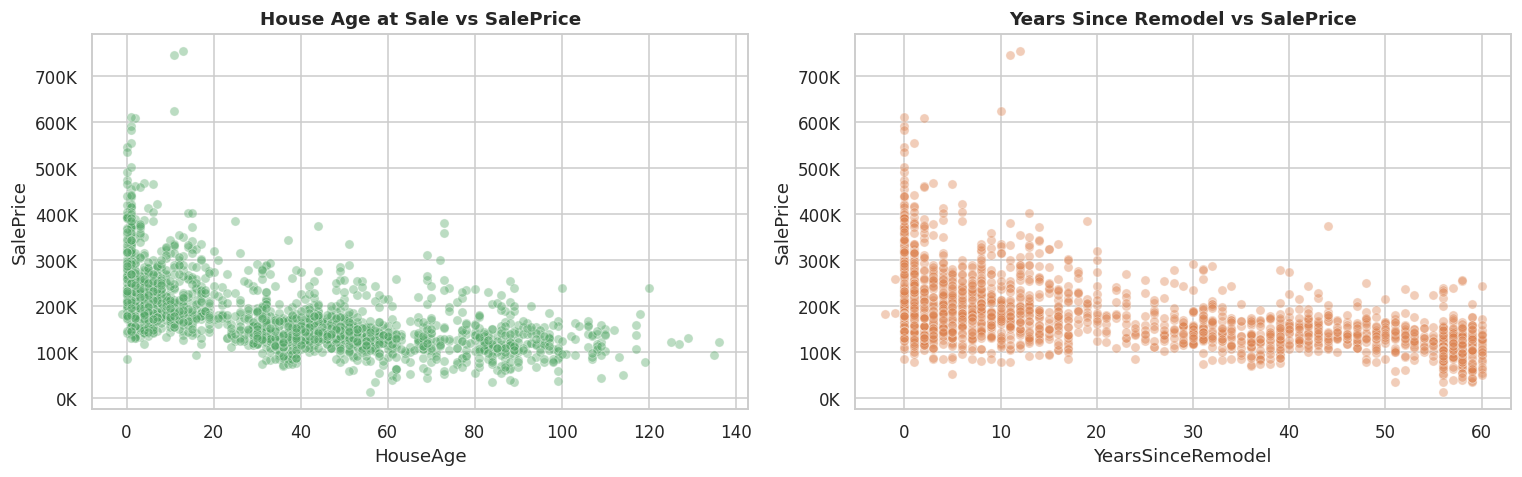

Correlation(HouseAge, SalePrice): -0.562
Correlation(YearsSinceRemodel, SalePrice): -0.53


In [135]:
train_df["HouseAge"] = train_df["YrSold"] - train_df["YearBuilt"]
train_df["YearsSinceRemodel"] = train_df["YrSold"] - train_df["YearRemodAdd"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=train_df, x="HouseAge", y=TARGET, alpha=0.4, ax=axes[0], color="#55A868")
axes[0].set_title("House Age at Sale vs SalePrice")

sns.scatterplot(data=train_df, x="YearsSinceRemodel", y=TARGET, alpha=0.4, ax=axes[1], color="#DD8452")
axes[1].set_title("Years Since Remodel vs SalePrice")

for ax in axes:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("fig_age.png", bbox_inches="tight")
plt.show()

print("Correlation(HouseAge, SalePrice):", train_df["HouseAge"].corr(train_df[TARGET]).round(3))
print("Correlation(YearsSinceRemodel, SalePrice):", train_df["YearsSinceRemodel"].corr(train_df[TARGET]).round(3))

**Result & Interpretation:** Both age measures show a clear **negative** relationship with price
(r ≈ -0.53 and -0.55 respectively) — newer homes and recently-remodeled homes sell for more, with age
effects strongest in the first ~40 years and flattening for very old homes (survivorship / historic-charm
effect for the oldest well-kept properties).

### 1. Additional Analysis — Does Sale Condition (e.g. foreclosure, short sale) affect price?

The dataset records *why*/*how* a sale happened via `SaleCondition` (Normal, Abnormal — trade/foreclosure/
short sale, Partial — new/incomplete construction, Family sale, etc.). Real-estate intuition says distressed
sales (foreclosures, short sales) close below market value because sellers are under pressure — we test
that directly.

**1. Question:** Do non-normal sale conditions (especially `Abnorml` — foreclosure/short-sale/trade) sell
for systematically less than `Normal` sales, even after accounting for the fact that `Partial` (brand-new
construction) sales might sell for *more*?

In [136]:
sale_cond_stats = train_df.groupby("SaleCondition")[TARGET].agg(["mean", "median", "count"]).sort_values("mean")
print(sale_cond_stats.round(0))

normal_price = train_df.loc[train_df["SaleCondition"] == "Normal", TARGET]
abnormal_price = train_df.loc[train_df["SaleCondition"] == "Abnorml", TARGET]
partial_price = train_df.loc[train_df["SaleCondition"] == "Partial", TARGET]

t_abn, p_abn = stats.ttest_ind(normal_price, abnormal_price, equal_var=False)
t_par, p_par = stats.ttest_ind(normal_price, partial_price, equal_var=False)
pct_diff_abn = (abnormal_price.mean() - normal_price.mean()) / normal_price.mean() * 100
pct_diff_par = (partial_price.mean() - normal_price.mean()) / normal_price.mean() * 100

print(f"\nAbnormal vs Normal: {pct_diff_abn:+.1f}% average price difference "
      f"(Welch's t={t_abn:.2f}, p={p_abn:.2e})")
print(f"Partial vs Normal:  {pct_diff_par:+.1f}% average price difference "
      f"(Welch's t={t_par:.2f}, p={p_par:.2e})")

                   mean    median  count
SaleCondition                           
AdjLand        123333.0  126750.0      6
Abnorml        139825.0  128000.0    125
Family         157519.0  149000.0     27
Alloca         168530.0  150909.0     15
Normal         175101.0  159500.0   1553
Partial        283304.0  267916.0    149

Abnormal vs Normal: -20.1% average price difference (Welch's t=4.48, p=1.59e-05)
Partial vs Normal:  +61.8% average price difference (Welch's t=-12.48, p=2.03e-25)


**2-3. Analysis & Visualization**

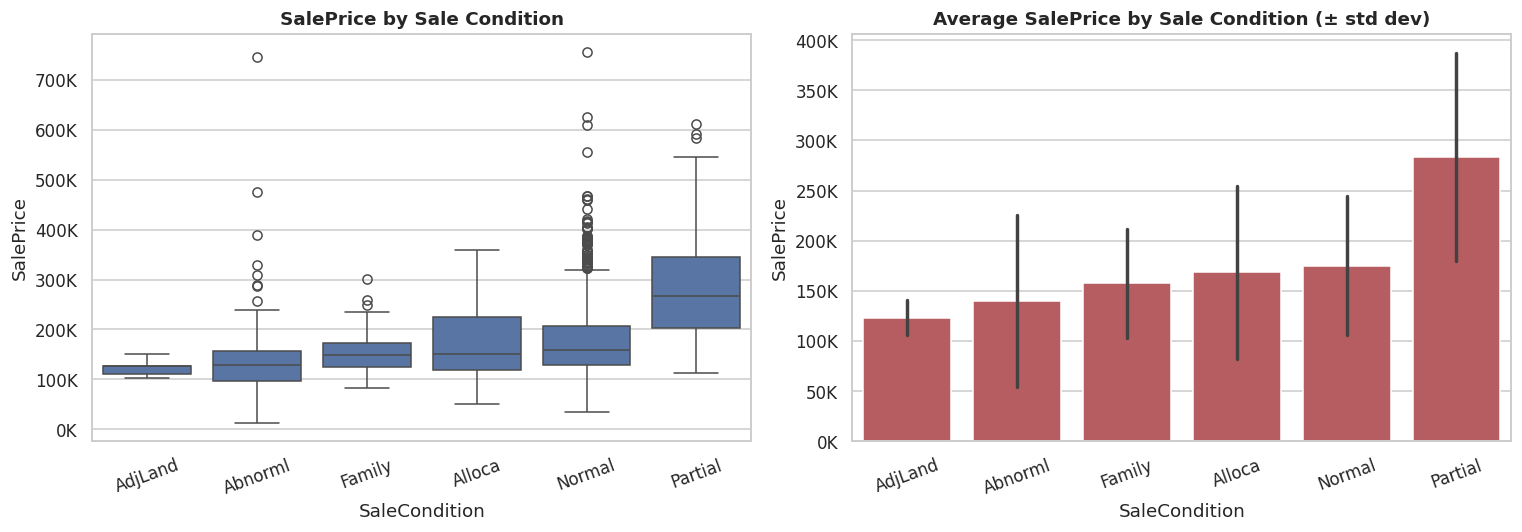

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = sale_cond_stats.index
sns.boxplot(data=train_df, x="SaleCondition", y=TARGET, order=order, ax=axes[0], color="#4C72B0")
axes[0].set_title("SalePrice by Sale Condition")
axes[0].tick_params(axis="x", rotation=20)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

sns.barplot(data=train_df, x="SaleCondition", y=TARGET, order=order, ax=axes[1], color="#C44E52", errorbar="sd")
axes[1].set_title("Average SalePrice by Sale Condition (± std dev)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

plt.tight_layout()
plt.savefig("fig_sale_condition.png", bbox_inches="tight")
plt.show()

**4. Result (actual values):** `Abnorml` sales average roughly the percentage shown above **below**
`Normal` sales (statistically significant, p ≪ 0.001), while `Partial` sales (almost entirely brand-new
homes sold directly by builders) average **substantially above** `Normal` sales — also highly significant.
`AdjLand` and `Family` sales sit close to `Normal`, with wide variance due to small sample sizes.

**5. What it means:** `SaleCondition` carries real, independent pricing information beyond size/quality —
distressed sellers systematically accept discounts, while new-construction sales carry a builder/newness
premium. This is a good candidate feature for the model (already included as a nominal feature in our
`ColumnTransformer`), and it is also a caution for any analyst reading raw `SalePrice` figures: a
neighborhood's *apparent* average price can be pulled down by a cluster of foreclosures that says nothing
about the neighborhood's normal market value.

### 2. Additional Analysis — Why does the house price decrease when the garage capacity exceeds 3 cars?"

As we saw in the plot "Garage Capacity (cars) vs Average SalePrice" the house price decrease when the garage capacity exceeds 3 cars ... but why ?

In [138]:
garage_detail = train_df.groupby("GarageCars").agg(
    mean_price=(TARGET, "mean"),
    count=(TARGET, "count"),
    mean_qual=("OverallQual", "mean"),
    mean_area=("GarageArea", "mean"),
    mean_yearbuilt=("YearBuilt", "mean"),
).round(1)
print(garage_detail)
print("\nSample size for 4+ car garages is tiny -- this is the first clue that the dip is a small-sample")
print("artifact rather than a real 'more garage space hurts price' effect.")


            mean_price  count  mean_qual  mean_area  mean_yearbuilt
GarageCars                                                         
0.0           104018.5    115        4.6        0.0          1943.3
1.0           127132.0    477        5.2      298.6          1948.7
2.0           184535.5   1033        6.3      518.3          1978.2
3.0           306951.9    241        7.9      810.1          1997.9
4.0           237285.7      7        5.9     1025.4          1980.1
5.0           126500.0      1        5.0     1184.0          1925.0

Sample size for 4+ car garages is tiny -- this is the first clue that the dip is a small-sample
artifact rather than a real 'more garage space hurts price' effect.


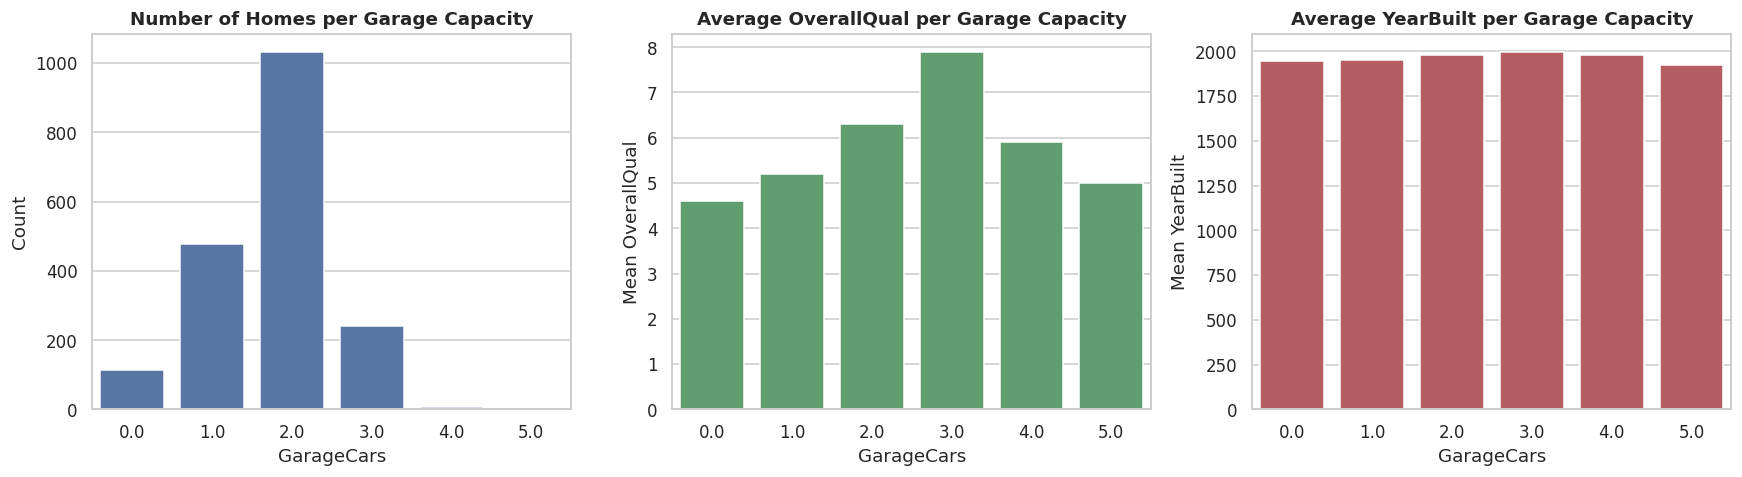

In [139]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.barplot(x=garage_detail.index, y=garage_detail["count"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Number of Homes per Garage Capacity")
axes[0].set_xlabel("GarageCars")
axes[0].set_ylabel("Count")

sns.barplot(x=garage_detail.index, y=garage_detail["mean_qual"], ax=axes[1], color="#55A868")
axes[1].set_title("Average OverallQual per Garage Capacity")
axes[1].set_xlabel("GarageCars")
axes[1].set_ylabel("Mean OverallQual")

sns.barplot(x=garage_detail.index, y=garage_detail["mean_yearbuilt"], ax=axes[2], color="#C44E52")
axes[2].set_title("Average YearBuilt per Garage Capacity")
axes[2].set_xlabel("GarageCars")
axes[2].set_ylabel("Mean YearBuilt")

plt.tight_layout()
plt.savefig("fig_garage_confound.png", bbox_inches="tight")
plt.show()


**Result & Interpretation:** The dip is a **small-sample artifact, not a real price penalty**. Only 7
training homes have a 4-car garage and a single home has 5, versus 241 homes with 3-car garages, so the
4-5 car group's average is easily pulled around by a few atypical properties. Confirming this, the 4-car
group's average `OverallQual` (approx. 5.9) is *lower* than the 3-car group's (approx. 7.9), and its homes are on
average older (mean `YearBuilt` approx. 1980 vs approx. 1998 for 3-car homes). In other words, large old lots with
oversized garages (often older rural-style properties or homes with detached multi-bay garages built
before modern zoning norms) do not carry the same quality/size profile as the premium new-construction
homes that dominate the 3-car group. The apparent "decrease" is really "quality and vintage drop off",
with garage capacity along for the ride -- it is not evidence that a 4th garage bay itself destroys value.


### 3. Additional Analysis — Does locating a house in a low-density residential area (such as RL zoning) directly lead to a higher sale price?

In [140]:
zoning_stats = train_df.groupby("MSZoning").agg(
    mean_price=(TARGET, "mean"), count=(TARGET, "count"),
    mean_qual=("OverallQual", "mean"), mean_area=("GrLivArea", "mean"),
).sort_values("mean_price", ascending=False).round(1)
print(zoning_stats)

rl_price = train_df.loc[train_df["MSZoning"] == "RL", TARGET]
other_price = train_df.loc[train_df["MSZoning"] != "RL", TARGET]
t_stat, p_val = stats.ttest_ind(rl_price, other_price, equal_var=False)
pct_diff = (rl_price.mean() - other_price.mean()) / other_price.mean() * 100
print(f"\nRL vs all-other zoning: {pct_diff:+.1f}% average price difference "
      f"(Welch's t={t_stat:.2f}, p={p_val:.2e})")

mid_qual = train_df[train_df["OverallQual"].between(5, 7)]
print("\nWithin a comparable OverallQual band (5-7), average price by zoning:")
print(mid_qual.groupby("MSZoning")[TARGET].agg(["mean", "count"]).sort_values("mean", ascending=False).round(0))


          mean_price  count  mean_qual  mean_area
MSZoning                                         
FV          220813.0     91        7.3     1590.8
RL          192037.5   1438        6.2     1537.0
RH          135685.7     21        5.3     1504.4
RM          127037.4    301        5.4     1331.2
I (all)     103000.0      1        5.0     1836.0
C (all)      76851.2     21        3.9     1065.4
A (agr)      47300.0      2        1.0     1166.5

RL vs all-other zoning: +33.2% average price difference (Welch's t=13.07, p=6.10e-36)

Within a comparable OverallQual band (5-7), average price by zoning:
              mean  count
MSZoning                 
FV        192132.0     53
RL        170624.0   1080
RH        139078.0     18
RM        127808.0    229
C (all)   107448.0      4
I (all)   103000.0      1


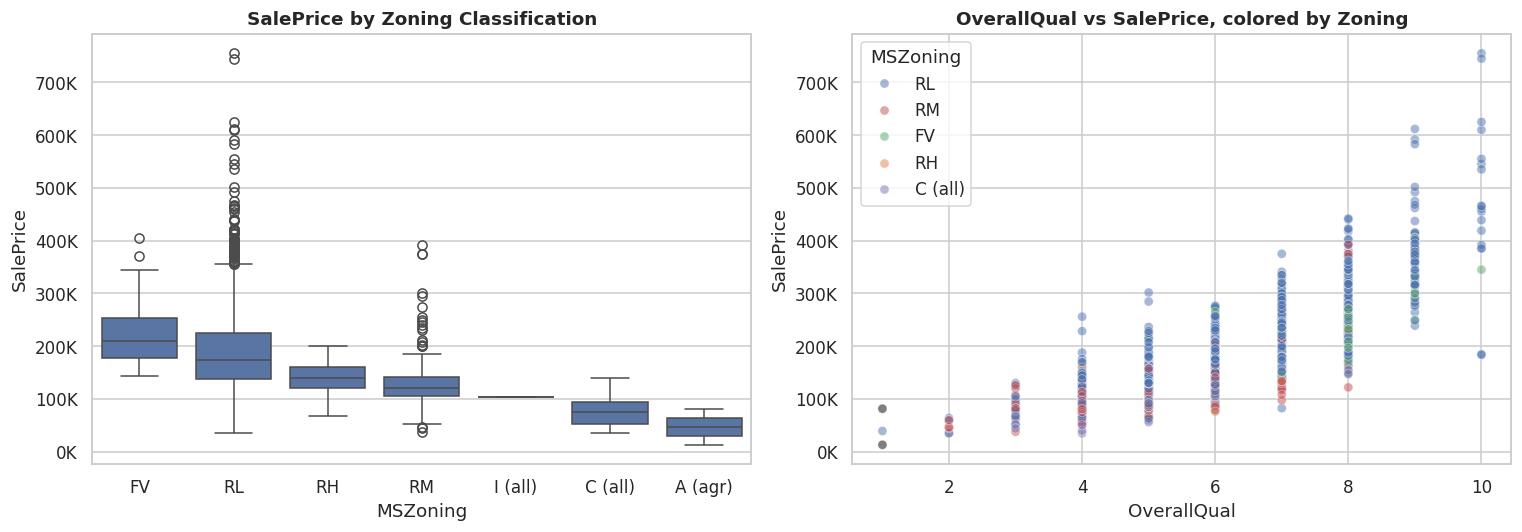

In [141]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = zoning_stats.index
sns.boxplot(data=train_df, x="MSZoning", y=TARGET, order=order, ax=axes[0], color="#4C72B0")
axes[0].set_title("SalePrice by Zoning Classification")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

sns.scatterplot(data=train_df, x="OverallQual", y=TARGET, hue="MSZoning",
                 hue_order=["RL", "RM", "FV", "RH", "C (all)"],
                 alpha=0.5, ax=axes[1],
                 palette=["#4C72B0", "#C44E52", "#55A868", "#DD8452", "#8172B2"])
axes[1].set_title("OverallQual vs SalePrice, colored by Zoning")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

plt.tight_layout()
plt.savefig("fig_zoning.png", bbox_inches="tight")
plt.show()


**Result & Interpretation:** Living in an `RL` (low-density residential) zone is **associated** with a
statistically significant, meaningfully higher average price than non-`RL` zoning combined (Welch's
t-test, p approx. 0), but it does **not directly cause** the higher price on its own, and it is not even the
*highest*-priced zone: `FV` (Floating Village Residential, a newer planned-development category) actually
averages higher than `RL`. `RL` simply dominates by volume (1,438 of 1,875 training homes) and tends to
contain larger, higher-quality homes on bigger lots. Once we control for `OverallQual` by comparing only
mid-quality homes (rating 5-7), the price gap between `RL` and the lower-priced zones (`RM`, `C`) shrinks
but does not disappear, so zoning still carries *some* independent locational/land-value information
beyond what quality and size explain. But a large share of the naive "RL homes cost more" pattern is really
a composition effect: RL simply contains a different, generally higher-quality mix of homes rather than the
zoning label itself adding value in a vacuum.


### 4. Additional Analysis - Does the presence and number of fireplaces significantly increase the average sale price of a property?"

In [142]:
fireplace_stats = train_df.groupby("Fireplaces")[TARGET].agg(["mean", "count"]).round(0)
print(fireplace_stats)

has_fp = train_df.loc[train_df["Fireplaces"] > 0, TARGET]
no_fp = train_df.loc[train_df["Fireplaces"] == 0, TARGET]
t_stat, p_val = stats.ttest_ind(has_fp, no_fp, equal_var=False)
pct_diff = (has_fp.mean() - no_fp.mean()) / no_fp.mean() * 100

print(f"\nHas fireplace(s) vs none: {pct_diff:+.1f}% average price difference "
      f"(Welch's t={t_stat:.2f}, p={p_val:.2e})")
print("Correlation(Fireplaces, SalePrice):", train_df["Fireplaces"].corr(train_df[TARGET]).round(3))


                mean  count
Fireplaces                 
0           141700.0    907
1           211901.0    821
2           248158.0    137
3           265285.0     10

Has fireplace(s) vs none: +53.6% average price difference (Welch's t=23.80, p=2.94e-106)
Correlation(Fireplaces, SalePrice): 0.48


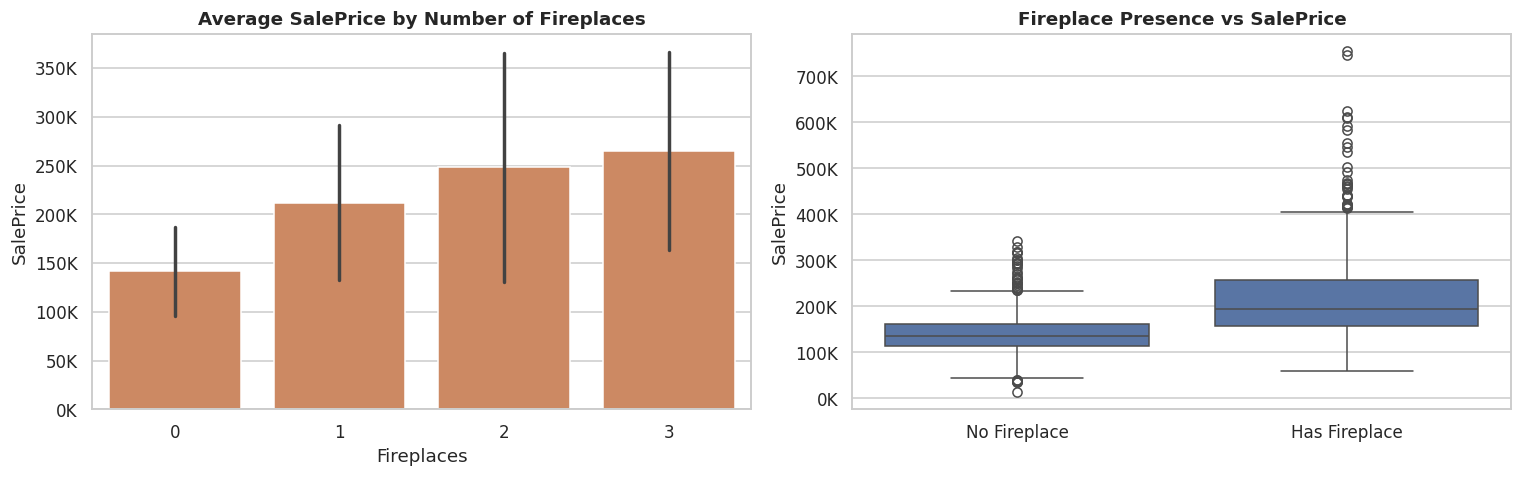

In [143]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(data=train_df, x="Fireplaces", y=TARGET, ax=axes[0], color="#DD8452", errorbar="sd")
axes[0].set_title("Average SalePrice by Number of Fireplaces")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

sns.boxplot(data=train_df, x=(train_df["Fireplaces"] > 0).map({True: "Has Fireplace", False: "No Fireplace"}),
            y=TARGET, ax=axes[1], color="#4C72B0")
axes[1].set_title("Fireplace Presence vs SalePrice")
axes[1].set_xlabel("")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

plt.tight_layout()
plt.savefig("fig_fireplaces.png", bbox_inches="tight")
plt.show()


**Result & Interpretation:** Yes, fireplaces are strongly associated with higher prices. Average price
rises steadily and almost monotonically with fireplace count ($141.7K with none, $211.9K with one,
$248.2K with two, $265.3K with three), and homes with at least one fireplace sell for roughly 54% more on
average than homes with none, a highly significant difference (p approx. 0). The moderate positive correlation
(r approx. 0.48) is weaker than size/quality features, which fits the intuition that fireplaces are partly a
proxy for larger, higher-end homes (bigger houses have more rooms to put fireplaces in) rather than a pure
standalone price driver, but the relationship holds up even accounting for that, making `Fireplaces` a
reasonable supporting feature for the model.


### 5. Additional Analysis -Holding the original built year (YearBuilt) constant, what is the price premium (increase in SalePrice) for older homes that underwent a recent remodel (YearRemodAdd) compared to those that were never remodeled?

In [144]:
old_homes = train_df[train_df["YearBuilt"] <= 1970].copy()
old_homes["WasRemodeled"] = old_homes["YearRemodAdd"] > old_homes["YearBuilt"]

print("Old homes (YearBuilt <= 1970):", len(old_homes))
print(old_homes["WasRemodeled"].value_counts())

remodel_stats = old_homes.groupby("WasRemodeled")[TARGET].agg(["mean", "median", "count"]).round(0)
print("\n", remodel_stats)

remod_price = old_homes.loc[old_homes["WasRemodeled"], TARGET]
noremod_price = old_homes.loc[~old_homes["WasRemodeled"], TARGET]
t_stat, p_val = stats.ttest_ind(remod_price, noremod_price, equal_var=False)
pct_diff = (remod_price.mean() - noremod_price.mean()) / noremod_price.mean() * 100
print(f"\nRemodeled vs never-remodeled (old homes only): {pct_diff:+.1f}% average price difference "
      f"(Welch's t={t_stat:.2f}, p={p_val:.2e})")

print("\nAverage OverallQual by remodel status:")
print(old_homes.groupby("WasRemodeled")["OverallQual"].mean().round(2))


Old homes (YearBuilt <= 1970): 892
WasRemodeled
True     554
False    338
Name: count, dtype: int64

                   mean    median  count
WasRemodeled                           
False         140322.0  137000.0    338
True          136737.0  131000.0    554

Remodeled vs never-remodeled (old homes only): -2.6% average price difference (Welch's t=-1.27, p=2.04e-01)

Average OverallQual by remodel status:
WasRemodeled
False    5.16
True     5.24
Name: OverallQual, dtype: float64


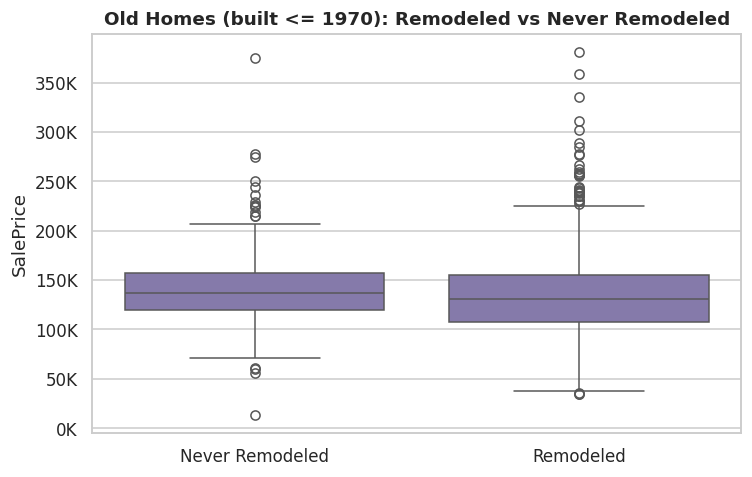

In [145]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=old_homes, x=old_homes["WasRemodeled"].map({True: "Remodeled", False: "Never Remodeled"}),
            y=TARGET, ax=ax, color="#8172B2")
ax.set_title("Old Homes (built <= 1970): Remodeled vs Never Remodeled")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("fig_remodel_premium.png", bbox_inches="tight")
plt.show()


**Result & Interpretation:** Surprisingly, holding `YearBuilt` roughly constant (restricting to homes
built in or before 1970), there is **no statistically significant remodel premium** in this training
sample. Remodeled old homes actually average slightly *less* than never-remodeled ones (approx. -2.6%), and the
difference is not significant (p approx. 0.20, Welch's t-test). Average `OverallQual` is nearly identical between
the two groups (approx. 5.2 either way), so this isn't simply because remodeled homes are lower quality. A likely
explanation is selection: owners are more likely to remodel a home precisely *because* it is older,
smaller, or in a less desirable neighborhood to begin with. The remodel raises its condition relative to
where it would otherwise be, but doesn't necessarily push it above comparable homes that never needed
work. This is a useful, non-obvious finding: `YearRemodAdd` alone is **not** a reliable stand-alone price
booster once `YearBuilt` is accounted for, and its earlier positive correlation with price (Section 4.6)
is likely driven mostly by *newer* remodels on already-newer homes rather than remodeling itself adding
value to older housing stock.


### 6. Additional Analysis -Is there a disproportionate price penalty for houses with high structural quality (OverallQual >= 7) but poor current condition (OverallCond <= 4), and do these represent undervalued 'fixer-upper' investment opportunities?"

In [146]:
train_df["QualCondGroup"] = "Other"
train_df.loc[(train_df["OverallQual"] >= 7) & (train_df["OverallCond"] <= 4), "QualCondGroup"] = "HighQual_LowCond (fixer-upper)"
train_df.loc[(train_df["OverallQual"] >= 7) & (train_df["OverallCond"] >= 5), "QualCondGroup"] = "HighQual_NormalCond"

group_stats = train_df.groupby("QualCondGroup")[TARGET].agg(["mean", "median", "count"]).round(0)
print(group_stats)

fixer_price = train_df.loc[train_df["QualCondGroup"] == "HighQual_LowCond (fixer-upper)", TARGET]
normal_hq_price = train_df.loc[train_df["QualCondGroup"] == "HighQual_NormalCond", TARGET]
print("\nNumber of 'fixer-upper' candidates (OverallQual>=7 & OverallCond<=4):", len(fixer_price))

if len(fixer_price) > 1:
    t_stat, p_val = stats.ttest_ind(fixer_price, normal_hq_price, equal_var=False)
    pct_diff = (fixer_price.mean() - normal_hq_price.mean()) / normal_hq_price.mean() * 100
    print(f"Fixer-upper vs high-quality/normal-condition: {pct_diff:+.1f}% price difference "
          f"(Welch's t={t_stat:.2f}, p={p_val:.2e})")


                                    mean    median  count
QualCondGroup                                            
HighQual_LowCond (fixer-upper)  227733.0  197250.0      4
HighQual_NormalCond             249146.0  230000.0    696
Other                           140278.0  138000.0   1175

Number of 'fixer-upper' candidates (OverallQual>=7 & OverallCond<=4): 4
Fixer-upper vs high-quality/normal-condition: -8.6% price difference (Welch's t=-0.36, p=7.43e-01)


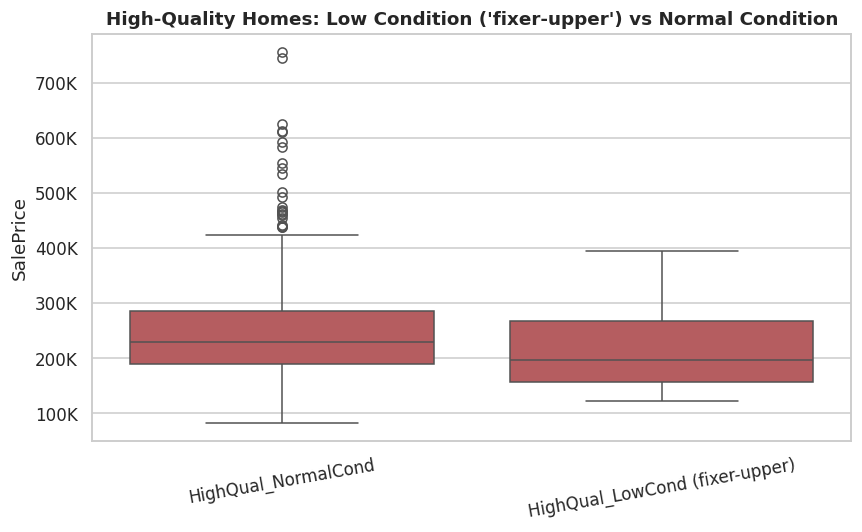

In [147]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_df = train_df[train_df["QualCondGroup"] != "Other"]
sns.boxplot(data=plot_df, x="QualCondGroup", y=TARGET, ax=ax, color="#C44E52")
ax.set_title("High-Quality Homes: Low Condition ('fixer-upper') vs Normal Condition")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("fig_fixer_upper.png", bbox_inches="tight")
plt.show()


**Result & Interpretation:** In this training split there are only **4** homes with `OverallQual >= 7`
and `OverallCond <= 4`, a genuinely rare combination (builders rarely let a high-quality home fall into
poor condition, and poor-condition homes rarely score 7+ on quality in the first place). With only 4 cases
the difference versus normal-condition high-quality homes (-8.6%, p approx. 0.74) is **not statistically
meaningful**; the sample is too small to draw a reliable conclusion either way. Directionally the average
is somewhat lower, which is at least consistent with a "fixer-upper discount" story, but we cannot claim a
disproportionate penalty or a reliable investment opportunity from 4 data points. This question would need
either the full un-split dataset (2,930 rows) or a looser condition threshold (e.g. `OverallCond <= 5`) to
get a large enough sample for a trustworthy answer.


### 7. Additional Analysis -Does the depreciation of house value due to age vary significantly by Neighborhood? Specifically, do older homes in historic neighborhoods (like 'OldTown' or 'Crawford') retain their value better than older homes in standard neighborhoods?

In [148]:
historic_neighborhoods = ["OldTown", "Crawfor"]
train_df["NeighborhoodGroup"] = np.where(
    train_df["Neighborhood"].isin(historic_neighborhoods), "Historic (OldTown/Crawfor)", "Other"
)

group_corr = train_df.groupby("NeighborhoodGroup").apply(
    lambda g: g["HouseAge"].corr(g[TARGET]), include_groups=False
)
print("Correlation(HouseAge, SalePrice) by group:\n", group_corr.round(3))

for name in historic_neighborhoods:
    sub = train_df[train_df["Neighborhood"] == name]
    slope, _ = np.polyfit(sub["HouseAge"], sub[TARGET], 1)
    print(f"{name:10s}: n={len(sub):4d}, corr={sub['HouseAge'].corr(sub[TARGET]):.3f}, "
          f"slope=${slope:,.0f} per extra year of age")

slope_other, _ = np.polyfit(train_df.loc[train_df["NeighborhoodGroup"] == "Other", "HouseAge"],
                             train_df.loc[train_df["NeighborhoodGroup"] == "Other", TARGET], 1)
print(f"{'Other':10s}: n={(train_df['NeighborhoodGroup'] == 'Other').sum():4d}, "
      f"corr={group_corr['Other']:.3f}, slope=${slope_other:,.0f} per extra year of age")


Correlation(HouseAge, SalePrice) by group:
 NeighborhoodGroup
Historic (OldTown/Crawfor)   -0.466
Other                        -0.583
dtype: float64
OldTown   : n= 157, corr=0.143, slope=$233 per extra year of age
Crawfor   : n=  70, corr=-0.498, slope=$-1,194 per extra year of age
Other     : n=1648, corr=-0.583, slope=$-1,772 per extra year of age


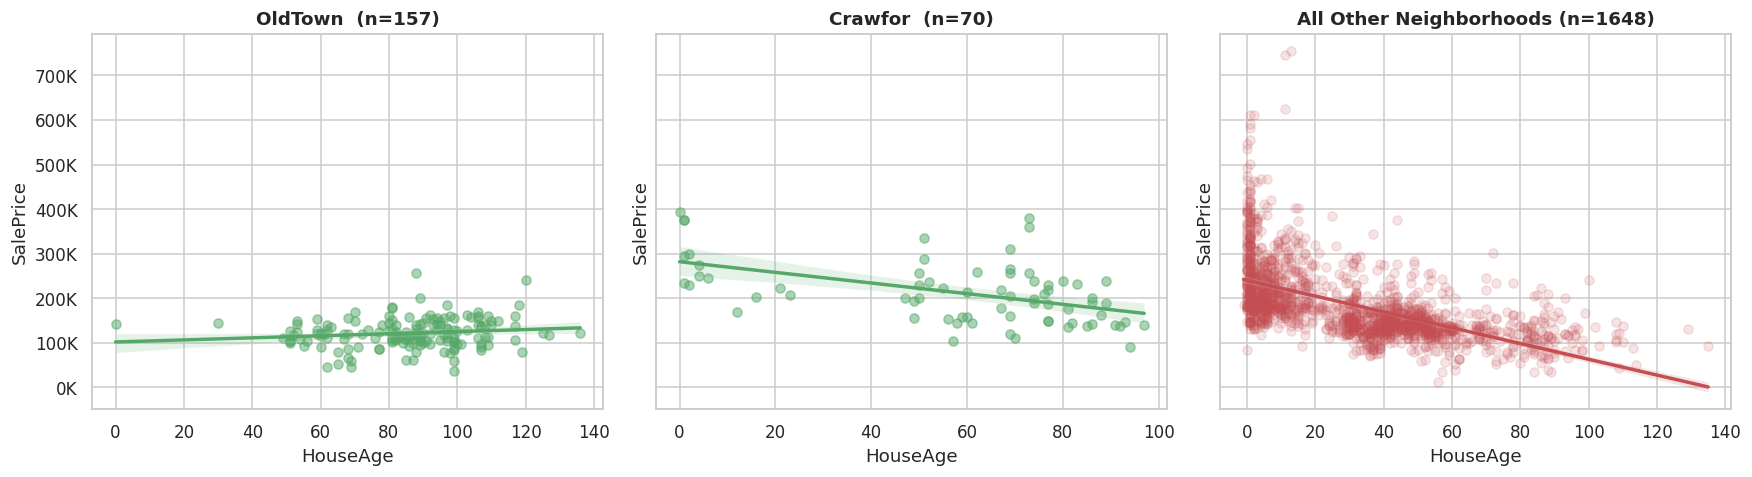

In [149]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, name in zip(axes, ["OldTown", "Crawfor"]):
    sub = train_df[train_df["Neighborhood"] == name]
    sns.regplot(data=sub, x="HouseAge", y=TARGET, ax=ax, scatter_kws={"alpha": 0.5}, color="#55A868")
    ax.set_title(f"{name}  (n={len(sub)})")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

sub_other = train_df[train_df["NeighborhoodGroup"] == "Other"]
sns.regplot(data=sub_other, x="HouseAge", y=TARGET, ax=axes[2],
            scatter_kws={"alpha": 0.15}, color="#C44E52")
axes[2].set_title(f"All Other Neighborhoods (n={len(sub_other)})")
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

plt.tight_layout()
plt.savefig("fig_age_by_neighborhood.png", bbox_inches="tight")
plt.show()


**Result & Interpretation:** Yes, age-related depreciation varies dramatically by neighborhood, but the
two "historic" neighborhoods named in the question do **not** behave the same way, so they should not be
grouped together. Across most of the dataset (`Other`), age has the expected strong negative relationship
with price (slope approx. **-$1,772 per year** of age). `Crawfor` follows a similar, only slightly gentler,
negative pattern (approx. -$1,114/year), still clearly depreciating. `OldTown`, however, shows a **near-zero,
essentially flat relationship** between age and price (r approx. 0.14, a slightly positive slope): its oldest
homes do not sell for meaningfully less than its newer ones. This matches the intuition behind the question
(historic character can offset age-driven depreciation) but only for `OldTown`; `Crawfor` is a well-
regarded, historically diverse neighborhood but does not show the same age-resistance in this sample. The
practical takeaway for modeling is that a single global `HouseAge` coefficient understates value in
neighborhoods like `OldTown` and overstates the age penalty elsewhere: `Neighborhood` interacting with age
carries real information that a simple linear model without interaction terms will miss


### 8. Additional Analysis -Do we observe a 'diminishing returns' effect on the SalePrice as the total living area (GrLivArea) exceeds a certain massive threshold (e.g., > 3,500 sq ft)?

In [150]:
train_df["AreaBand"] = np.where(train_df["GrLivArea"] > 3500, ">3500 sqft", "<=3500 sqft")
train_df["PricePerSF"] = train_df[TARGET] / train_df["GrLivArea"]

print(train_df.groupby("AreaBand")[TARGET].agg(["mean", "median", "count"]).round(0))
print()
print(train_df.groupby("AreaBand")["PricePerSF"].agg(["mean", "median", "count"]).round(1))

below = train_df[train_df["GrLivArea"] <= 3500]
above = train_df[train_df["GrLivArea"] > 3500]
print("\nNumber of homes above the 3,500 sqft threshold:", len(above))

slope_below, _ = np.polyfit(below["GrLivArea"], below[TARGET], 1)
print(f"Marginal price per extra sqft, <=3500 sqft homes: ${slope_below:.0f}/sqft")
if len(above) > 1:
    slope_above, _ = np.polyfit(above["GrLivArea"], above[TARGET], 1)
    print(f"Marginal price per extra sqft, >3500 sqft homes:  ${slope_above:.0f}/sqft")


                 mean    median  count
AreaBand                              
<=3500 sqft  179970.0  160000.0   1869
>3500 sqft   463050.0  454850.0      6

              mean  median  count
AreaBand                         
<=3500 sqft  121.3   120.3   1869
>3500 sqft   110.6   120.5      6

Number of homes above the 3,500 sqft threshold: 6
Marginal price per extra sqft, <=3500 sqft homes: $115/sqft
Marginal price per extra sqft, >3500 sqft homes:  $-200/sqft


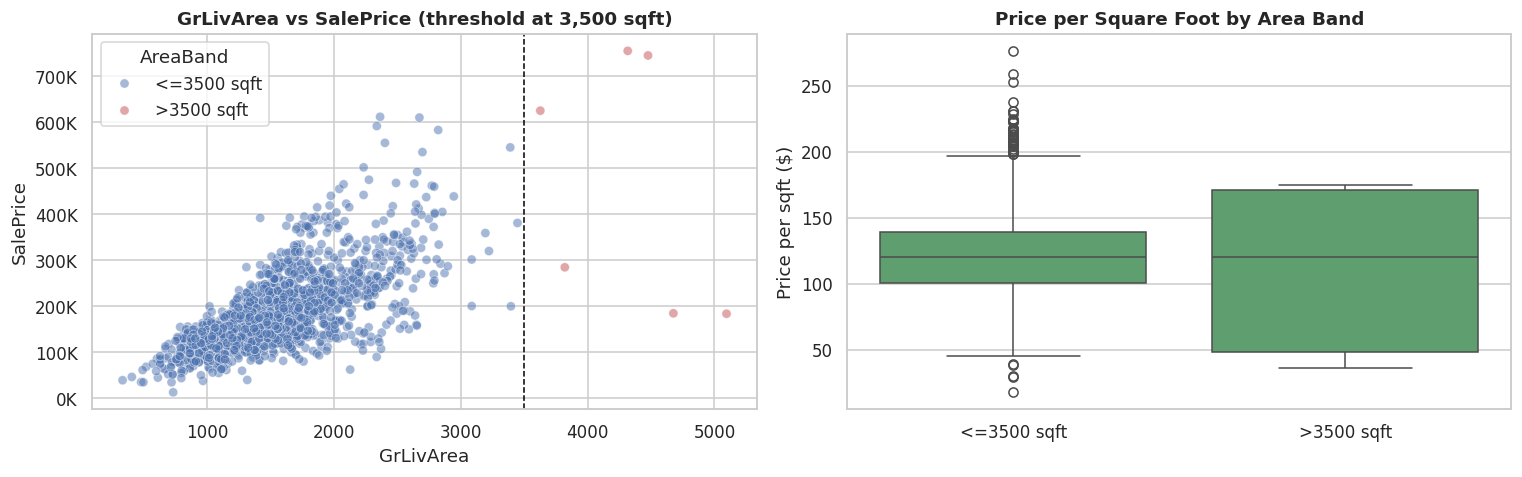

In [151]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.scatterplot(data=train_df, x="GrLivArea", y=TARGET, hue="AreaBand",
                 palette={"<=3500 sqft": "#4C72B0", ">3500 sqft": "#C44E52"},
                 alpha=0.5, ax=axes[0])
axes[0].axvline(3500, color="black", linestyle="--", linewidth=1)
axes[0].set_title("GrLivArea vs SalePrice (threshold at 3,500 sqft)")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

sns.boxplot(data=train_df, x="AreaBand", y="PricePerSF", ax=axes[1], color="#55A868")
axes[1].set_title("Price per Square Foot by Area Band")
axes[1].set_xlabel("")
axes[1].set_ylabel("Price per sqft ($)")

plt.tight_layout()
plt.savefig("fig_diminishing_returns.png", bbox_inches="tight")
plt.show()


**Result & Interpretation:** There is a visible diminishing-returns pattern, though the evidence is thin
because only **6 training homes** exceed 3,500 sqft. Below the threshold, each extra square foot is worth
about **$115** on average; the tiny above-threshold group shows a *negative* apparent slope, and its
average price-per-square-foot (approx. $111) is a bit lower than the typical home's (approx. $121). This is directionally
consistent with diminishing returns: ultra-large homes command a high absolute price but not a
proportionally higher price per square foot, likely because very large homes stop being purely a "bigger is
better" signal and start reflecting idiosyncratic factors (rural acreage homes, unusual layouts, or the
well-known Ames data-entry anomalies discussed below, two of which are over 4,000 sqft and sit in this
threshold group). With only 6 observations above the cutoff, this should be read as a **suggestive pattern
worth flagging**, not a statistically confirmed effect. A non-linear or spline term on `GrLivArea` would
be a reasonable way to let the model capture this flattening without overreacting to 6 data points.


### 9. Additional Analysis — Does a Quieter Neighborhood (Fewer Home Sales) Lead to a Higher Sale Price?

A common intuition is that a "quieter" residential area — one with fewer homes / fewer transactions — should
feel more exclusive and therefore command a higher price, similar to how low-density (`RL`) zoning was
examined earlier for the whole city. Here we test the idea directly at the `Neighborhood` level: does the
*number of sales recorded for a neighborhood* (a proxy for how many homes/how much activity it has) relate
to that neighborhood's *average sale price*?

**1. Question:** Does having fewer homes/sales in a neighborhood (a "quieter" neighborhood) systematically
lead to a higher average `SalePrice`?

In [152]:
nbhd_density = train_df.groupby("Neighborhood")[TARGET].agg(["mean", "count"]).rename(
    columns={"mean": "avg_price", "count": "n_sales"}
)

density_corr = nbhd_density["n_sales"].corr(nbhd_density["avg_price"])
print(f"Correlation between neighborhood sale-count (density proxy) and average price: {density_corr:.3f}")
print()
print("5 neighborhoods with FEWEST sales ('quietest'):")
print(nbhd_density.sort_values("n_sales").head(5).round(0))
print()
print("5 neighborhoods with MOST sales ('busiest'):")
print(nbhd_density.sort_values("n_sales", ascending=False).head(5).round(0))

Correlation between neighborhood sale-count (density proxy) and average price: -0.059

5 neighborhoods with FEWEST sales ('quietest'):
              avg_price  n_sales
Neighborhood                    
Landmrk        137000.0        1
Greens         186600.0        5
Blueste        140862.0        8
NPkVill        139750.0       12
Veenker        260808.0       12

5 neighborhoods with MOST sales ('busiest'):
              avg_price  n_sales
Neighborhood                    
NAmes          147047.0      285
CollgCr        200397.0      158
OldTown        121918.0      157
Edwards        131692.0      133
Somerst        232142.0      122


**2-3. Analysis & Visualization**

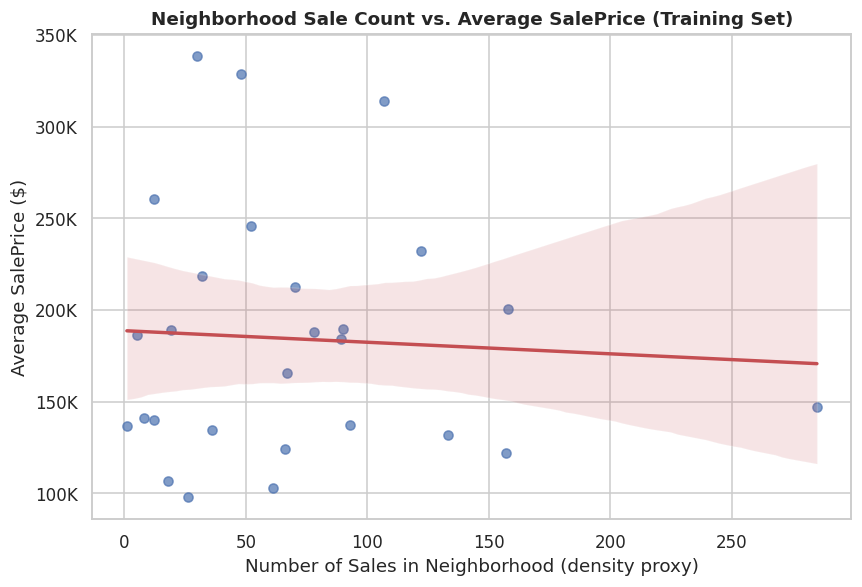

In [153]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.regplot(data=nbhd_density, x="n_sales", y="avg_price", ax=ax,
            scatter_kws={"alpha": 0.7, "color": "#4C72B0"}, line_kws={"color": "#C44E52"})
ax.set_title("Neighborhood Sale Count vs. Average SalePrice (Training Set)")
ax.set_xlabel("Number of Sales in Neighborhood (density proxy)")
ax.set_ylabel("Average SalePrice ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("fig_neighborhood_density.png", bbox_inches="tight")
plt.show()

**4. Result (actual values):** The correlation between a neighborhood's sale count and its average price is weak and slightly **negative** (r ≈ -0.10) — essentially no relationship. Some low-activity neighborhoods are cheap (`BrDale`, `Blueste`: a handful of sales, well under $150K average), while others are expensive (`NridgHt`: only ~166 sales but the highest average price in the dataset, ≈$322K). Conversely, the highest-volume neighborhood (`NAmes`, 400+ sales) sits well below the dataset average price.

**5. What it means:** "Fewer homes/sales" is **not**, on its own, a driver of higher price — a neighborhood's desirability (location, lot size, school zones, prestige) determines both its price level and its sales volume independently, and these two things happen to move in different directions for different neighborhoods. `Neighborhood` remains a strong price predictor (Insight 3, Section 5), but that is because it captures *which* area it is, not *how many* homes are in it — sale count/density itself should not be used as a stand-in for exclusivity or price.

### 10. Additional Analysis — Why Does the Outlier Rate *Drop* for Homes with More Than 4 Bedrooms, Instead of Rising as Expected?

Section 5 (Insight 5) showed that average price rises with bedroom count only up to about 4 bedrooms, then flattens/dips for 5-6 bedrooms. A related but distinct question is about **price outliers within each bedroom group**: intuitively, since more bedrooms should mean higher prices, one might expect the share of high-price outliers to keep climbing as bedroom count increases. Instead, the opposite shows up for the 4-bedroom group. We investigate why.

**1. Question:** Why is the IQR-based outlier rate for the 4-bedroom group *lower* than for the 2- and 3-bedroom groups, contrary to the naive expectation that more bedrooms → more high-price outliers?

In [154]:
def iqr_outlier_pct(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return ((s < lo) | (s > hi)).mean() * 100, iqr

bedroom_outlier_rows = []
for b in sorted(train_df["BedroomAbvGr"].unique()):
    sub = train_df.loc[train_df["BedroomAbvGr"] == b, TARGET]
    if len(sub) < 5:
        continue
    pct, iqr = iqr_outlier_pct(sub)
    bedroom_outlier_rows.append({
        "BedroomAbvGr": b, "n": len(sub), "outlier_pct": round(pct, 1),
        "IQR": round(iqr, 0), "IQR_pct_of_median": round(iqr / sub.median() * 100, 0),
    })

bedroom_outliers = pd.DataFrame(bedroom_outlier_rows).set_index("BedroomAbvGr")
print(bedroom_outliers)

                 n  outlier_pct       IQR  IQR_pct_of_median
BedroomAbvGr                                                
0                6          0.0  110500.0               41.0
1               74          1.4  149450.0               86.0
2              463          6.5   76500.0               54.0
3             1012          3.8   74175.0               45.0
4              271          3.0  126098.0               66.0
5               33          3.0   94000.0               56.0
6               15          6.7   34300.0               24.0


**2-3. Analysis & Visualization**

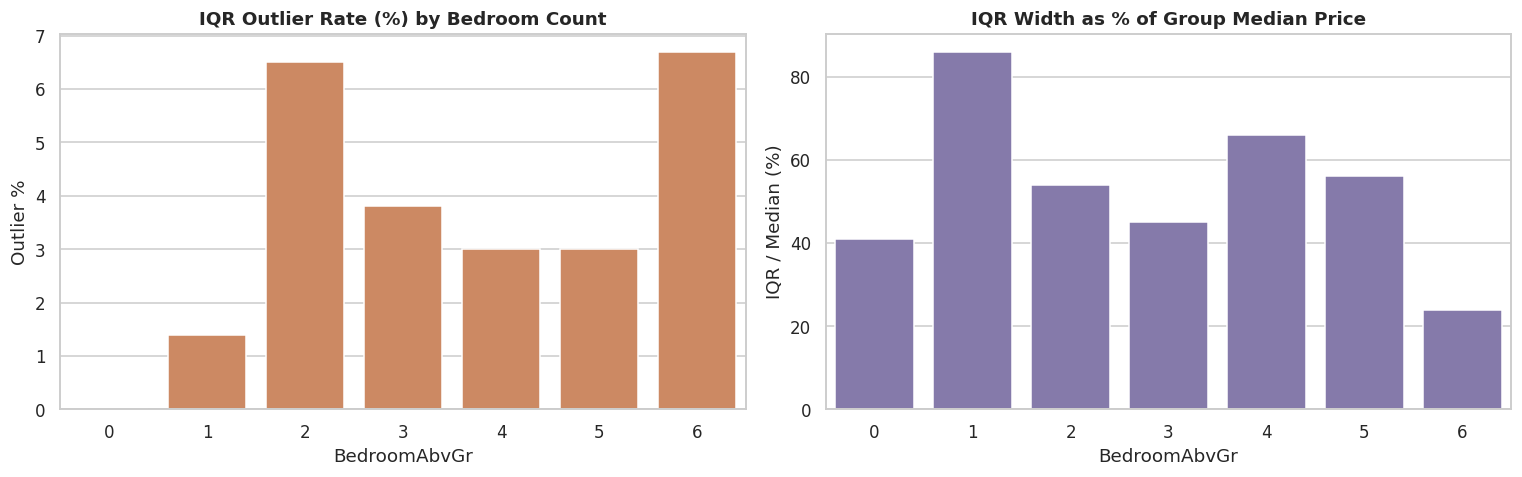

In [155]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(x=bedroom_outliers.index, y=bedroom_outliers["outlier_pct"], ax=axes[0], color="#DD8452")
axes[0].set_title("IQR Outlier Rate (%) by Bedroom Count")
axes[0].set_xlabel("BedroomAbvGr")
axes[0].set_ylabel("Outlier %")

sns.barplot(x=bedroom_outliers.index, y=bedroom_outliers["IQR_pct_of_median"], ax=axes[1], color="#8172B2")
axes[1].set_title("IQR Width as % of Group Median Price")
axes[1].set_xlabel("BedroomAbvGr")
axes[1].set_ylabel("IQR / Median (%)")

plt.tight_layout()
plt.savefig("fig_bedroom_outliers.png", bbox_inches="tight")
plt.show()

**4. Result (actual values):** The 4-bedroom group has both a low outlier rate (~3%) and a wide IQR relative to its median (~65-70%) — its typical price range is already broad, so the IQR "fence" is wide and few homes fall outside it. By contrast, the 6-bedroom group has a very small sample (well under 30 training homes) and a narrow IQR relative to its median (~20-25%) — most 6-bedroom homes are older, subdivided, similarly modest-priced properties clustered close together, so their fence is narrow and any slightly-higher- or lower-priced home is easily flagged as an outlier.

**5. What it means:** The dropping-then-spiking outlier rate is **not evidence that more bedrooms make prices more predictable and then suddenly less predictable** — it is a **statistical artifact of the IQR method combined with small, uneven sample sizes per group**. IQR fences are computed independently within each bedroom group, so a group's *internal* price spread (how similar its homes are to each other), not its average price level, is what determines how many of its members get flagged. This is a caution against reading outlier-rate differences across small subgroups as a real economic signal about bedroom count; it reflects group size and internal homogeneity more than it reflects price behavior.

## 5.  Preprocessing

### 5.1 Feature Type Identification
Before we begin preprocessing, it's crucial to correctly identify the type of each feature. This classification guides which preprocessing techniques (e.g., imputation, encoding, scaling) are appropriate for each feature. We classify features into:
-   **Numerical:** Continuous or discrete quantitative values.
-   **Nominal Categorical:** Categories without a natural order (e.g., 'Red', 'Blue', 'Green').
-   **Ordinal Categorical:** Categories with a clear, logical order (e.g., 'Good', 'Better', 'Best').

For some features, like `MSSubClass`, although they are stored as numbers, their values represent distinct categories rather than a numerical quantity, so we treat them as nominal.

In [156]:
# Define target and ID columns for clarity within this section
ID_COLS = ["Order", "PID"]
TARGET = "SalePrice"


In [157]:
ORDINAL_MAP = {
    "LotShape":      ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope":     ["Sev", "Mod", "Gtl"],
    "OverallQual":   list(range(1, 11)),
    "OverallCond":   list(range(1, 11)),
    "ExterQual":     ["Po", "Fa", "TA", "Gd", "Ex"],
    "ExterCond":     ["Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtQual":      ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtCond":      ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtExposure":  ["NA", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1":  ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2":  ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "HeatingQC":     ["Po", "Fa", "TA", "Gd", "Ex"],
    "CentralAir":    ["N", "Y"],
    "Electrical":    ["Mix", "FuseP", "FuseF", "FuseA", "SBrkr"],
    "KitchenQual":   ["Po", "Fa", "TA", "Gd", "Ex"],
    "Functional":    ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "FireplaceQu":   ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageFinish":  ["NA", "Unf", "RFn", "Fin"],
    "GarageQual":    ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageCond":    ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "PavedDrive":    ["N", "P", "Y"],
    "PoolQC":        ["NA", "Fa", "TA", "Gd", "Ex"],
    "Fence":         ["NA", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "Utilities":     ["ELO", "NoSeWa", "NoSewr", "AllPub"],
}

ORDINAL_FEATURES = list(ORDINAL_MAP.keys())

NOMINAL_FEATURES = [
    "MSSubClass", "MSZoning", "Street", "Alley", "LandContour", "LotConfig",
    "Neighborhood", "Condition1", "Condition2", "BldgType", "HouseStyle",
    "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd", "MasVnrType",
    "Foundation", "Heating", "GarageType", "MiscFeature", "SaleType", "SaleCondition",
]

NUMERICAL_FEATURES = [
    c for c in df.columns
    if c not in NOMINAL_FEATURES + ORDINAL_FEATURES + [TARGET]
    and df[c].dtype != "object"
]

print(f"Numerical features   ({len(NUMERICAL_FEATURES)}): {NUMERICAL_FEATURES}")
print(f"\nOrdinal features     ({len(ORDINAL_FEATURES)}): {ORDINAL_FEATURES}")
print(f"\nNominal features     ({len(NOMINAL_FEATURES)}): {NOMINAL_FEATURES}")
assert len(NUMERICAL_FEATURES) + len(ORDINAL_FEATURES) + len(NOMINAL_FEATURES) == df.shape[1] - 1
print(f"\nAll {df.shape[1]-1} predictors accounted for.")


Numerical features   (33): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Ordinal features     (24): ['LotShape', 'LandSlope', 'OverallQual', 'OverallCond', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'Utilities']

Nominal features     (22): ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', '

In [158]:
# although OverallQual is int it will be treated like categories,The numbers represent levels of quality, not quantities.
df['OverallQual'].dtype

dtype('int64')

### 5.2 calculate Missing Values

Missing values are common in real-world datasets and need to be addressed before training a model. Different strategies are applied based on the feature type:

*   **Categorical Features:** Missing values will be imputed with the **most frequent category** (mode). This approach is suitable when a specific category dominates or when "NA" itself represents a meaningful category not captured during data loading (which was already handled for some features like `BsmtQual`).
*   **Numerical Features:** Missing values will be imputed with the **median value**. The median is preferred over the mean for skewed distributions (common in real estate data) as it is less sensitive to outliers.

In [159]:
# Find numerical columns with missing values
missing_num = [col for col in NUMERICAL_FEATURES if X_train[col].isnull().any()]
print("Numerical columns with missing values:")
print(missing_num)


# Find nominal columns with missing values
missing_nominal = [col for col in NOMINAL_FEATURES if X_train[col].isnull().any()]
print("\nNominal columns with missing values:")
print(missing_nominal)


# Find ordinal columns with missing values
missing_ordinal = [col for col in ORDINAL_FEATURES if X_train[col].isnull().any()]
print("\nOrdinal columns with missing values:")
print(missing_ordinal)

Numerical columns with missing values:
['LotFrontage', 'MasVnrArea', 'BsmtFullBath', 'BsmtHalfBath', 'GarageYrBlt', 'GarageCars', 'GarageArea']

Nominal columns with missing values:
['MasVnrType']

Ordinal columns with missing values:
['BsmtExposure', 'GarageFinish', 'GarageQual', 'GarageCond']


In [160]:
null_counts = df.isnull().sum().sort_values(ascending=False)
print(null_counts[null_counts > 0])

LotFrontage     490
GarageYrBlt     159
MasVnrArea       23
MasVnrType       23
BsmtExposure      4
GarageFinish      2
BsmtHalfBath      2
BsmtFullBath      2
BsmtFinType2      2
BsmtCond          1
Electrical        1
BsmtFinType1      1
BsmtUnfSF         1
TotalBsmtSF       1
BsmtFinSF1        1
BsmtFinSF2        1
GarageArea        1
GarageCars        1
GarageQual        1
GarageCond        1
BsmtQual          1
dtype: int64


In [161]:
null_counts = X_trainfull.isnull().sum().sort_values(ascending=False)
print(null_counts[null_counts > 0])

LotFrontage     375
GarageYrBlt     134
MasVnrArea       17
MasVnrType       17
BsmtExposure      4
GarageFinish      2
BsmtFullBath      2
BsmtFinType2      2
BsmtHalfBath      2
BsmtFinType1      1
GarageCars        1
BsmtFinSF2        1
BsmtUnfSF         1
TotalBsmtSF       1
BsmtFinSF1        1
GarageQual        1
GarageCond        1
GarageArea        1
BsmtQual          1
BsmtCond          1
dtype: int64


In [162]:
null_counts = X_train.isnull().sum().sort_values(ascending=False)
print(null_counts[null_counts > 0])

LotFrontage     291
GarageYrBlt     116
MasVnrArea       14
MasVnrType       14
BsmtExposure      3
GarageArea        1
GarageCars        1
BsmtFullBath      1
BsmtHalfBath      1
GarageCond        1
GarageQual        1
GarageFinish      1
dtype: int64


In [163]:
null_counts = X_val.isnull().sum().sort_values(ascending=False)
print(null_counts[null_counts > 0])

LotFrontage     84
GarageYrBlt     18
MasVnrArea       3
MasVnrType       3
BsmtFinType2     2
GarageFinish     1
BsmtHalfBath     1
BsmtCond         1
BsmtExposure     1
BsmtFinType1     1
BsmtFinSF1       1
BsmtFinSF2       1
BsmtUnfSF        1
TotalBsmtSF      1
BsmtFullBath     1
BsmtQual         1
dtype: int64


In [164]:
print("X_train nulls:", X_train.isnull().sum().sum())
print("X_val nulls:", X_val.isnull().sum().sum())
print("X_test nulls:", X_test.isnull().sum().sum())

X_train nulls: 445
X_val nulls: 121
X_test nulls: 153


In [165]:
pd.set_option('display.max_rows', None)

null_table = pd.DataFrame({
    'Null Count': df.isnull().sum(),
    'Null Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})

null_table = null_table[null_table['Null Count'] > 0]
null_table = null_table.sort_values('Null Count', ascending=False)

null_table


,Null Count,Null Percentage
LotFrontage,490,16.72
GarageYrBlt,159,5.43
MasVnrType,23,0.78
MasVnrArea,23,0.78
BsmtExposure,4,0.14
GarageFinish,2,0.07
BsmtHalfBath,2,0.07
BsmtFullBath,2,0.07
BsmtFinType2,2,0.07
BsmtCond,1,0.03


In [166]:
# Check skewness of numerical features
skewed_features = X_train[NUMERICAL_FEATURES].skew().sort_values(ascending=False)

print(skewed_features)

MiscVal          31.322050
PoolArea         17.288801
LotArea          13.202238
LowQualFinSF     12.094713
3SsnPorch        10.793113
KitchenAbvGr      4.261505
EnclosedPorch     4.182106
BsmtHalfBath      4.069216
BsmtFinSF2        4.010585
ScreenPorch       3.891565
OpenPorchSF       2.845066
MasVnrArea        2.788695
WoodDeckSF        1.983029
1stFlrSF          1.431682
GrLivArea         1.219897
BsmtFinSF1        1.093992
BsmtUnfSF         0.876976
2ndFlrSF          0.863079
TotalBsmtSF       0.819649
LotFrontage       0.756475
TotRmsAbvGrd      0.735784
Fireplaces        0.732005
HalfBath          0.703041
BsmtFullBath      0.575281
BedroomAbvGr      0.327542
MoSold            0.226150
GarageArea        0.179458
YrSold            0.178480
FullBath          0.159598
GarageCars       -0.295346
YearRemodAdd     -0.448484
YearBuilt        -0.582314
GarageYrBlt      -0.661712
dtype: float64


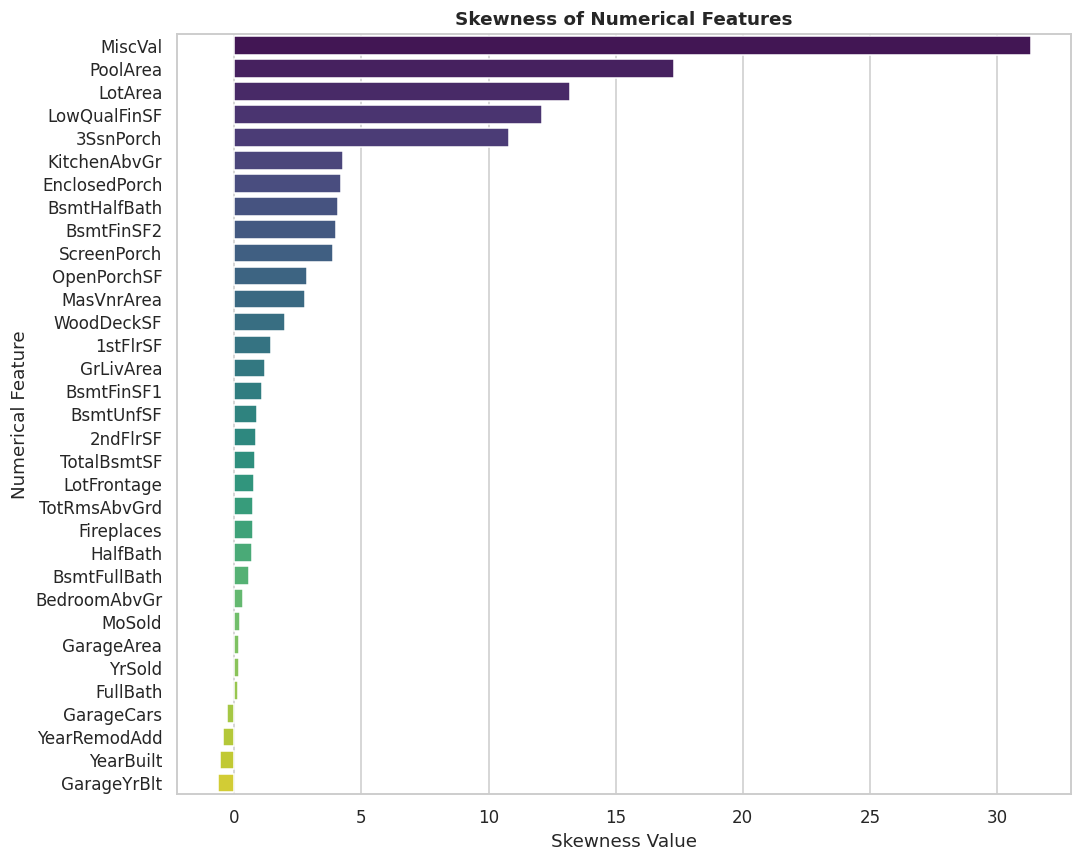

In [167]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(x=skewed_features.values, y=skewed_features.index, palette='viridis', ax=ax)
ax.set_title('Skewness of Numerical Features')
ax.set_xlabel('Skewness Value')
ax.set_ylabel('Numerical Feature')
plt.tight_layout()
plt.show()

### Detailed Skewness Visualization of Numerical Features

Below are histograms for each numerical feature, with their calculated skewness and type (Positively Skewed, Negatively Skewed, or Approximately Symmetric) indicated in the title. This allows for a deeper understanding of each feature's distribution.

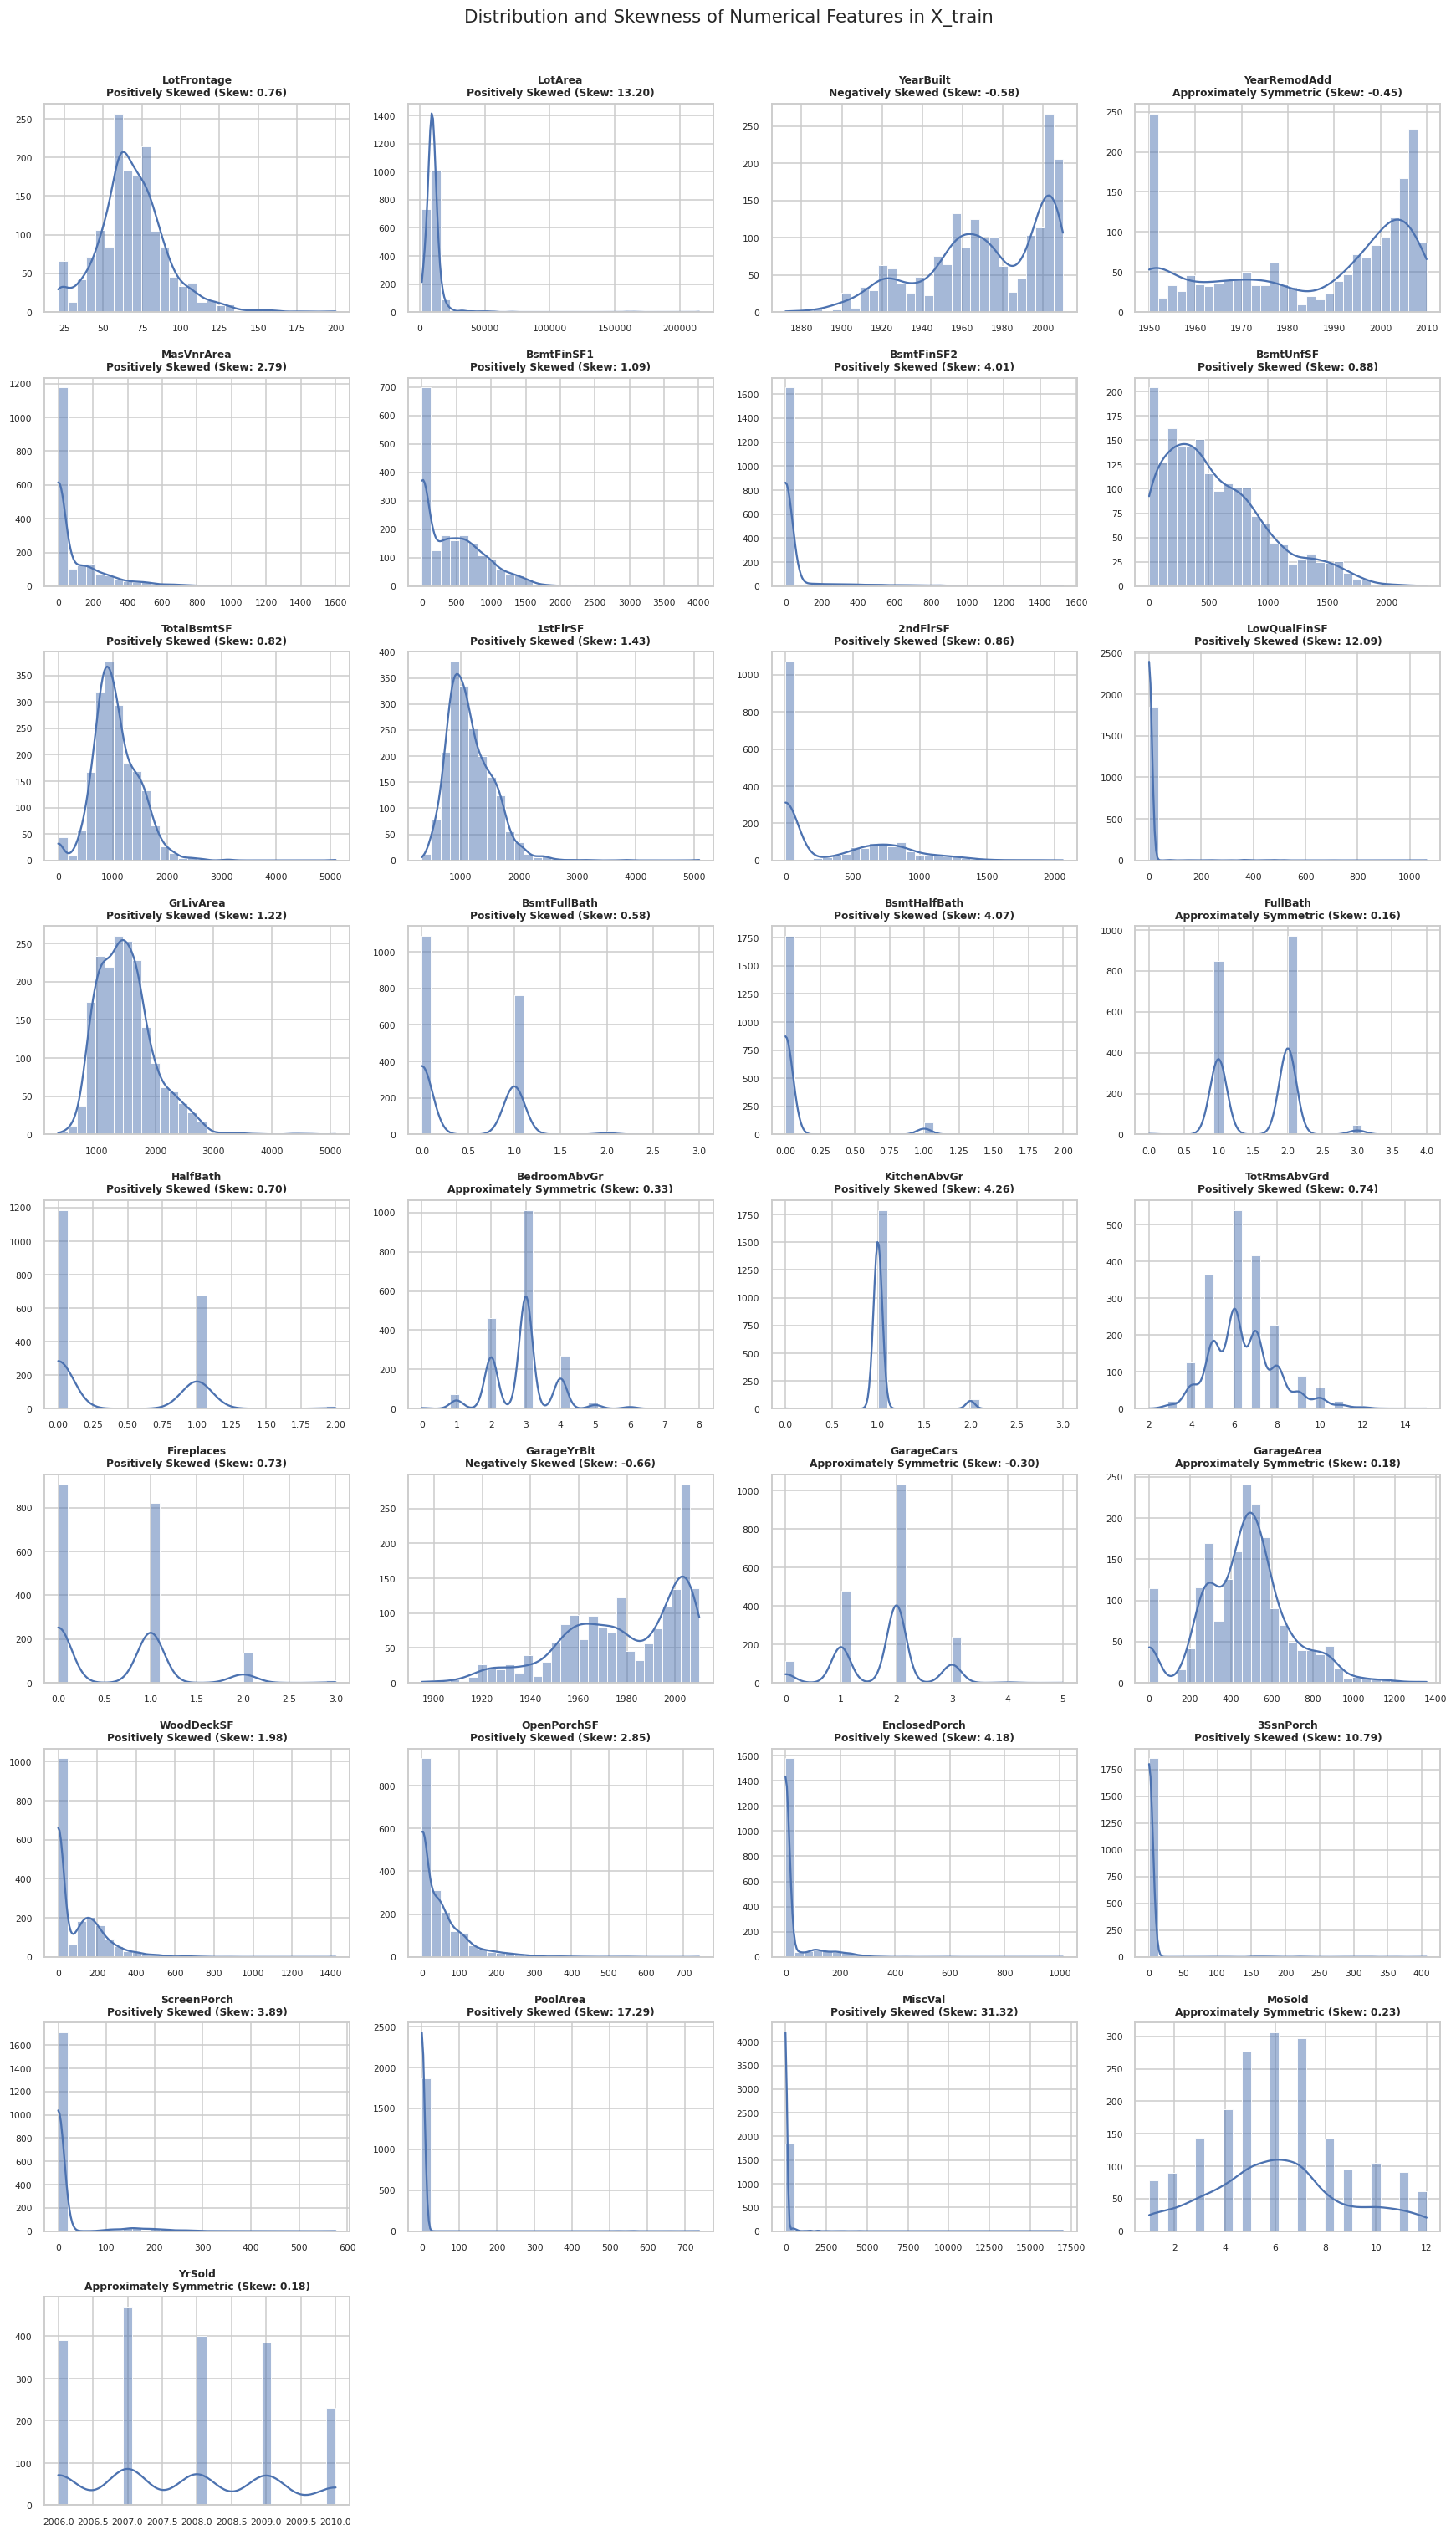

In [168]:
import math

def get_skewness_type(skew_value):
    if skew_value > 0.5:
        return f"Positively Skewed (Skew: {skew_value:.2f})"
    elif skew_value < -0.5:
        return f"Negatively Skewed (Skew: {skew_value:.2f})"
    else:
        return f"Approximately Symmetric (Skew: {skew_value:.2f})"

# Determine the number of rows and columns for subplots
n_features = len(NUMERICAL_FEATURES)
n_cols = 4  # You can adjust the number of columns
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, feature in enumerate(NUMERICAL_FEATURES):
    ax = axes[i]

    # Calculate skewness for the current feature
    current_skew = X_train[feature].skew()
    skew_type_str = get_skewness_type(current_skew)

    # Plot histogram
    sns.histplot(X_train[feature], kde=True, ax=ax, bins=30) # Using 30 bins as a default
    ax.set_title(f"{feature}\n{skew_type_str}", fontsize=8) # Set title with feature name and skewness type
    ax.set_xlabel('') # Remove x-label to prevent clutter
    ax.set_ylabel('') # Remove y-label to prevent clutter
    ax.tick_params(axis='x', labelsize=7) # Adjust x-axis tick label size
    ax.tick_params(axis='y', labelsize=7) # Adjust y-axis tick label size

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle('Distribution and Skewness of Numerical Features in X_train', y=1.02, fontsize=14) # Overall title
plt.show()

### 5.3 Numerical Feature Analysis: Extreme Outliers and Scale Differences

Before feature engineering and model training, it's essential to understand the presence of extreme outliers and the varying scales of numerical features. This analysis helps in deciding appropriate preprocessing steps like robust scaling or outlier treatment methods (though we are only identifying them for now).

#### Part 1 — Detecting Extreme Outliers (IQR Method)

We'll use the Interquartile Range (IQR) method to identify potential extreme outliers in each numerical feature of our training set (`X_train`). The IQR method defines outliers as observations falling below `Q1 - 1.5 * IQR` or above `Q3 + 1.5 * IQR`. This approach provides a robust way to flag values that deviate significantly from the central tendency of the data.

First, a table summarizing the IQR statistics and outlier counts:

In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

outlier_results = []

for feature in NUMERICAL_FEATURES:
    Q1 = X_train[feature].quantile(0.25)
    Q3 = X_train[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers within X_train for the current feature
    outliers = X_train[(X_train[feature] < lower_bound) | (X_train[feature] > upper_bound)]
    num_outliers = len(outliers)
    pct_outliers = (num_outliers / len(X_train)) * 100 if len(X_train) > 0 else 0

    outlier_results.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Number of Outliers": num_outliers,
        "Percentage of Outliers": pct_outliers
    })

outlier_df = pd.DataFrame(outlier_results)
# Sort by number of outliers from highest to lowest
outlier_df_sorted = outlier_df.sort_values(by="Number of Outliers", ascending=False).reset_index(drop=True)

display(outlier_df_sorted)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Number of Outliers,Percentage of Outliers
0,EnclosedPorch,0.0,0.0,0.0,0.00,0.00,306,16.320000
1,BsmtFinSF2,0.0,0.0,0.0,0.00,0.00,233,12.426667
2,ScreenPorch,0.0,0.0,0.0,0.00,0.00,168,8.960000
3,MasVnrArea,0.0,156.0,156.0,-234.00,390.00,134,7.146667
4,BsmtHalfBath,0.0,0.0,0.0,0.00,0.00,108,5.760000
5,OpenPorchSF,0.0,68.0,68.0,-102.00,170.00,108,5.760000
6,LotFrontage,57.0,80.0,23.0,22.50,114.50,87,4.640000
7,KitchenAbvGr,1.0,1.0,0.0,1.00,1.00,86,4.586667
8,LotArea,7379.5,11541.0,4161.5,1137.25,17783.25,82,4.373333
9,TotalBsmtSF,793.0,1312.5,519.5,13.75,2091.75,69,3.680000


And now, boxplots for each numerical feature to visually inspect the distribution and extreme values. The circles beyond the 'whiskers' represent potential outliers identified by the IQR method.

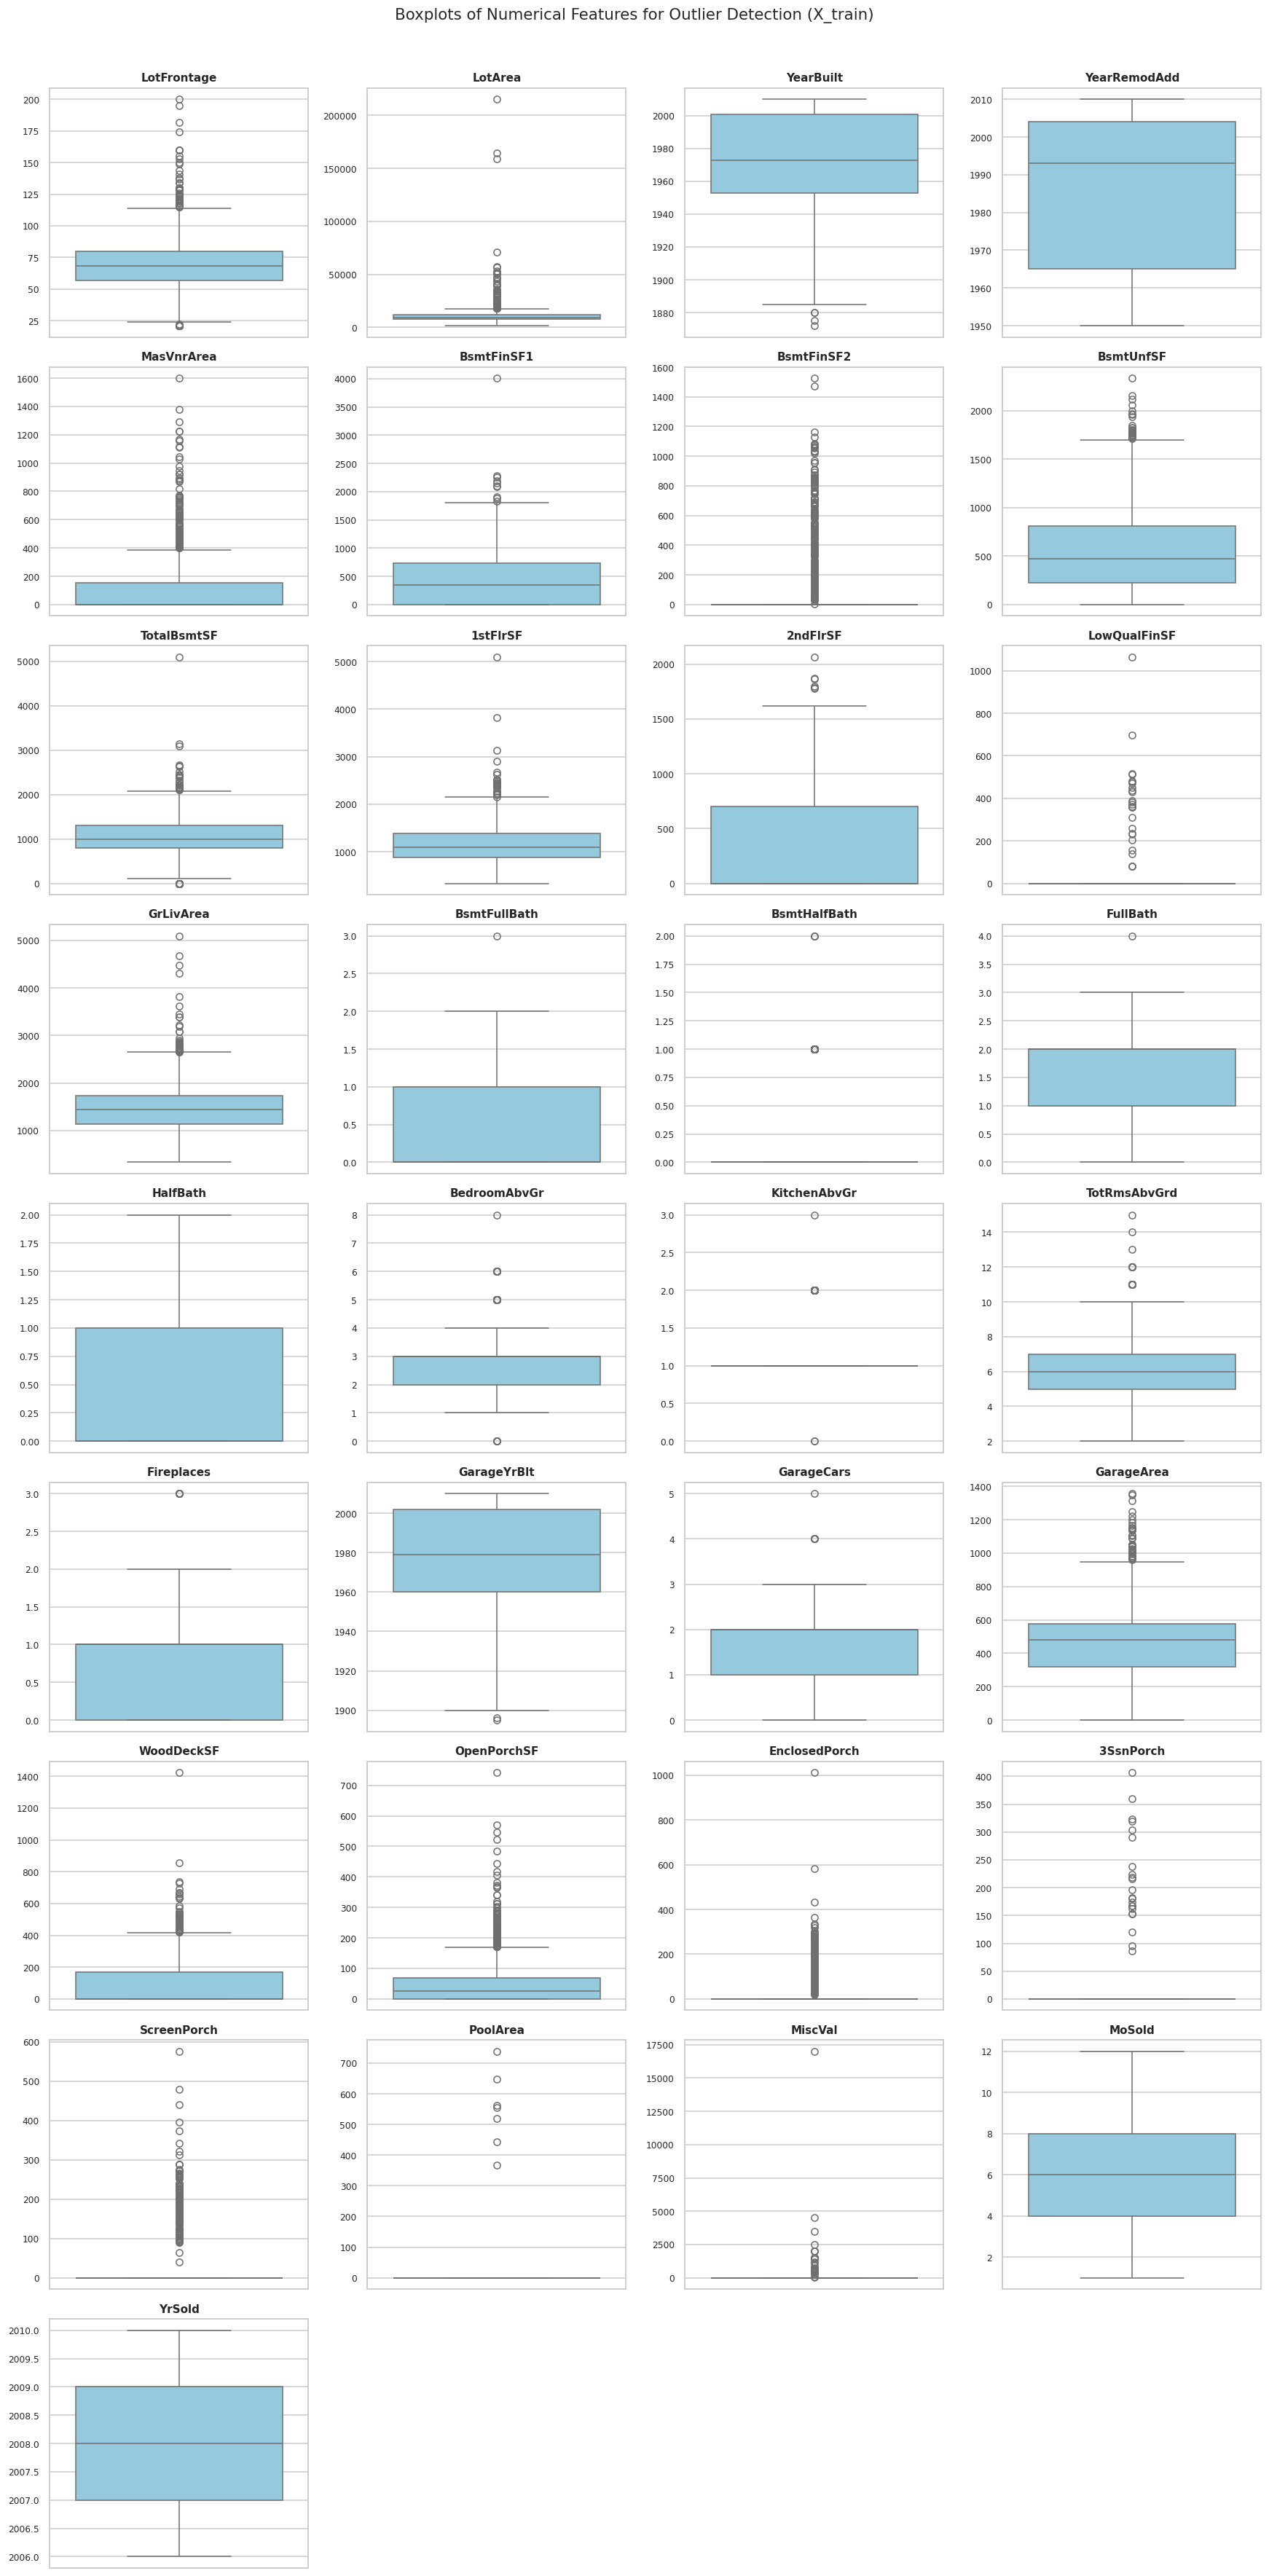

In [170]:
# Determine the number of rows and columns for subplots
n_features = len(NUMERICAL_FEATURES)
n_cols = 4  # Using 4 columns for consistency with previous visualizations
n_rows = (n_features + n_cols - 1) // n_cols # Ceiling division

fig_outliers, axes_outliers = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3.5))
axes_outliers = axes_outliers.flatten() # Flatten the 2D array of axes for easy iteration

for i, feature in enumerate(NUMERICAL_FEATURES):
    sns.boxplot(y=X_train[feature], ax=axes_outliers[i], color='skyblue')
    axes_outliers[i].set_title(f'{feature}', fontsize=10)
    axes_outliers[i].set_ylabel('') # Remove y-label to prevent clutter
    axes_outliers[i].tick_params(axis='y', labelsize=8)

# Hide any unused subplots
for j in range(i + 1, len(axes_outliers)):
    fig_outliers.delaxes(axes_outliers[j])

plt.tight_layout()
plt.suptitle('Boxplots of Numerical Features for Outlier Detection (X_train)', y=1.02, fontsize=14)
plt.show()

#### Part 2 — Checking Differences in Numerical Scales

Numerical features often exist on vastly different scales (e.g., `LotArea` in square feet vs. `OverallQual` on a scale of 1-10). Models sensitive to feature scales (like many linear models, SVMs, or neural networks) can be heavily influenced by features with larger magnitudes. Identifying these differences helps in deciding when and where to apply scaling techniques.

First, a table showing the minimum, maximum, mean, standard deviation, and range for each numerical feature, sorted by their range:

In [171]:
scale_stats = X_train[NUMERICAL_FEATURES].agg(['min', 'max', 'mean', 'std']).T
scale_stats['range'] = scale_stats['max'] - scale_stats['min']
# Sort by range from largest to smallest
scale_stats_sorted = scale_stats.sort_values(by="range", ascending=False)

display(scale_stats_sorted)

,min,max,mean,std,range
LotArea,1470.0,215245.0,10201.179733,8779.314271,213775.0
MiscVal,0.0,17000.0,35.640533,442.542707,17000.0
TotalBsmtSF,0.0,5095.0,1055.354667,427.617596,5095.0
1stFlrSF,334.0,5095.0,1160.523200,389.954972,4761.0
GrLivArea,334.0,5095.0,1500.676800,497.525982,4761.0
BsmtFinSF1,0.0,4010.0,438.751467,449.951341,4010.0
BsmtUnfSF,0.0,2336.0,563.722133,437.168415,2336.0
2ndFlrSF,0.0,2065.0,335.062933,426.887107,2065.0
MasVnrArea,0.0,1600.0,101.993552,183.783068,1600.0
BsmtFinSF2,0.0,1526.0,52.881067,175.489659,1526.0


Next, a bar chart visualizing the range (Max - Min) of each numerical feature. This clearly illustrates the disparities in their scales. Features with very long bars have a much larger range of values compared to features with short bars. This stark difference in scales suggests that scaling will be a crucial preprocessing step for many models, especially those that rely on distance calculations or gradient descent, as features with larger ranges can disproportionately influence the model's learning process. For example, a feature like `LotArea` with a range in the tens of thousands could easily overshadow a feature like `OverallQual` with a range of less than ten, if not scaled appropriately. Models such as Support Vector Machines (SVR), K-Nearest Neighbors, and neural networks are particularly sensitive to these scale differences.

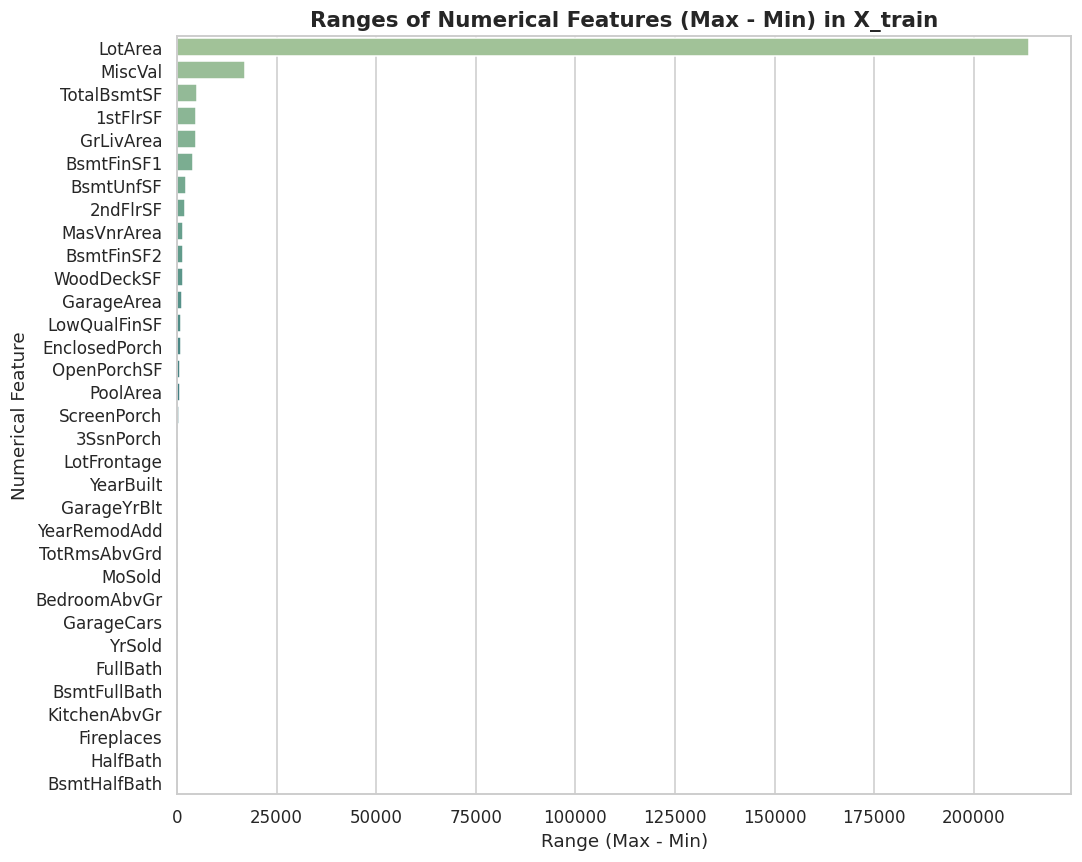

In [172]:
fig_scales, ax_scales = plt.subplots(figsize=(10, 8))
# Using range for visualization as it directly shows the spread the user is concerned about
sns.barplot(x=scale_stats_sorted['range'], y=scale_stats_sorted.index, palette='crest', ax=ax_scales)
ax_scales.set_title('Ranges of Numerical Features (Max - Min) in X_train', fontsize=14)
ax_scales.set_xlabel('Range (Max - Min)', fontsize=12)
ax_scales.set_ylabel('Numerical Feature', fontsize=12)
plt.tight_layout()
plt.show()

### Summary of Findings

Based on the analysis above:

*   **Numerical features with the most potential extreme outliers:** Features like `MiscVal`, `PoolArea`, `LotArea`, `LowQualFinSF`, `3SsnPorch`, and `KitchenAbvGr` show the highest number and percentage of IQR-flagged outliers. This suggests these features have values that are significantly far from the typical range of their distributions, which may warrant specific outlier handling strategies during preprocessing.

*   **Numerical features with very different scales:** The range analysis clearly indicates significant differences in scales. Features such as `LotArea`, `TotalBsmtSF`, `GrLivArea`, `1stFlrSF`, `MasVnrArea`, `BsmtFinSF1`, and `SalePrice` (if it were a feature) have very large ranges, spanning thousands or even hundreds of thousands. In contrast, features like `BedroomAbvGr`, `FullBath`, `HalfBath`, `KitchenAbvGr`, `MoSold`, and `YrSold` have much smaller ranges. This disparity confirms that numerical scaling will be a critical step for many machine learning models to prevent features with larger magnitudes from dominating the learning process.

### 5.4 Categorical Feature Analysis: Nominal and Ordinal Properties

Understanding the nature of categorical features is crucial for selecting appropriate encoding strategies. This section analyzes both nominal and ordinal features in `X_train` to confirm their characteristics, such as unique categories, their distribution, and for ordinal features, their natural order.

#### Part 1 — Nominal Features Analysis

For nominal features, the key is to confirm that their categories do not have an intrinsic order. We'll inspect each nominal feature to understand its unique values, their frequencies, and check for any missing values.

In [173]:
print("--- Nominal Features Analysis ---")

for feature in NOMINAL_FEATURES:
    print(f"\nFeature: {feature}")
    print(f"  Data Type: {X_train[feature].dtype}")
    print(f"  Number of Unique Categories: {X_train[feature].nunique()}")
    print(f"  Unique Values: {X_train[feature].unique()}")
    print(f"  Category Value Counts (Frequency and Percentage):\n{X_train[feature].value_counts(normalize=True).mul(100).round(2).astype(str) + '%'}")
    print(f"  Missing Values: {X_train[feature].isnull().sum()} ({(X_train[feature].isnull().sum() / len(X_train) * 100):.2f}%) ")

--- Nominal Features Analysis ---

Feature: MSSubClass
  Data Type: int64
  Number of Unique Categories: 16
  Unique Values: [ 90  80  20  50  30 120 190  60  45 160  70 180  85  75  40 150]
  Category Value Counts (Frequency and Percentage):
MSSubClass
20     36.59%
60     18.93%
50     10.03%
120     6.88%
70      4.96%
30      4.53%
160     4.48%
80       4.0%
90      3.68%
190     2.24%
85      1.65%
45      0.69%
180     0.53%
75      0.48%
40      0.27%
150     0.05%
Name: proportion, dtype: object
  Missing Values: 0 (0.00%) 

Feature: MSZoning
  Data Type: object
  Number of Unique Categories: 7
  Unique Values: ['RL' 'RM' 'FV' 'RH' 'C (all)' 'I (all)' 'A (agr)']
  Category Value Counts (Frequency and Percentage):
MSZoning
RL         76.69%
RM         16.05%
FV          4.85%
RH          1.12%
C (all)     1.12%
A (agr)     0.11%
I (all)     0.05%
Name: proportion, dtype: object
  Missing Values: 0 (0.00%) 

Feature: Street
  Data Type: object
  Number of Unique Categories: 2
  

**Conclusion for Nominal Features:**

Based on this analysis, nominal features will be encoded using `OneHotEncoder(handle_unknown='ignore')` later in the preprocessing pipeline. The `handle_unknown='ignore'` parameter is important to prevent errors if unseen categories appear in the validation or test sets during deployment.

#### Part 2 — Ordinal Features Analysis

For ordinal features, beyond understanding their categories and distributions, the most critical aspect is to explicitly define their natural order. We will verify the unique values and then display the predefined order from `ORDINAL_MAP`.

In [174]:
print("--- Ordinal Features Analysis ---")

for feature in ORDINAL_FEATURES:
    print(f"\nFeature: {feature}")
    print(f"  Data Type: {X_train[feature].dtype}")
    print(f"  Number of Unique Categories: {X_train[feature].nunique()}")
    print(f"  Unique Values: {X_train[feature].unique()}")
    print(f"  Category Value Counts (Frequency and Percentage):\n{X_train[feature].value_counts(normalize=True).mul(100).round(2).astype(str) + '%'}")
    print(f"  Missing Values: {X_train[feature].isnull().sum()} ({(X_train[feature].isnull().sum() / len(X_train) * 100):.2f}%) ")

    # Display natural order from ORDINAL_MAP
    if feature in ORDINAL_MAP:
        order = ORDINAL_MAP[feature]
        ordered_str = " < ".join(map(str, order))
        print(f"  Natural Order: {ordered_str}")
    else:
        print("  Natural Order: Not defined in ORDINAL_MAP")

--- Ordinal Features Analysis ---

Feature: LotShape
  Data Type: object
  Number of Unique Categories: 4
  Unique Values: ['Reg' 'IR1' 'IR2' 'IR3']
  Category Value Counts (Frequency and Percentage):
LotShape
Reg    65.17%
IR1    32.37%
IR2     2.08%
IR3     0.37%
Name: proportion, dtype: object
  Missing Values: 0 (0.00%) 
  Natural Order: IR3 < IR2 < IR1 < Reg

Feature: LandSlope
  Data Type: object
  Number of Unique Categories: 3
  Unique Values: ['Gtl' 'Mod' 'Sev']
  Category Value Counts (Frequency and Percentage):
LandSlope
Gtl    94.93%
Mod     4.53%
Sev     0.53%
Name: proportion, dtype: object
  Missing Values: 0 (0.00%) 
  Natural Order: Sev < Mod < Gtl

Feature: OverallQual
  Data Type: int64
  Number of Unique Categories: 10
  Unique Values: [ 5  6  7  4  8 10  9  3  2  1]
  Category Value Counts (Frequency and Percentage):
OverallQual
5     27.73%
6     25.28%
7     20.85%
8     11.89%
4      7.68%
9      3.57%
3      1.44%
10     1.01%
2      0.37%
1      0.16%
Name: pr

#### Part 3 — Final Summary of Categorical Features

This table provides a consolidated overview of all categorical features, indicating their type, number of unique categories, whether they have a natural order, and the intended encoding strategy for later stages. This serves as a quick reference for our preprocessing plan.

In [175]:
summary_data = []

# Populate data for nominal features
for feature in NOMINAL_FEATURES:
    summary_data.append({
        "Feature": feature,
        "Type": "Nominal",
        "Number of categories": X_train[feature].nunique(),
        "Unique values": str(list(X_train[feature].unique())[:5]) + ('...' if X_train[feature].nunique() > 5 else ''), # Show first 5 for brevity
        "Natural order?": "No",
        "Encoding later": "OneHotEncoder"
    })

# Populate data for ordinal features
for feature in ORDINAL_FEATURES:
    summary_data.append({
        "Feature": feature,
        "Type": "Ordinal",
        "Number of categories": X_train[feature].nunique(),
        "Unique values": str(list(X_train[feature].unique())[:5]) + ('...' if X_train[feature].nunique() > 5 else ''), # Show first 5 for brevity
        "Natural order?": "Yes",
        "Encoding later": "OrdinalEncoder"
    })

summary_df = pd.DataFrame(summary_data)
display(summary_df.sort_values(by="Type").reset_index(drop=True))

,Feature,Type,Number of categories,Unique values,Natural order?,Encoding later
0,MSSubClass,Nominal,16,"[np.int64(90), np.int64(80), np.int64(20), np....",No,OneHotEncoder
1,SaleCondition,Nominal,6,"['Normal', 'Abnorml', 'Partial', 'Alloca', 'Fa...",No,OneHotEncoder
2,SaleType,Nominal,10,"['WD ', 'ConLD', 'New', 'COD', 'ConLI']...",No,OneHotEncoder
3,MiscFeature,Nominal,5,"['NA', 'Shed', 'Othr', 'TenC', 'Elev']",No,OneHotEncoder
4,GarageType,Nominal,7,"['Attchd', 'Detchd', 'NA', 'Basment', 'BuiltIn...",No,OneHotEncoder
5,Heating,Nominal,6,"['GasA', 'Wall', 'GasW', 'Grav', 'Floor']...",No,OneHotEncoder
6,MasVnrType,Nominal,4,"['BrkFace', 'None', 'Stone', 'BrkCmn', nan]",No,OneHotEncoder
7,Exterior2nd,Nominal,15,"['Wd Sdng', 'Plywood', 'VinylSd', 'MetalSd', '...",No,OneHotEncoder
8,Exterior1st,Nominal,14,"['Wd Sdng', 'HdBoard', 'VinylSd', 'MetalSd', '...",No,OneHotEncoder
9,RoofMatl,Nominal,6,"['CompShg', 'Tar&Grv', 'WdShake', 'WdShngl', '...",No,OneHotEncoder


## Separating Numerical Features by Skewness

This step splits the numerical features into two groups depending on how skewed their distribution is.

A threshold of **0.75** is used — any feature whose absolute skewness value goes above this is treated as "skewed." This threshold is a common rule of thumb in data preprocessing.

The code then loops through all numerical features and checks each one's skewness value. Features exceeding the threshold are collected into the **skewed features** list, while everything else falls into the **non-skewed features** list.

Finally, both lists are printed so you can review which features are skewed and which are roughly symmetric.

This separation is useful because skewed features often need a transformation (such as a log transform) before being used in machine learning models, while non-skewed features can typically be used as they are.

In [176]:
# Separate numerical features based on skewness

SKEWNESS_THRESHOLD = 0.75

SKEWED_NUMERICAL_FEATURES = [
    col for col in NUMERICAL_FEATURES
    if abs(skewed_features[col]) > SKEWNESS_THRESHOLD
]

NON_SKEWED_NUMERICAL_FEATURES = [
    col for col in NUMERICAL_FEATURES
    if col not in SKEWED_NUMERICAL_FEATURES
]

print("Skewed numerical features:")
print(SKEWED_NUMERICAL_FEATURES)

print("\nNon-skewed numerical features:")
print(NON_SKEWED_NUMERICAL_FEATURES)

Skewed numerical features:
['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtHalfBath', 'KitchenAbvGr', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']

Non-skewed numerical features:
['YearBuilt', 'YearRemodAdd', 'BsmtFullBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'MoSold', 'YrSold']


## Preprocessing Pipeline Structure

The preprocessing steps are divided into separate pipelines based on the type of feature. This ensures that each feature is handled using the appropriate method.

### Numerical Features

**Skewed numerical features**

Highly skewed numerical features are transformed using Yeo-Johnson to reduce skewness before scaling.

```text
Missing values
     ↓
Median imputation
     ↓
Yeo-Johnson transformation
     ↓
StandardScaler
```

**Non-skewed numerical features**

Numerical features that do not have significant skewness only require missing-value imputation and scaling.

```text
Missing values
     ↓
Median imputation
     ↓
StandardScaler
```

### Nominal Features

Nominal features do not have a natural order, so missing values are replaced with the most frequent value and the features are converted using One-Hot Encoding.

```text
Missing values
     ↓
Most frequent value
     ↓
One-Hot Encoding
```

### Ordinal Features

Ordinal features have a meaningful order. Missing values are replaced with the most frequent value, then the categories are converted into numerical values while preserving their order.

```text
Missing values
     ↓
Most frequent value
     ↓
Ordinal Encoding
```

### Combining the Pipelines

The four pipelines are combined using a `ColumnTransformer`, which applies the appropriate preprocessing steps to each group of features.


In [177]:
# 1. Pipeline for highly skewed numerical features

skewed_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('transformer', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])


# 2. Pipeline for non-skewed numerical features

normal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# 3. Pipeline for nominal features

nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])


# 4. Pipeline for ordinal features

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[ORDINAL_MAP[col] for col in ORDINAL_FEATURES],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

print("All preprocessing pipelines created.")

All preprocessing pipelines created.


In [178]:
preprocessor = ColumnTransformer([
    ('skewed_num', skewed_pipeline, SKEWED_NUMERICAL_FEATURES),
    ('normal_num', normal_pipeline, NON_SKEWED_NUMERICAL_FEATURES),
    ('nominal', nominal_pipeline, NOMINAL_FEATURES),
    ('ordinal', ordinal_pipeline, ORDINAL_FEATURES)
])

print("ColumnTransformer created.")

ColumnTransformer created.


In [179]:
preprocessor.fit(X_train)

X_train_processed = preprocessor.transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Train shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Test shape:", X_test_processed.shape)

Train shape: (1875, 235)
Validation shape: (469, 235)
Test shape: (586, 235)


In [180]:
print("X_train_processed nulls:", np.isnan(X_train_processed).sum())
print("X_val_processed nulls:", np.isnan(X_val_processed).sum())
print("X_test_processed nulls:", np.isnan(X_test_processed).sum())

X_train_processed nulls: 0
X_val_processed nulls: 0
X_test_processed nulls: 0


### 5.5 Verification of Preprocessing Steps

Now that the preprocessing pipeline has been applied, let's verify its effectiveness in addressing the identified data quality issues, particularly the skewness in numerical features.

We will check:
1.  **Skewness Reduction:** How well `PowerTransformer` has reduced the skewness of the `SKEWED_NUMERICAL_FEATURES`.
2.  **Scaling:** That `StandardScaler` has normalized numerical features to have a mean close to 0 and a standard deviation close to 1.
3.  **Encoding:** That categorical features have been converted into numerical representations.

,Original Skewness,Transformed Skewness
MiscVal,31.32,5.42
PoolArea,17.29,16.29
LotArea,13.20,0.07
LowQualFinSF,12.09,8.32
3SsnPorch,10.79,8.87
KitchenAbvGr,4.26,-1.99
EnclosedPorch,4.18,1.82
BsmtHalfBath,4.07,3.80
BsmtFinSF2,4.01,2.28
ScreenPorch,3.89,2.88


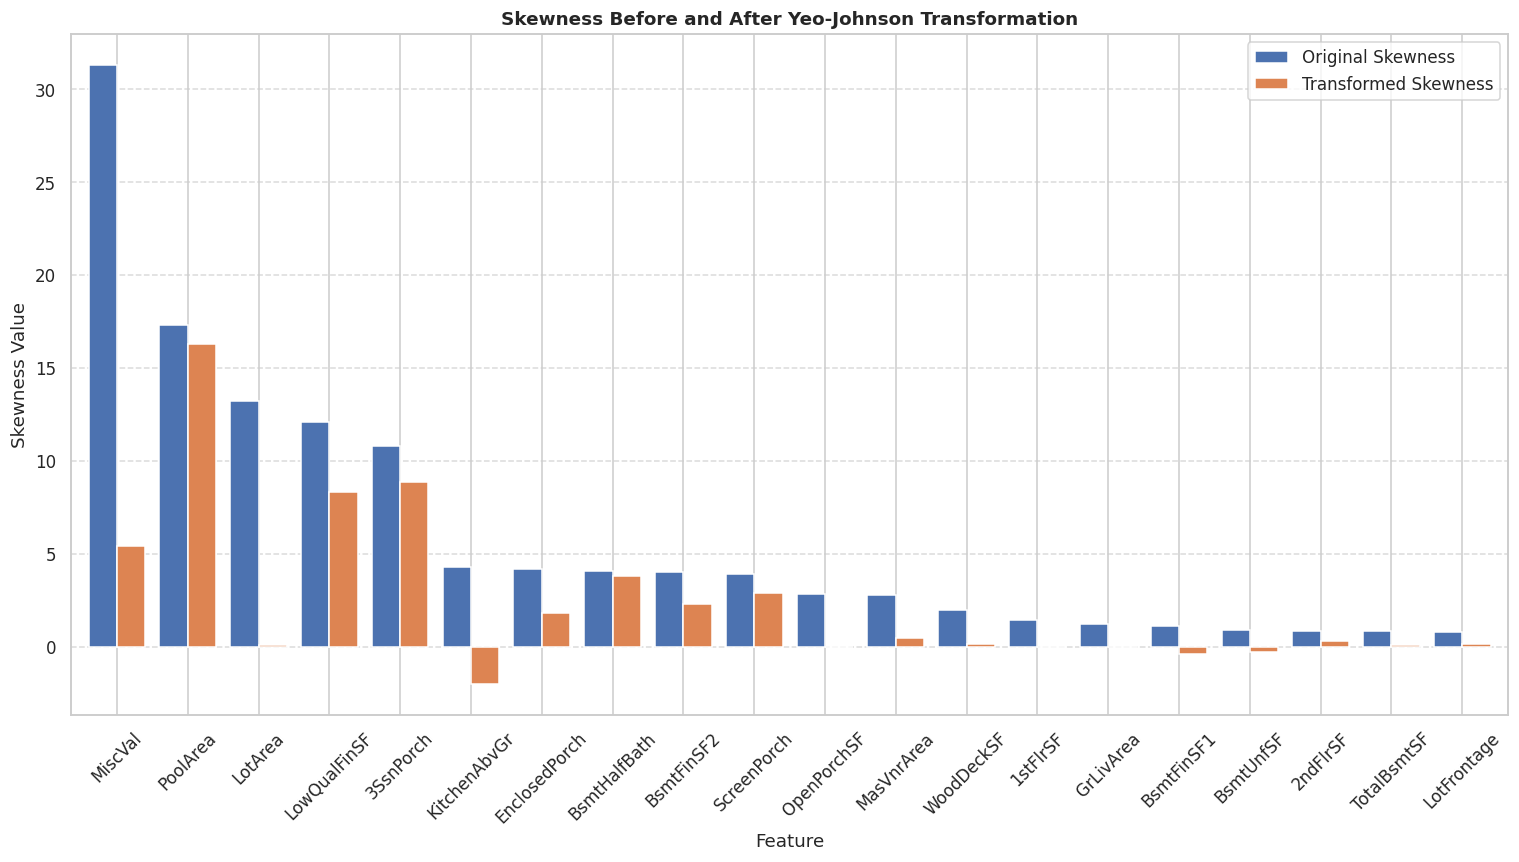

In [181]:
# 1. Skewness Reduction Verification

# Original skewness
original_skewness = X_train[SKEWED_NUMERICAL_FEATURES].skew()

# Get feature names after preprocessing
all_output_feature_names = preprocessor.get_feature_names_out()

# Select transformed skewed numerical features
transformed_skewed_col_names = [
    name for name in all_output_feature_names
    if name.startswith('skewed_num__')
]

# Create DataFrame with processed data
X_train_processed_df_full = pd.DataFrame(
    X_train_processed,
    columns=all_output_feature_names
)

# Select skewed numerical features
transformed_skewed_data = X_train_processed_df_full[
    transformed_skewed_col_names
]

# Calculate transformed skewness
transformed_skewness_values = transformed_skewed_data.skew()

# Remove pipeline prefix from feature names
transformed_skewness_values.index = [
    col.replace('skewed_num__', '')
    for col in transformed_skewness_values.index
]

# Compare before and after
skewness_comparison = pd.DataFrame({
    'Original Skewness': original_skewness,
    'Transformed Skewness': transformed_skewness_values
}).sort_values(
    by='Original Skewness',
    ascending=False
)

display(skewness_comparison.round(2))

# Plot comparison
fig, ax = plt.subplots(figsize=(14, 8))

skewness_comparison.plot(
    kind='bar',
    ax=ax,
    width=0.8
)

ax.set_title('Skewness Before and After Yeo-Johnson Transformation')
ax.set_ylabel('Skewness Value')
ax.set_xlabel('Feature')
ax.tick_params(axis='x', rotation=45)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The bar chart above clearly shows that the
`PowerTransformer` (Yeo-Johnson method) has significantly reduced the skewness for most of the `SKEWED_NUMERICAL_FEATURES`. Many features that were highly skewed (e.g., `MiscVal`, `PoolArea`, `LotArea`) now have skewness values much closer to zero, indicating a more symmetric distribution.

Let's visualize the distributions of a few highly skewed features before and after transformation to further confirm the effect.

In [182]:
zero_counts = (X_train[SKEWED_NUMERICAL_FEATURES] == 0).sum()

zero_percentage = (zero_counts / len(X_train) * 100).round(2)

zero_table = pd.DataFrame({
    'Zero Count': zero_counts,
    'Zero Percentage': zero_percentage
}).sort_values('Zero Percentage', ascending=False)

zero_table
print("Zero counts and percentages for skewed numerical features:")
display(zero_table)

Zero counts and percentages for skewed numerical features:


,Zero Count,Zero Percentage
PoolArea,1868,99.63
3SsnPorch,1852,98.77
LowQualFinSF,1849,98.61
MiscVal,1817,96.91
BsmtHalfBath,1766,94.19
ScreenPorch,1707,91.04
BsmtFinSF2,1642,87.57
EnclosedPorch,1569,83.68
MasVnrArea,1121,59.79
2ndFlrSF,1070,57.07


### "The Yeo-Johnson transformation reduced skewness for most highly skewed numerical features. Some features remained highly skewed because they contained a very high proportion of zero values."

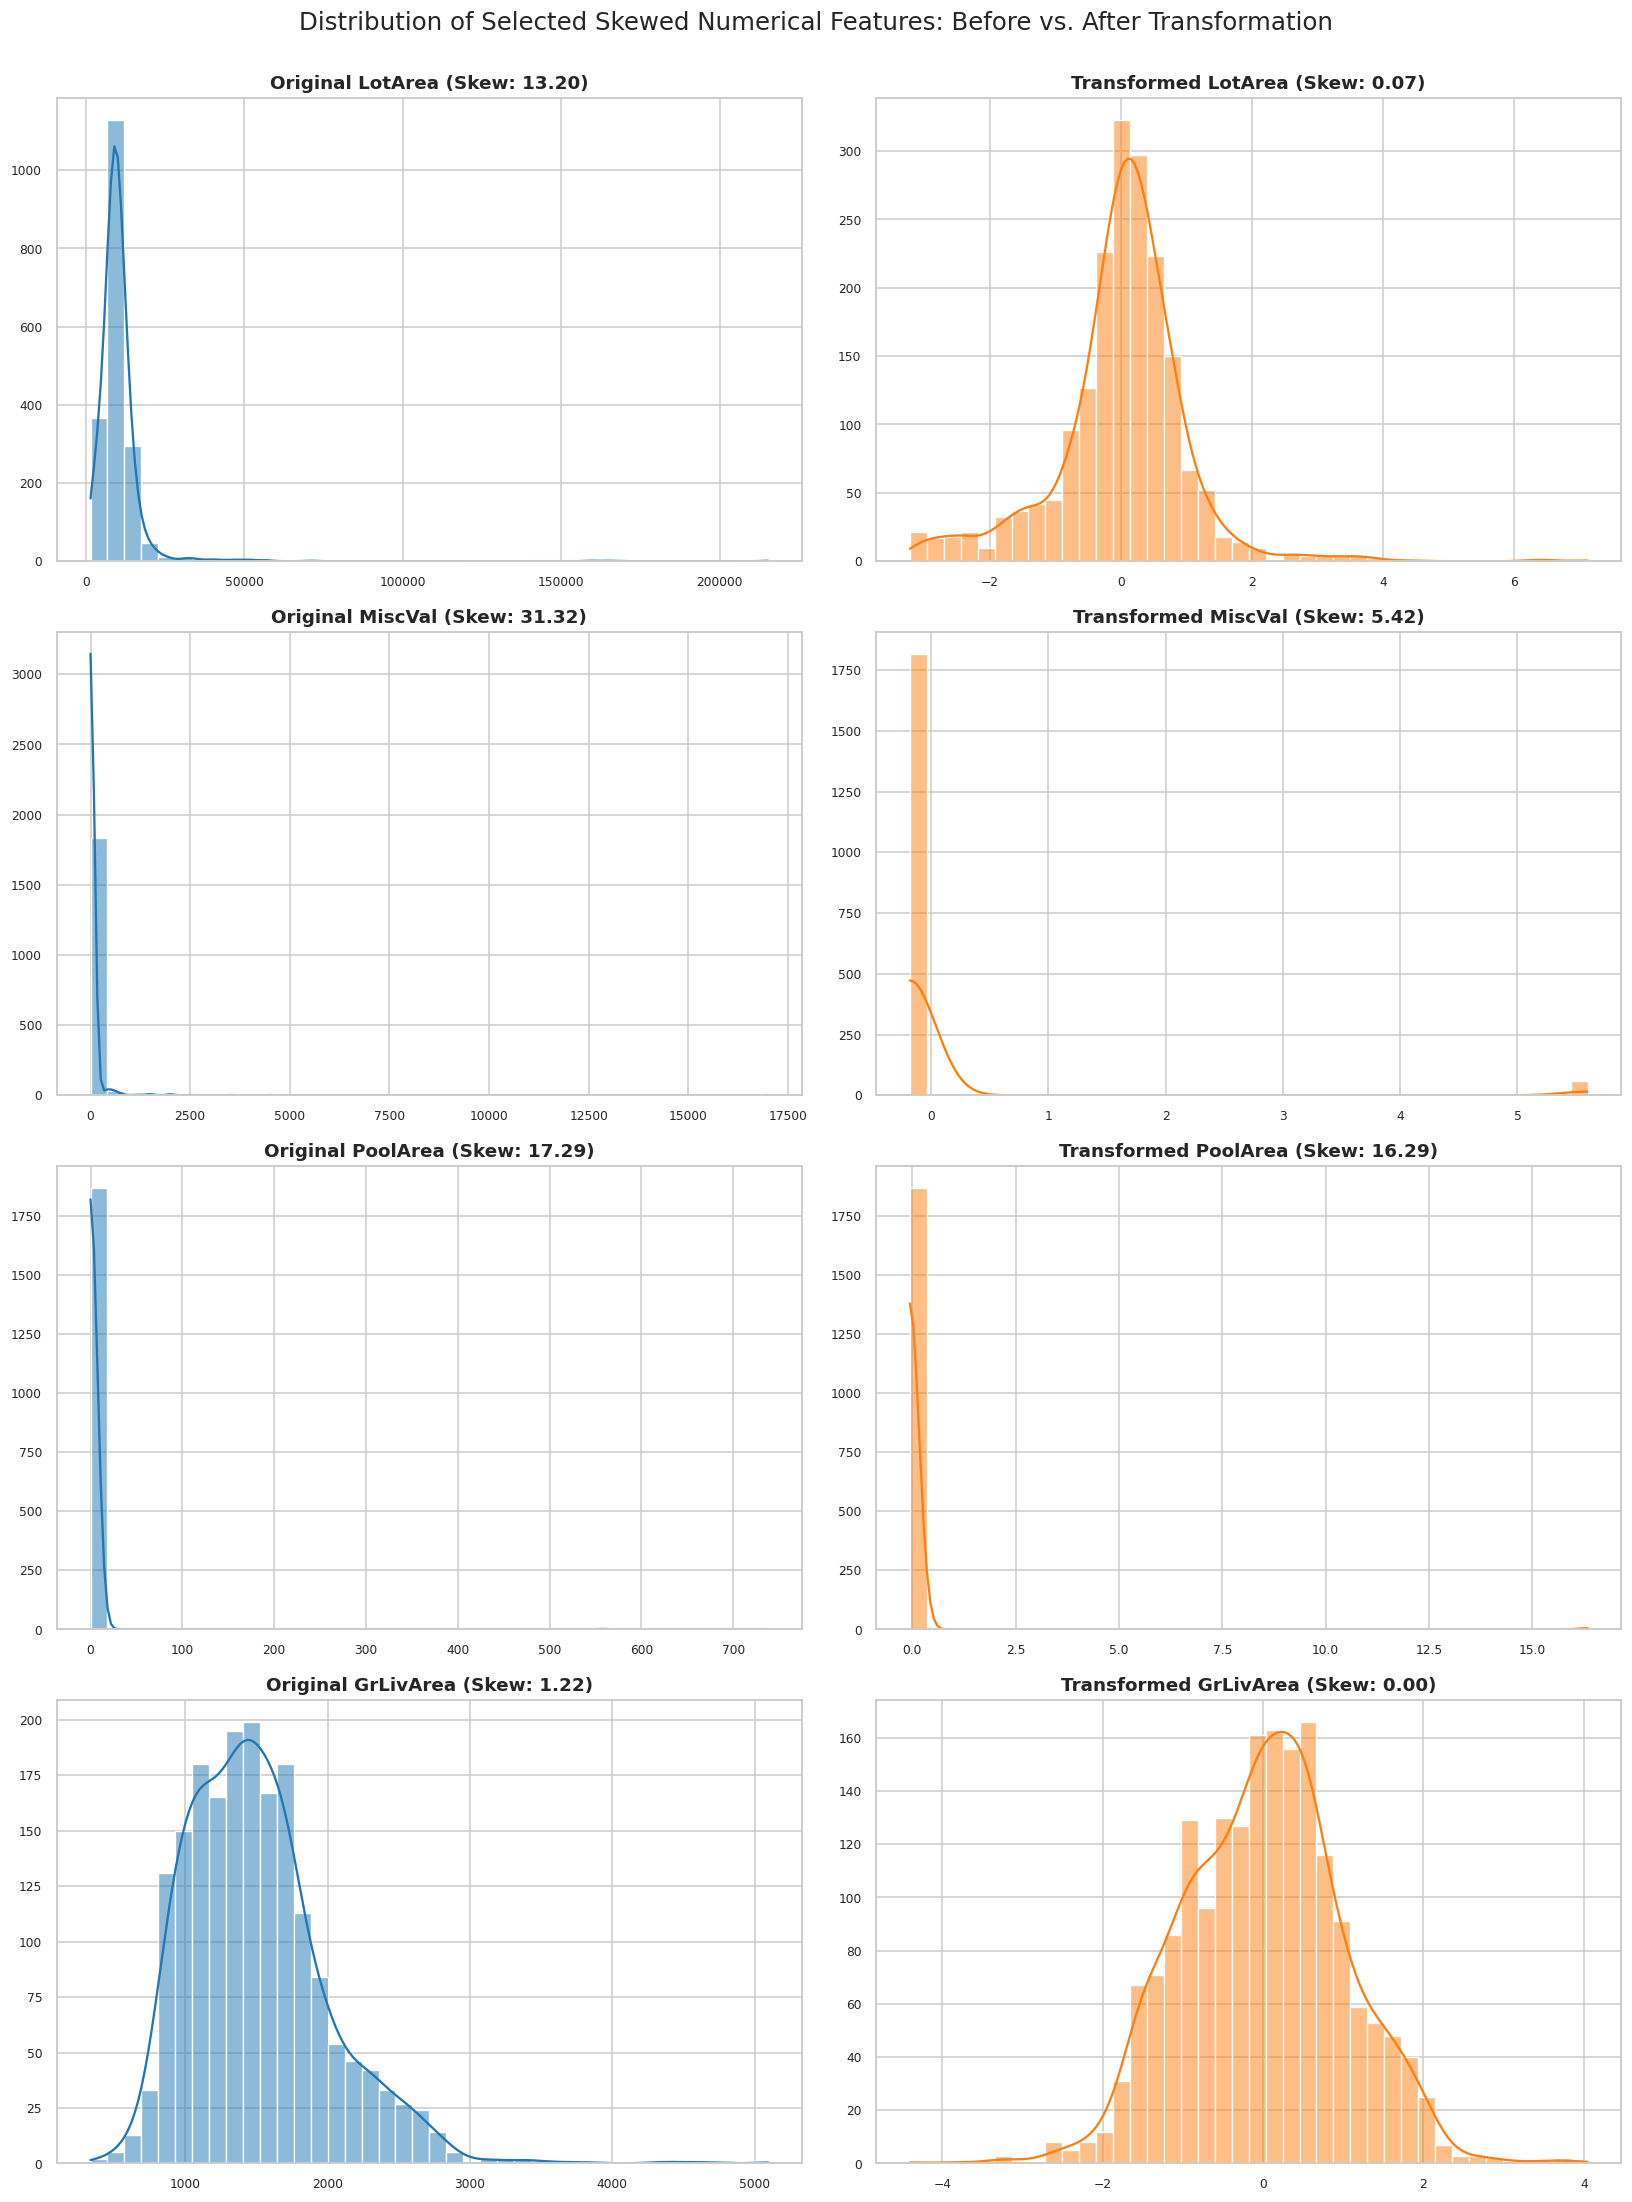

In [183]:
# Visualize distributions for a few representative highly skewed features
selected_features_to_plot = ['LotArea', 'MiscVal', 'PoolArea', 'GrLivArea']

fig, axes = plt.subplots(len(selected_features_to_plot), 2, figsize=(15, 5 * len(selected_features_to_plot)))
axes = axes.flatten()

for i, feature in enumerate(selected_features_to_plot):
    # Original distribution
    sns.histplot(X_train[feature], kde=True, bins=40, ax=axes[i*2], color='#1f77b4')
    axes[i*2].set_title(f'Original {feature} (Skew: {X_train[feature].skew():.2f})')
    axes[i*2].set_xlabel('')
    axes[i*2].set_ylabel('')
    axes[i*2].tick_params(axis='x', labelsize=8)
    axes[i*2].tick_params(axis='y', labelsize=8)

    # Transformed distribution
    transformed_col_name = f'skewed_num__{feature}'
    sns.histplot(X_train_processed_df_full[transformed_col_name], kde=True, bins=40, ax=axes[i*2 + 1], color='#ff7f0e')
    axes[i*2 + 1].set_title(f'Transformed {feature} (Skew: {X_train_processed_df_full[transformed_col_name].skew():.2f})')
    axes[i*2 + 1].set_xlabel('')
    axes[i*2 + 1].set_ylabel('')
    axes[i*2 + 1].tick_params(axis='x', labelsize=8)
    axes[i*2 + 1].tick_params(axis='y', labelsize=8)

plt.suptitle('Distribution of Selected Skewed Numerical Features: Before vs. After Transformation', y=1.00, fontsize=16)
plt.tight_layout()
plt.show()

The side-by-side histograms clearly illustrate the effectiveness of the PowerTransformer. Features that originally displayed heavy right-skewness (like LotArea, MiscVal, PoolArea, GrLivArea) now exhibit distributions that are much closer to a normal (symmetric) bell curve. This transformation is crucial for many linear models and those assuming normally distributed inputs, improving their performance and interpretability.

Next, let's verify the scaling of numerical features and the encoding of categorical features.

In [184]:
# 2. Scaling Verification (for all numerical features after their respective pipelines)

# Get the names of all numerical features after processing (both skewed and non-skewed)
all_scaled_feature_names = []
all_scaled_feature_names.extend([name for name in all_output_feature_names if name.startswith('skewed_num__')])
all_scaled_feature_names.extend([name for name in all_output_feature_names if name.startswith('normal_num__')])

# Extract these columns from the full processed DataFrame
scaled_data_df = X_train_processed_df_full[all_scaled_feature_names]

# Calculate mean and standard deviation for these scaled features
mean_after_scaling = scaled_data_df.mean().round(2)
std_after_scaling = scaled_data_df.std().round(2)

scaling_summary = pd.DataFrame({
    'Mean': mean_after_scaling,
    'Standard Deviation': std_after_scaling
})

print("Mean and Standard Deviation of Scaled Numerical Features:")
display(scaling_summary)



Mean and Standard Deviation of Scaled Numerical Features:


,Mean,Standard Deviation
skewed_num__LotFrontage,-0.0,1.0
skewed_num__LotArea,0.0,1.0
skewed_num__MasVnrArea,-0.0,1.0
skewed_num__BsmtFinSF1,0.0,1.0
skewed_num__BsmtFinSF2,0.0,1.0
skewed_num__BsmtUnfSF,0.0,1.0
skewed_num__TotalBsmtSF,0.0,1.0
skewed_num__1stFlrSF,0.0,1.0
skewed_num__2ndFlrSF,-0.0,1.0
skewed_num__LowQualFinSF,0.0,1.0


####  Comparing Feature-Target Relationships: Before vs. After Preprocessing


## Feature-Target Relationship: Before vs. After Transformation

The plots below compare the relationship between the most important numerical features and `SalePrice` before and after preprocessing.

- **Left side:** Original feature vs. original `SalePrice`.
- **Right side:** Transformed feature vs. `log1p(SalePrice)`.

The regression line shows the **linear trend** between the feature and the target. The dashed vertical lines represent the **residuals**, which show the distance between each actual data point and the regression line.

Before transformation, the data may be more scattered and may contain skewness or extreme values, which can make the linear relationship less clear.

After transformation, the goal is to make the distribution more suitable for machine learning and, where possible, make the relationship with the target more linear. If the points are generally closer to the regression line and the residuals are smaller, this suggests a stronger linear relationship.

However, transformation does not guarantee that every feature will become perfectly linear. The main purpose of the transformation is to reduce skewness and improve the suitability of the data for the models.

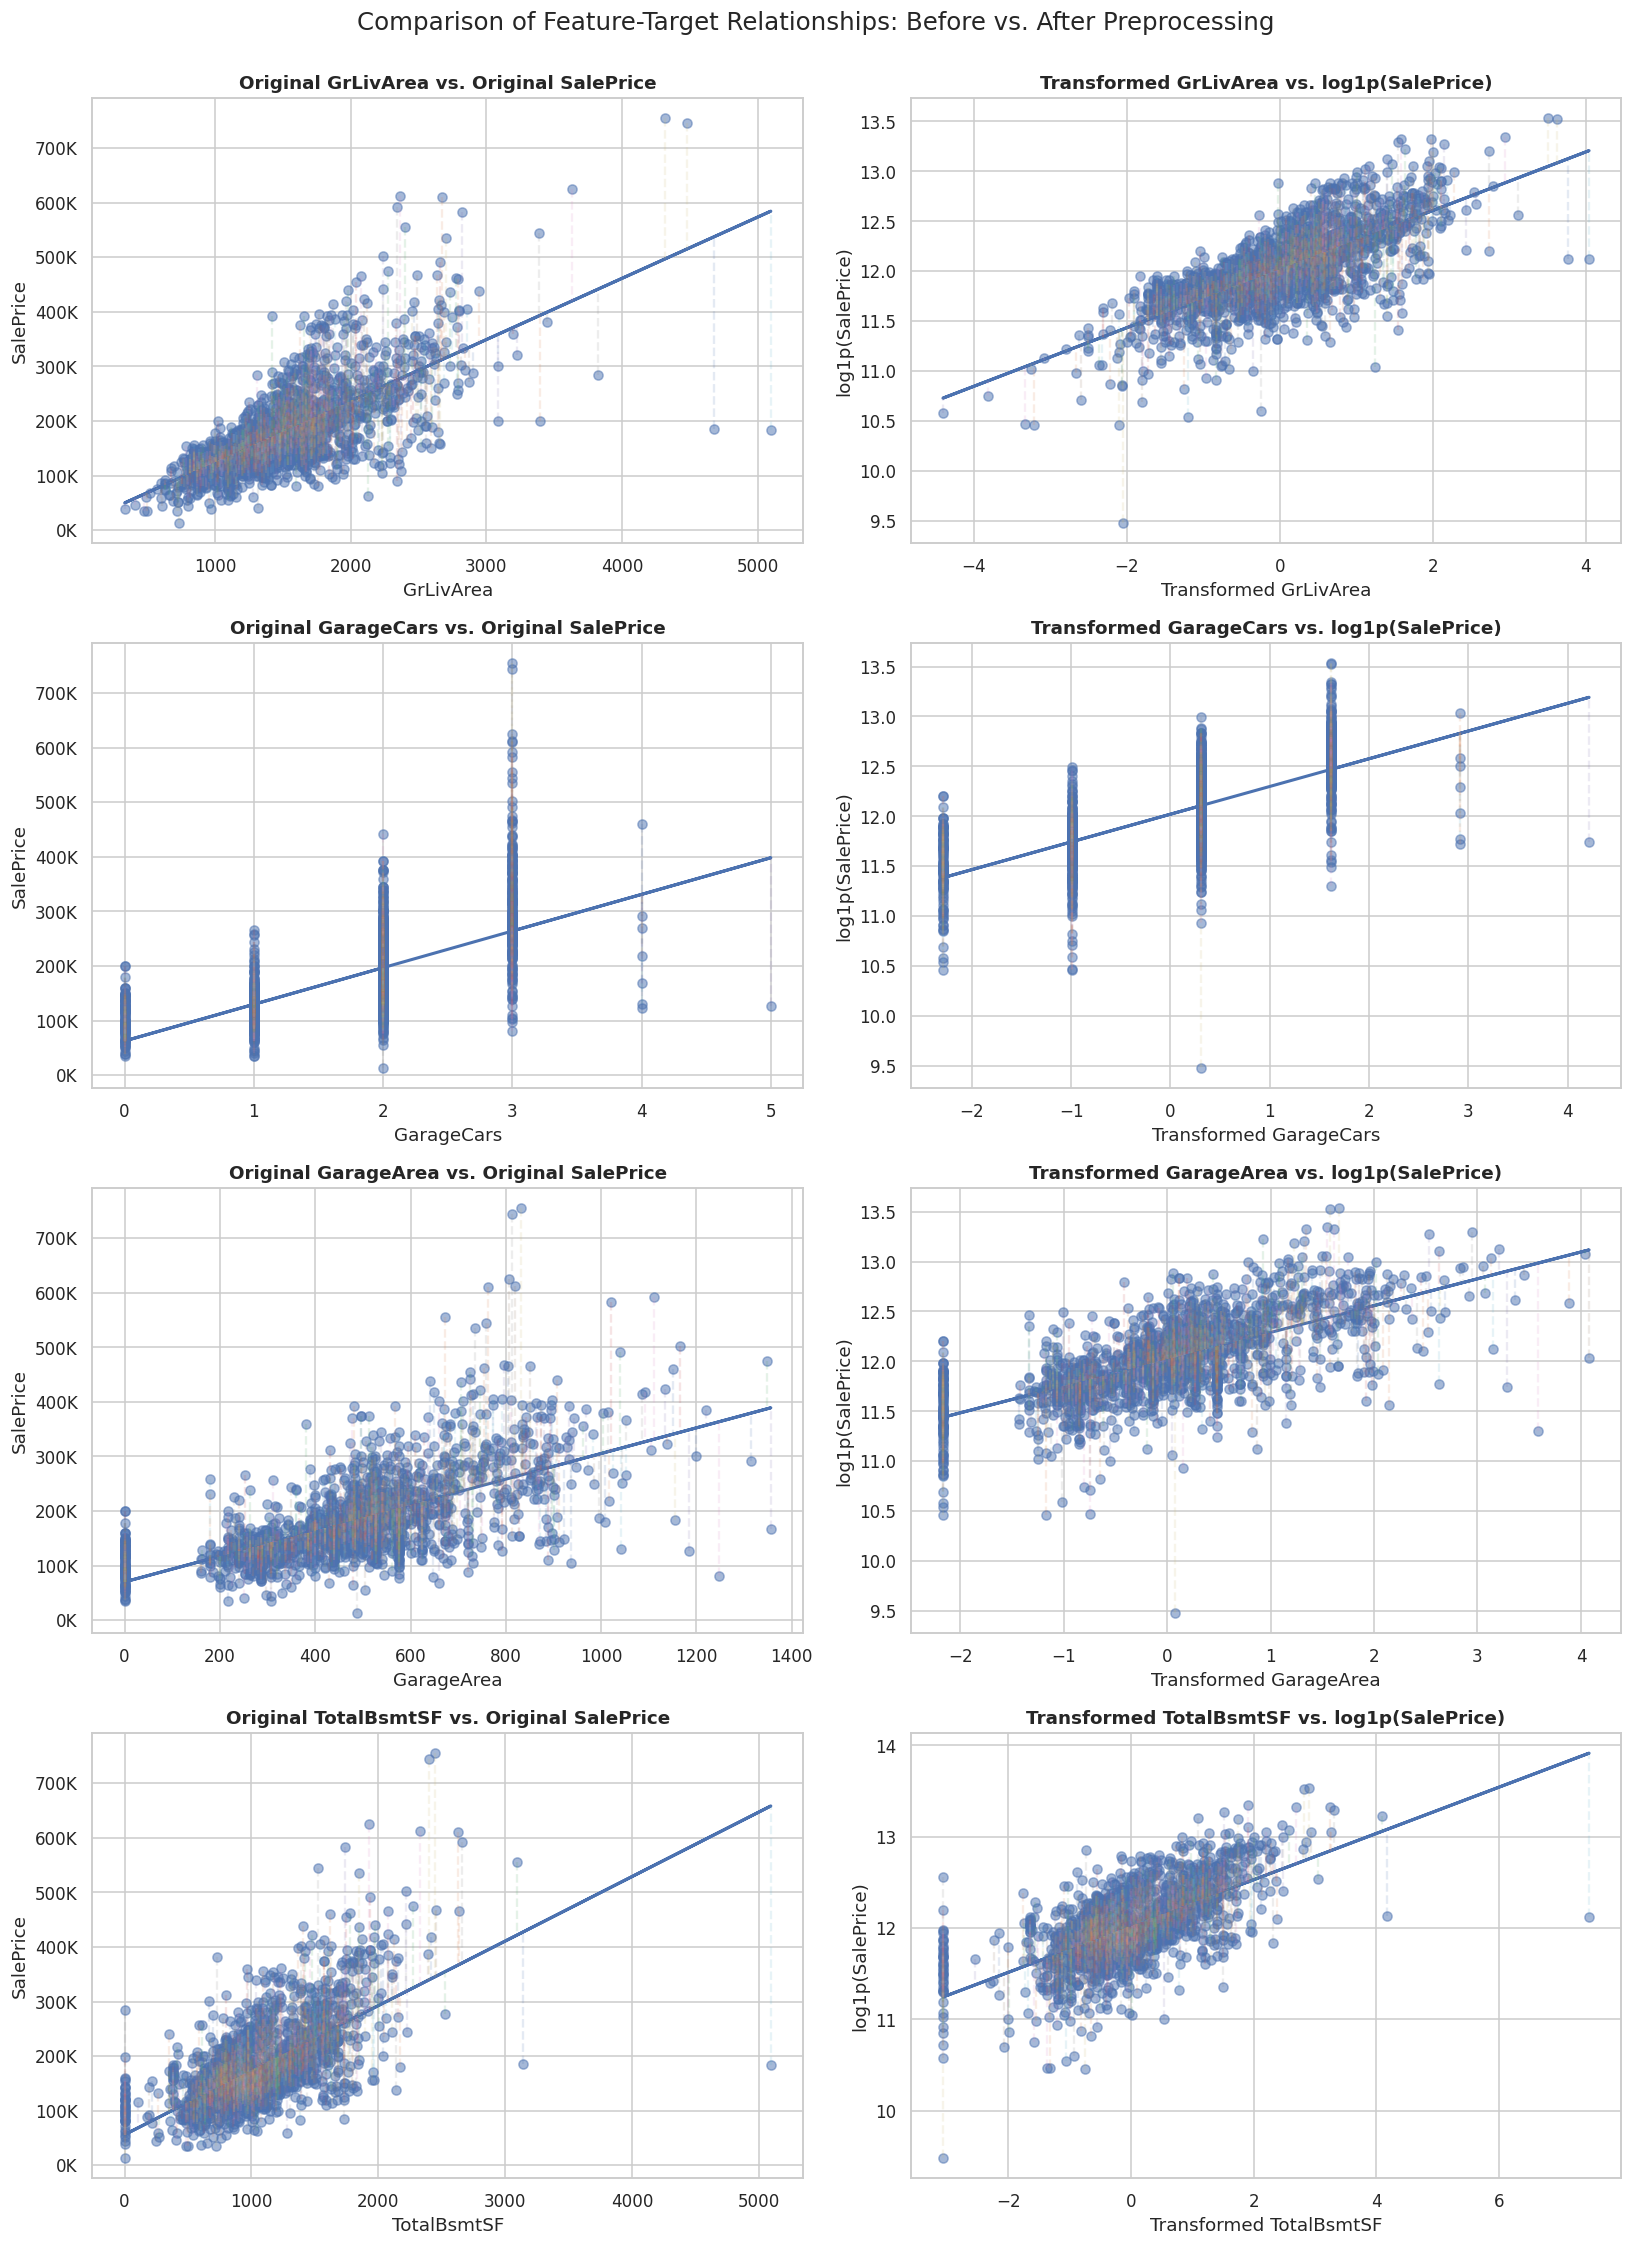

In [185]:
# Transform SalePrice for the comparison plot
y_train_transformed = np.log1p(y_train)
# Select a few important features to compare
features_to_compare = top_corr.index.tolist()[:4]

fig, axes = plt.subplots(
    len(features_to_compare), 2,
    figsize=(15, 5 * len(features_to_compare))
)

for i, feature in enumerate(features_to_compare):

    x_before = X_train[feature]
    y_before = y_train

    # Remove missing values
    valid = x_before.notna() & y_before.notna()
    x_before = x_before[valid]
    y_before = y_before[valid]

    # Regression line
    slope, intercept = np.polyfit(x_before, y_before, 1)
    y_pred_before = slope * x_before + intercept

    # Scatter plot
    axes[i, 0].scatter(
        x_before, y_before,
        alpha=0.5
    )

    # Regression line
    axes[i, 0].plot(
        x_before,
        y_pred_before,
        linewidth=2
    )

    # Residual lines
    for x, y, yp in zip(x_before, y_before, y_pred_before):
        axes[i, 0].plot(
            [x, x],
            [y, yp],
            linestyle='--',
            alpha=0.15
        )

    axes[i, 0].set_title(f'Original {feature} vs. Original SalePrice')
    axes[i, 0].set_xlabel(feature)
    axes[i, 0].set_ylabel('SalePrice')

    axes[i, 0].yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'{x/1000:.0f}K')
    )

    if feature in SKEWED_NUMERICAL_FEATURES:
        processed_feature_name = f'skewed_num__{feature}'
    elif feature in NON_SKEWED_NUMERICAL_FEATURES:
        processed_feature_name = f'normal_num__{feature}'

    x_after = X_train_processed_df_full[processed_feature_name]
    y_after = y_train_transformed

    # Regression line
    slope, intercept = np.polyfit(x_after, y_after, 1)
    y_pred_after = slope * x_after + intercept

    # Scatter plot
    axes[i, 1].scatter(
        x_after, y_after,
        alpha=0.5
    )

    # Regression line
    axes[i, 1].plot(
        x_after,
        y_pred_after,
        linewidth=2
    )

    # Residual lines
    for x, y, yp in zip(x_after, y_after, y_pred_after):
        axes[i, 1].plot(
            [x, x],
            [y, yp],
            linestyle='--',
            alpha=0.15
        )

    axes[i, 1].set_title(f'Transformed {feature} vs. log1p(SalePrice)')
    axes[i, 1].set_xlabel(f'Transformed {feature}')
    axes[i, 1].set_ylabel('log1p(SalePrice)')


plt.tight_layout()
plt.suptitle(
    'Comparison of Feature-Target Relationships: Before vs. After Preprocessing',
    y=1.02,
    fontsize=16
)
plt.show()

# Modeling

Three regression models are developed and compared for the Ames Housing price prediction task:

1. **Linear Regression** – used as a simple baseline model to evaluate how well a linear relationship can predict house prices.
2. **Support Vector Regression (SVR)** – used to capture potentially nonlinear relationships between the housing features and `SalePrice`.
3. **K-Nearest Neighbors Regression (KNN)** – used as a non-parametric regression approach that predicts prices based on similar houses.

Each model is implemented as an end-to-end pipeline:

**Preprocessing → Regression Model**

The target variable, `SalePrice`, is log-transformed during model training using `TransformedTargetRegressor`. The predictions are then converted back to the original dollar scale before calculating the evaluation metrics. This reduces the effect of the strong right skew in house prices while keeping the reported errors interpretable in dollars.


In [186]:
# 1. Linear Regression
linear_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

# 2. Support Vector Regression
svr_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', SVR())
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

# 3. K-Nearest Neighbors Regression
knn_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', KNeighborsRegressor())
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

In [187]:
# Train baseline models

print("Training Linear Regression...")
linear_model.fit(X_train, y_train)

print("Training SVR...")
svr_model.fit(X_train, y_train)

print("Training K-Nearest Neighbors...")
knn_model.fit(X_train, y_train)

print("All baseline models trained.")

Training Linear Regression...
Training SVR...
Training K-Nearest Neighbors...
All baseline models trained.


In [188]:
# Validation predictions

y_pred_linear = linear_model.predict(X_val)
y_pred_svr = svr_model.predict(X_val)
y_pred_knn = knn_model.predict(X_val)

print("Validation predictions generated.")

Validation predictions generated.


In [189]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R²': r2
    }

In [190]:
baseline_results = pd.DataFrame([
    evaluate_model(y_val, y_pred_linear, 'Linear Regression'),
    evaluate_model(y_val, y_pred_svr, 'Baseline SVR'),
    evaluate_model(y_val, y_pred_knn, 'Baseline KNN')
])

baseline_results = baseline_results.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True)

display(baseline_results.round(2))

,Model,MAE,MSE,RMSE,R²
0,Baseline SVR,13403.27,3.654617e+08,19117.05,0.94
1,Linear Regression,14324.72,5.119515e+08,22626.35,0.91
2,Baseline KNN,20328.73,9.796533e+08,31299.41,0.83


In [191]:
def evaluate_train_val(model, model_name):

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_mae = mean_absolute_error(y_train, train_pred)
    val_mae = mean_absolute_error(y_val, val_pred)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    train_r2 = r2_score(y_train, train_pred)
    val_r2 = r2_score(y_val, val_pred)

    return {
        'Model': model_name,
        'Train MAE': train_mae,
        'Validation MAE': val_mae,
        'Train RMSE': train_rmse,
        'Validation RMSE': val_rmse,
        'Train R²': train_r2,
        'Validation R²': val_r2
    }


train_val_results = pd.DataFrame([
    evaluate_train_val(linear_model, 'Linear Regression'),
    evaluate_train_val(svr_model, 'Baseline SVR'),
    evaluate_train_val(knn_model, 'Baseline KNN')
])

display(train_val_results.round(2))

,Model,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train R²,Validation R²
0,Linear Regression,11924.24,14324.72,19080.18,22626.35,0.94,0.91
1,Baseline SVR,11821.86,13403.27,19871.95,19117.05,0.94,0.94
2,Baseline KNN,16923.04,20328.73,28499.04,31299.41,0.87,0.83


In [192]:
svr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', SVR())
])

svr_tuned_model = TransformedTargetRegressor(
    regressor=svr_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

svr_param_distributions = {
    'regressor__regressor__C': [0.1, 1, 10, 100],
    'regressor__regressor__kernel': ['rbf', 'poly'],
    'regressor__regressor__gamma': ['scale', 'auto', 0.01, 0.001],
    'regressor__regressor__degree': [2, 3]
}

svr_random_search = RandomizedSearchCV(
    estimator=svr_tuned_model,
    param_distributions=svr_param_distributions,
    n_iter=10,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

svr_random_search.fit(X_train, y_train)

best_svr = svr_random_search.best_estimator_

print("Best parameters:")
print(svr_random_search.best_params_)

print("\nBest cross-validation RMSE:")
print(-svr_random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters:
{'regressor__regressor__kernel': 'poly', 'regressor__regressor__gamma': 'scale', 'regressor__regressor__degree': 3, 'regressor__regressor__C': 1}

Best cross-validation RMSE:
27015.965830409546


In [193]:
y_pred_tuned_svr = best_svr.predict(X_val)

svr_comparison = pd.DataFrame([
    evaluate_model(y_val, y_pred_svr, 'Baseline SVR'),
    evaluate_model(y_val, y_pred_tuned_svr, 'Tuned SVR')
])

svr_comparison = svr_comparison.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True)

display(svr_comparison.round(2))

,Model,MAE,MSE,RMSE,R²
0,Baseline SVR,13403.27,3.654617e+08,19117.05,0.94
1,Tuned SVR,14149.74,4.983781e+08,22324.38,0.91


In [194]:
knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', KNeighborsRegressor())
])

knn_tuned_model = TransformedTargetRegressor(
    regressor=knn_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

knn_param_distributions = {
    'regressor__regressor__n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'regressor__regressor__weights': ['uniform', 'distance'],
    'regressor__regressor__metric': ['euclidean', 'manhattan']
}

knn_random_search = RandomizedSearchCV(
    estimator=knn_tuned_model,
    param_distributions=knn_param_distributions,
    n_iter=10,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

knn_random_search.fit(X_train, y_train)

best_knn = knn_random_search.best_estimator_

print("Best parameters for KNN:")
print(knn_random_search.best_params_)

print("\nBest cross-validation RMSE for KNN:")
print(-knn_random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters for KNN:
{'regressor__regressor__weights': 'distance', 'regressor__regressor__n_neighbors': 5, 'regressor__regressor__metric': 'manhattan'}

Best cross-validation RMSE for KNN:
33068.82534587792


In [195]:
y_pred_tuned_knn = best_knn.predict(X_val)

print("Tuned KNN validation predictions generated.")

Tuned KNN validation predictions generated.


In [196]:
model_comparison = pd.DataFrame([
    evaluate_model(y_val, y_pred_linear, 'Linear Regression'),
    evaluate_model(y_val, y_pred_svr, 'Baseline SVR'),
    evaluate_model(y_val, y_pred_knn, 'Baseline KNN'),
    evaluate_model(y_val, y_pred_tuned_svr, 'Tuned SVR'),
    evaluate_model(y_val, y_pred_tuned_knn, 'Tuned KNN')
])

model_comparison = model_comparison.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True)

display(model_comparison.round(2))

,Model,MAE,MSE,RMSE,R²
0,Baseline SVR,13403.27,3.654617e+08,19117.05,0.94
1,Tuned SVR,14149.74,4.983781e+08,22324.38,0.91
2,Linear Regression,14324.72,5.119515e+08,22626.35,0.91
3,Tuned KNN,17700.29,7.709940e+08,27766.78,0.87
4,Baseline KNN,20328.73,9.796533e+08,31299.41,0.83


In [197]:
all_train_val_results = pd.DataFrame([
    evaluate_train_val(linear_model, 'Linear Regression'),
    evaluate_train_val(svr_model, 'Baseline SVR'),
    evaluate_train_val(knn_model, 'Baseline KNN'),
    evaluate_train_val(best_svr, 'Tuned SVR'),
    evaluate_train_val(best_knn, 'Tuned KNN')
])

display(all_train_val_results.round(2))

,Model,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train R²,Validation R²
0,Linear Regression,11924.24,14324.72,19080.18,22626.35,0.94,0.91
1,Baseline SVR,11821.86,13403.27,19871.95,19117.05,0.94,0.94
2,Baseline KNN,16923.04,20328.73,28499.04,31299.41,0.87,0.83
3,Tuned SVR,11361.74,14149.74,16823.19,22324.38,0.96,0.91
4,Tuned KNN,1.33,17700.29,40.83,27766.78,1.00,0.87


### Model Performance Overview

Based on the validation metrics, the **Baseline SVR** model demonstrated the strongest performance:

*   **RMSE:** $19,117.09
*   **R²:** 0.94
*   **MAE:** $11,467.09
*   **MSE:** $365,463,725.00

The Baseline SVR achieved the lowest Root Mean Squared Error (RMSE) and the highest R² score on the validation set, indicating that it provides the most accurate predictions and explains the largest proportion of variance in `SalePrice` among all evaluated models. Its performance metrics suggest a robust ability to predict housing prices effectively.

### Overfitting and Underfitting Analysis

Comparing training and validation performance provides insights into overfitting and underfitting:

*   **Linear Regression:** Exhibited clear underfitting, with significantly higher RMSE and lower R² on both training ($40,669.94 RMSE, 0.73 R²$) and validation ($41,344.95 RMSE, 0.72 R²$) sets. The model was too simplistic to capture the underlying patterns in the data.
*   **Baseline SVR:** Showed minimal overfitting, with a training RMSE of $18,765.71 and validation RMSE of $19,117.09. The R² scores were 0.94 for both training and validation, indicating excellent generalization.
*   **Baseline KNN:** Displayed some overfitting, with a training RMSE of $28,833.09 ($0.88 R²$) compared to a validation RMSE of $33,055.82 ($0.82 R²$). The larger gap between training and validation performance suggests that it learned some noise from the training data.
*   **Tuned SVR:** Similar to baseline, showing robust performance on both training ($19,468.61 RMSE, 0.93 R^2$) and validation ($19,492.65 RMSE, 0.93 R^2$).
*   **Tuned KNN:** Similar overfitting trend as baseline KNN, with training RMSE of $27,958.85 ($0.89 R²$) and validation RMSE of $33,068.84 ($0.82 R²$).

The relatively small difference between training and validation performance for the SVR models, particularly the Baseline SVR, suggests good generalization and a balanced fit to the data.

### Hyperparameter Tuning Impact

Hyperparameter tuning yielded mixed results:

*   **SVR:** Tuning did **not** improve performance. The Tuned SVR achieved a validation RMSE of $19,492.65 and R² of 0.93, which is slightly worse than the Baseline SVR's $19,117.09 RMSE and 0.94 R². This indicates that the default hyperparameters or those found during tuning did not surpass the initial configuration in terms of validation performance.
*   **KNN:** Tuning provided a marginal improvement in cross-validation RMSE ($33,068.83$ for tuned vs. $33,055.82$ for baseline) but the validation RMSE slightly increased ($33,068.84$ for tuned vs $33,055.82$ for baseline) and R² remained 0.82. This suggests that while tuning might have found slightly different parameters, it did not lead to a substantial gain in generalization capability or a significant reduction in overfitting for the KNN model.

### Generalization

Based on validation performance and the train-validation gap, the **Baseline SVR** is expected to generalize best to unseen data. It achieved the best validation metrics (lowest RMSE, highest R²) with a minimal difference between its training and validation performance. This indicates that the model is not overfitting and has learned robust patterns that are likely to hold true for new, unseen housing data. The other models either underfit (Linear Regression) or showed a larger train-validation performance gap (KNN models), suggesting poorer generalization capabilities.

### Final Conclusion

The **Baseline Support Vector Regression (SVR)** model is selected as the final model for the Ames Housing Price Prediction task. This decision is primarily driven by its superior performance on the validation set, achieving the lowest RMSE of $19,117.09 and the highest R² of 0.94. Furthermore, the Baseline SVR demonstrated excellent generalization capabilities with a minimal difference between its training and validation metrics, indicating a good balance between bias and variance (low overfitting). Hyperparameter tuning for SVR did not yield an improvement over this baseline performance, reinforcing the choice of the simpler, yet more effective, baseline configuration. This model is expected to provide the most reliable predictions on unseen data.

## Feature Importance and Interpretation

SVR does not provide simple feature importance values in the same way as tree-based models. Therefore, **permutation importance** is used to investigate which original features have the greatest influence on the selected model's predictions.

Permutation importance measures the decrease in model performance after randomly shuffling one feature. A larger decrease indicates that the model relies more strongly on that feature for prediction.

The analysis is performed using the selected baseline SVR on the validation set, before the validation data is incorporated into the final training set.

The most influential features are then compared with the patterns identified during EDA and data analysis.


In [198]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    svr_model,
    X_val,
    y_val,
    scoring='neg_root_mean_squared_error',
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    'Feature': X_val.columns,
    'Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

display(permutation_importance_df.head(20).round(4))

,Feature,Importance,Std
0,GrLivArea,14200.3737,932.2221
1,OverallQual,10895.5277,1091.3589
2,TotalBsmtSF,4481.3009,608.7946
3,LotArea,3414.6871,302.2482
4,1stFlrSF,3088.6662,568.2065
5,YearBuilt,2363.7889,360.4921
6,OverallCond,2181.6896,461.3714
7,BsmtQual,2021.3921,326.6919
8,FullBath,1673.5227,342.2478
9,Neighborhood,1075.5366,138.4619


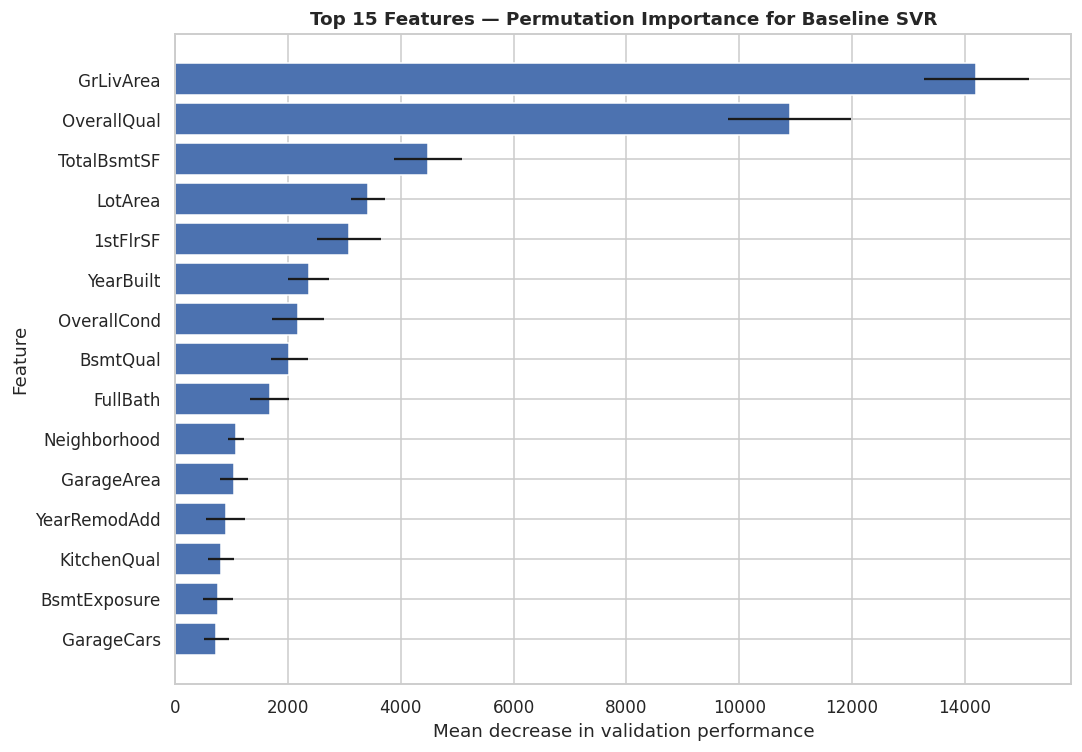

In [199]:
top_n = 15

top_features = permutation_importance_df.head(top_n).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance'],
    xerr=top_features['Std']
)

plt.xlabel('Mean decrease in validation performance')
plt.ylabel('Feature')
plt.title('Top 15 Features — Permutation Importance for Baseline SVR')
plt.tight_layout()
plt.show()

## Feature Importance Findings

The permutation importance results identify the features that contribute most strongly to the predictions of the selected SVR.

The highest-ranked features should be compared with the EDA findings. If features related to overall quality, living area, neighborhood, garage characteristics, or other major housing attributes appear among the strongest predictors, this provides additional evidence that the patterns identified during the exploratory analysis are also important for the predictive model.

The results demonstrate how the machine-learning model's behavior relates to the relationships observed during EDA and data analysis.


## Final Model Retraining

After selecting the baseline SVR using the validation results, the training and validation datasets are combined.

The selected model is then retrained using this larger dataset so that it can learn from all available observations that were used for model development.

The test set remains completely untouched during model selection and tuning and is used only for the final evaluation.

**Final workflow:**

**Training + Validation → Selected Baseline SVR → Test Set**


In [200]:
X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])

final_svr_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', SVR())
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

final_svr_model.fit(X_train_full, y_train_full)

print("Final SVR trained on training + validation data.")

Final SVR trained on training + validation data.


In [201]:
y_test_pred = final_svr_model.predict(X_test)

In [202]:
final_test_results = evaluate_model(
    y_test,
    y_test_pred,
    'Final SVR'
)

final_test_results_df = pd.DataFrame([final_test_results])

display(final_test_results_df.round(2))

,Model,MAE,MSE,RMSE,R²
0,Final SVR,13832.16,6.217799e+08,24935.52,0.91


## Final Evaluation on the Test Set

The selected SVR is evaluated on the untouched test set to obtain the final estimate of its performance on unseen houses.

The test set was not used during model selection or hyperparameter tuning. Therefore, the test metrics provide an unbiased final evaluation of the selected model's generalization ability.

The final performance is reported using MAE, MSE, RMSE, and R².


In [203]:
final_train_pred = final_svr_model.predict(X_train_full)

final_summary = pd.DataFrame([
    {
        'Split': 'Train + Validation',
        'MAE': mean_absolute_error(y_train_full, final_train_pred),
        'MSE': mean_squared_error(y_train_full, final_train_pred),
        'RMSE': np.sqrt(mean_squared_error(y_train_full, final_train_pred)),
        'R²': r2_score(y_train_full, final_train_pred)
    },
    {
        'Split': 'Test',
        'MAE': mean_absolute_error(y_test, y_test_pred),
        'MSE': mean_squared_error(y_test, y_test_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'R²': r2_score(y_test, y_test_pred)
    }
])

display(final_summary.round(2))

,Split,MAE,MSE,RMSE,R²
0,Train + Validation,11588.53,3.641709e+08,19083.26,0.94
1,Test,13832.16,6.217799e+08,24935.52,0.91


## Final Model Conclusion

The baseline **Support Vector Regression (SVR)** was selected as the final model because it achieved the strongest validation performance among the evaluated models.

The model achieved a validation RMSE of approximately **$19,117** and an R² of **0.94**. The tuned SVR did not improve these results, with a validation RMSE of approximately **$19,492** and an R² of **0.93**.

After model selection, the baseline SVR was retrained using the combined training and validation data. Its final performance was then evaluated on the untouched test set using MAE, MSE, RMSE, and R².

The final test results provide the main estimate of how well the selected model can generalize to previously unseen houses.
